# 02 · Exploratory Data Analysis (EDA)
### BNI Ecosystem & Growth Intelligence — Kelompok 8 · ODP BNI Data Analytics Batch 2

| # | Notebook | Isi |
|---|---|---|
| 01 | Dataset Generation & Validation | data sintetis v8 + validasi 7 lapis |
| **02** | **EDA** | **notebook ini — persiapan data, eksplorasi, temuan, kontrak fitur** |
| 03 | Feature Engineering | feature store, uji nilai fitur |
| 04 | Modelling | model dasar risiko, peluang, anomali |
| 05 | Modelling Optimization | tuning, cost-sensitive, kalibrasi |
| 06 | Model Evaluation | evaluasi terhadap ground truth & biaya bisnis |
| 07 | Post-evaluation & Remodelling | perbaikan berdasarkan analisis kesalahan |

## Apa yang membuat EDA ini berbeda
EDA yang umum berhenti di "grafik yang menarik". EDA ini dirancang sebagai **jembatan yang bisa diaudit** ke feature engineering, dengan lima prinsip:

1. **Anti-kebocoran sejak awal.** Sebelum melihat label, 20% nasabah berlabel dikunci sebagai *holdout* (dipisah per grup usaha). Semua analisis yang melibatkan label hanya memakai porsi *development*. Alasannya: memilih fitur dengan melihat seluruh data adalah bentuk kebocoran yang paling sering terjadi di riset ML (Kapoor & Narayanan, 2023; Kaufman dkk., 2012).
2. **Setiap temuan = hipotesis yang diuji.** Tiap temuan punya uji statistik, ukuran efek, dan rentang kepercayaan bootstrap. Seluruh nilai p dikoreksi bersama dengan Benjamini–Hochberg (1995), supaya banyaknya grafik tidak menghasilkan "temuan" kebetulan.
3. **Teknik yang dipilih karena cocok dengan masalahnya**, bukan sekadar tren:
   - rasio relatif-peer untuk mengatasi paradoks Simpson;
   - regresor **hari raya bergerak** untuk Lebaran (Bell & Hillmer, 1983);
   - deteksi **ambang** konsentrasi pembeli dengan regresi tersegmentasi (Muggeo, 2003);
   - **dosis–respons dengan kontrol plasebo** untuk efek berantai anchor (gagasan DebtRank, Battiston dkk., 2012);
   - korelasi ξ Chatterjee (2021) untuk penyaringan fitur;
   - **uji dua sampel berbasis classifier** untuk pergeseran nasabah → prospect (Lopez-Paz & Oquab, 2017);
   - **confident learning** untuk audit label (Northcutt dkk., 2021);
   - deteksi negasi gaya NegEx untuk catatan RM (Chapman dkk., 2001);
   - untuk anomali: koreksi kontekstual, pemisahan spike vs perubahan level (CUSUM / change point; Page, 1954; Killick dkk., 2012), **peta sinyal × jenis kejadian** dengan uji trivialitas aturan satu baris (Wu & Keogh, 2021), dan *event study* lead time.
4. **Jujur terhadap hasil negatif.** Fitur yang ternyata lemah (misalnya homophily risiko di jaringan) dilaporkan apa adanya, supaya notebook 03 tidak membuang waktu.
5. **Hasil akhirnya kontrak fitur.** `feature_contract.csv` mencatat untuk tiap fitur: rumus, temuan sumber, bukti, jendela waktu, ketersediaan untuk nasabah dan prospect, serta catatan kebocoran. Notebook 03 tinggal membaca berkas ini.

**Aturan data (dari notebook 01):** hanya kolom `peran = fitur` di `data_dictionary.csv` yang boleh menjadi fitur. Tabel `gt_*` dan `outcome_product_adoption` **hanya dipakai untuk evaluasi**; setiap pemakaiannya di notebook ini ditandai kotak **🔎 Cek ground truth (evaluasi saja)**. Kolom proxy-label (`collectibility`, `max_dpd_12m`, `watchlist_flag`, `restructuring_flag`) tidak disentuh sama sekali.

**Daftar isi**
- A. Setup
- B. Inventaris data & pagar kolom
- C. Protokol anti-kebocoran (kunci holdout)
- D. Persiapan data: kualitas, missing values, outlier, encoding
- E. Profil umum
- F. Sepuluh temuan (F1–F9) + F10 EDA anomali
- G. Audit lanjutan: penyaringan fitur, pergeseran prospect, audit label
- H. Ringkasan hipotesis, kontrak fitur, langkah berikutnya
- Daftar pustaka

## A. Setup
`PROJECT_ROOT` dicari dari `pyproject.toml` (sama seperti notebook 01). Data dibaca dari `data/raw/`, hasil disimpan ke `outputs/02_eda/` dan `data/interim/`. Pustaka yang dipakai sama dengan notebook 01: pandas, numpy, scipy, scikit-learn, networkx, matplotlib — tidak perlu instalasi tambahan.

In [1]:
import json, re, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import networkx as nx
from scipy import stats
from sklearn.metrics import roc_auc_score, normalized_mutual_info_score
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 80)

SEED = 2026
CUTOFF = pd.Timestamp('2026-06-30')

def find_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / 'pyproject.toml').exists():
            return p
    return start

PROJECT_ROOT = find_root()
RAW = next((p for p in [PROJECT_ROOT / 'data' / 'raw', PROJECT_ROOT / 'csv', Path('csv'), Path('/content/data/raw'), Path('/content/csv')] if (p / 'companies.csv').exists()), None)
assert RAW is not None, 'companies.csv tidak ditemukan — letakkan CSV v8 di data/raw/'
OUT = PROJECT_ROOT / 'outputs' / '02_eda'; FIG = OUT / 'figures'; INTERIM = PROJECT_ROOT / 'data' / 'interim'
for d in (OUT, FIG, INTERIM): d.mkdir(parents=True, exist_ok=True)
print('PROJECT_ROOT :', PROJECT_ROOT); print('data mentah  :', RAW); print('output       :', OUT)

# --- gaya grafik: sama dengan notebook 01 (palet sudah dicek aman buta warna) ---
C = dict(s1='#2a78d6', s2='#eb6834', s3='#1baf7a', s4='#eda100', s5='#e87ba4', s6='#008300', s7='#6250d6', s8='#e34948',
         ink='#0b0b0b', ink2='#52514e', muted='#898781', grid='#e1e0d9', axis='#c3c2b7', surface='#fcfcfb')
RISK_COL = {'Low': C['s1'], 'Medium': C['s4'], 'High': C['s8']}
RISK_ORDER = ['Low', 'Medium', 'High']
mpl.rcParams.update({'figure.facecolor': C['surface'], 'axes.facecolor': C['surface'], 'axes.edgecolor': C['axis'], 'axes.linewidth': .8,
                     'axes.grid': True, 'grid.color': C['grid'], 'grid.linewidth': .6, 'axes.axisbelow': True, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
                     'axes.labelcolor': C['ink2'], 'axes.labelsize': 9, 'xtick.color': C['muted'], 'ytick.color': C['muted'],
                     'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.frameon': False, 'legend.fontsize': 8, 'lines.linewidth': 2,
                     'figure.dpi': 110, 'text.color': C['ink']})

def save_fig(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())

# --- alat statistik kecil yang dipakai berulang ---
rng_global = np.random.default_rng(SEED)

def auc(y, x):
    """AUC dengan baris NaN dibuang; > 0,5 berarti nilai besar → kelas positif."""
    y, x = np.asarray(y), np.asarray(x, float); m = ~np.isnan(x)
    return roc_auc_score(y[m], x[m])

def boot_ci(stat, *arrays, B=500, seed=SEED, alpha=.05):
    """Rentang kepercayaan bootstrap persentil (Efron, 1979) untuk statistik pada array berpasangan."""
    r = np.random.default_rng(seed); n = len(arrays[0]); vals = []
    for _ in range(B):
        ix = r.integers(0, n, n)
        try: vals.append(stat(*[np.asarray(a)[ix] for a in arrays]))
        except ValueError: pass
    return np.quantile(vals, [alpha / 2, 1 - alpha / 2])

def xi_corr(x, y, seed=SEED):
    """Koefisien ξ Chatterjee (2021): 0 = independen, 1 = y fungsi dari x; menangkap hubungan tidak monoton."""
    x, y = np.asarray(x, float), np.asarray(y, float); n = len(x)
    o = np.lexsort((np.random.default_rng(seed).random(n), x)); yo = y[o]
    r = stats.rankdata(yo, method='max'); l = stats.rankdata(-yo, method='max')
    return 1 - n * np.abs(np.diff(r)).sum() / (2 * (l * (n - l)).sum())

def robust_z(s, groups=None, ref_mask=None):
    """z robust = (x − median) / (1,4826·MAD), opsional per kelompok peer (Leys dkk., 2013).
    Median & MAD hanya dihitung dari baris ref_mask (mis. tanpa holdout) agar tidak bocor."""
    s = pd.Series(s, dtype=float); ref = s if ref_mask is None else s.where(ref_mask)
    if groups is None:
        med = ref.median(); mad = (ref - med).abs().median(); return (s - med) / (1.4826 * mad)
    g = [groups[c] for c in groups] if isinstance(groups, pd.DataFrame) else groups
    med = ref.groupby(g).transform('median')
    mad = (ref - med).abs().groupby(g).transform('median')
    return (s - med) / (1.4826 * mad.replace(0, np.nan))

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z ** 2 / n; c = (p + z ** 2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return c - h, c + h

HYP = []   # buku besar hipotesis: diisi di setiap temuan, dikoreksi BH di bagian H
def record(hid, temuan, uji, statistik, p, data, fitur, gt=False, expect_null=False):
    HYP.append(dict(id=hid, temuan=temuan, uji=uji, statistik=statistik, p=p, data=data, fitur_turunan=fitur, pakai_gt=gt, harapan_nol=expect_null))

PROJECT_ROOT : /home/claude/proj
data mentah  : /home/claude/proj/data/raw
output       : /home/claude/proj/outputs/02_eda


## B. Inventaris data & pagar kolom
Langkah pertama: membaca kamus data dan **membuat daftar kolom yang boleh dipakai sebagai fitur secara terprogram**. Dengan begitu kolom proxy-label atau ground truth tidak bisa "terselip" ke analisis fitur.

In [2]:
dd = pd.read_csv(RAW / 'data_dictionary.csv')
inv = (dd.groupby('tabel', sort=False)
         .agg(kolom=('kolom', 'size'), fitur=('peran', lambda s: (s == 'fitur').sum()), peran=('peran', lambda s: ', '.join(sorted(set(s)))))
         .reset_index())
inv['baris'] = [sum(1 for _ in open(RAW / f'{t}.csv', encoding='utf-8')) - 1 for t in inv.tabel]
inv['dipakai_di_EDA_untuk'] = np.where(inv.peran.str.contains('ground'), 'evaluasi saja (🔎)',
                               np.where(inv.peran.str.contains('label') & ~inv.peran.str.contains('proxy'), 'label (porsi dev saja)',
                               np.where(inv.peran.str.contains('proxy'), 'fitur, kecuali 4 kolom proxy-label',
                               np.where(inv.peran.str.contains('outcome'), 'tidak dipakai (setelah cutoff)',
                               np.where(inv.peran.str.contains('referensi') & ~inv.peran.str.contains('fitur'), 'referensi', 'eksplorasi & fitur')))))
FEATURE_COLS = {t: g.kolom.tolist() for t, g in dd[dd.peran == 'fitur'].groupby('tabel')}
FORBIDDEN = dd[dd.peran.isin(['proxy-label', 'label', 'ground-truth', 'outcome'])][['tabel', 'kolom', 'peran']]
print(f'{len(inv)} tabel · {inv.baris.sum():,} baris · {sum(map(len, FEATURE_COLS.values()))} kolom berperan fitur')
print('Kolom terlarang sebagai fitur:', ', '.join(FORBIDDEN[FORBIDDEN.peran != 'ground-truth'].kolom), '+ seluruh kolom gt_*')
display(inv[['tabel', 'baris', 'kolom', 'fitur', 'peran', 'dipakai_di_EDA_untuk']])

27 tabel · 1,167,727 baris · 96 kolom berperan fitur
Kolom terlarang sebagai fitur: risk_class, collectibility, max_dpd_12m, restructuring_flag, watchlist_flag, observation_end, adopted_jul_sep_2026, deal_value_idr_mn + seluruh kolom gt_*


,tabel,baris,kolom,fitur,peran,dipakai_di_EDA_untuk
0,companies,2000,20,16,"fitur, id",eksplorasi & fitur
1,financials,3672,12,11,"fitur, id",eksplorasi & fitur
2,transactions,1078362,10,7,"fitur, id",eksplorasi & fitur
3,product_master,8,8,0,"id, referensi",referensi
4,product_holdings,4453,8,6,"fitur, id",eksplorasi & fitur
5,geography,40,11,10,"fitur, id",eksplorasi & fitur
6,branches,40,6,4,"fitur, id",eksplorasi & fitur
7,risk_labels,1000,3,0,"id, label",label (porsi dev saja)
8,credit_facilities,1000,10,5,"fitur, id, proxy-label","fitur, kecuali 4 kolom proxy-label"
9,network_entities,4800,8,5,"fitur, id",eksplorasi & fitur


In [3]:
rd = lambda t, **k: pd.read_csv(RAW / f'{t}.csv', **k)
co = rd('companies', parse_dates=['onboarding_date'])
fin = rd('financials'); rl = rd('risk_labels'); cf = rd('credit_facilities')
rel = rd('relationships', parse_dates=['relationship_start', 'relationship_end'])
ne = rd('network_entities'); geo = rd('geography'); br = rd('branches')
ph = rd('product_holdings'); pm = rd('product_master'); notes = rd('rm_visit_notes'); imap = rd('issue_product_map')
t0 = time.time()
tx_raw = rd('transactions', parse_dates=['transaction_date'])
print(f'transaksi: {len(tx_raw):,} baris dibaca dalam {time.time() - t0:.1f} dtk')
cf = cf.drop(columns=[c for c in ['collectibility', 'max_dpd_12m', 'restructuring_flag', 'watchlist_flag'] if c in cf])   # pagar proxy-label
print('kolom credit_facilities yang tersisa:', list(cf.columns))

transaksi: 1,078,362 baris dibaca dalam 1.5 dtk
kolom credit_facilities yang tersisa: ['company_id', 'facility_type', 'limit_idr_bn', 'outstanding_idr_bn', 'utilization', 'policy_restriction']


## C. Protokol anti-kebocoran: kunci *holdout* sebelum melihat label
Data berlabel hanya 1.000 nasabah kredit. Kalau kita memilih fitur, ambang, atau aturan sambil melihat **seluruh** label, nilai evaluasi nanti akan terlalu optimistis (seleksi fitur yang memakai data latih dan uji sekaligus termasuk dalam taksonomi kebocoran Kapoor & Narayanan, 2023). Karena itu:

- **20% nasabah berlabel dikunci** sebagai `holdout`, dibagi secara bertingkat menurut kelas risiko. Anggota grup usaha yang sama selalu masuk sisi yang sama (`StratifiedGroupKFold`), karena kesehatan anggota grup saling berkorelasi.
- Semua analisis yang memakai label (F1–F3, G1, G3) hanya memakai porsi `dev`.
- Analisis tanpa label (musiman, jaringan, geografi, teks) boleh memakai semua perusahaan.
- Statistik peer (median/MAD per industri × ukuran) dihitung **tanpa** baris holdout.
- Pembagian disimpan ke `data/interim/split.csv` dan **wajib dipakai ulang** di notebook 03–06.

In [4]:
lab = rl.merge(co[['company_id', 'business_group', 'industry', 'size_class_reference']], on='company_id')
groups = lab.business_group.fillna(lab.company_id)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_ix, hold_ix = next(sgkf.split(lab, lab.risk_class, groups))
split = pd.Series('unlabeled', index=co.company_id, name='split')
split[lab.company_id.iloc[dev_ix]] = 'dev'; split[lab.company_id.iloc[hold_ix]] = 'holdout'
split.reset_index().to_csv(INTERIM / 'split.csv', index=False)
DEV = split.index[split == 'dev']; HOLD = split.index[split == 'holdout']
NOT_HOLD = split != 'holdout'          # penanda baris yang boleh dipakai untuk statistik peer

tab = pd.crosstab(lab.company_id.map(split), lab.risk_class)[RISK_ORDER]
tab['n'] = tab.sum(axis=1); tab['% High'] = (100 * tab.High / tab.n).round(1)
grp_cross = lab.assign(s=lab.company_id.map(split)).dropna(subset=['business_group']).groupby('business_group').s.nunique().gt(1).sum()
print(f'dev {len(DEV)} · holdout {len(HOLD)} · tanpa label {int((split == "unlabeled").sum())} · grup usaha yang terbelah: {grp_cross}')
display(tab)

dev 800 · holdout 200 · tanpa label 1000 · grup usaha yang terbelah: 0


risk_class,Low,Medium,High,n,% High
company_id,,,,,
dev,491,200,109,800,13.6
holdout,123,49,28,200,14.0


## D. Persiapan data
Rubrik Hari 2 menilai kebersihan data, penanganan *missing values* dan *outlier*, serta *encoding*. Setiap keputusan di bawah dicatat dalam **log pembersihan** beserta alasannya, sehingga bisa diulang dan diaudit.

### D1. Kualitas transaksi
Notebook 01 sengaja menanam masalah kualitas data (datasheet bagian 4). Di sini masalah itu dideteksi tanpa mengintip parameter generator.

In [5]:
tx = tx_raw.copy(); log = []
def note(masalah, n, tindakan, alasan, base=len(tx_raw)):
    log.append(dict(masalah=masalah, baris=int(n), persen=round(100 * n / base, 3), tindakan=tindakan, alasan=alasan))

dup_id = tx.transaction_id.duplicated(keep='first')
identical = tx[tx.transaction_id.isin(tx.transaction_id[dup_id])].drop_duplicates().transaction_id.duplicated().sum()
note('transaction_id ganda (seluruh kolom identik)', dup_id.sum(), 'hapus salinan', f'duplikat murni (baris berbeda isi: {identical}) → menggelembungkan omzet & frekuensi')
tx = tx[~dup_id]
zero = tx.amount_idr_mn.le(0)
note('nominal = 0', zero.sum(), 'hapus', 'bukan aliran dana; mengganggu log-transform & rata-rata')
tx = tx[~zero]
late = tx.transaction_date.gt(CUTOFF)
note('tanggal setelah cutoff 30 Jun 2026', late.sum(), 'hapus bila ada', 'pagar kebocoran waktu'); tx = tx[~late]
na_ch = tx.channel.isna()
note('channel kosong', na_ch.sum(), "isi kategori 'Tidak tercatat'", 'missing administratif; dicek MCAR di D2')
na_cp = tx.counterparty_id.isna()
note('counterparty_id kosong', na_cp.sum(), 'pertahankan; keluarkan dari hitungan konsentrasi', 'nominal tetap sah untuk total omzet')
tx['channel'] = tx.channel.fillna('Tidak tercatat')
tx['ym'] = tx.transaction_date.dt.to_period('M'); tx['day'] = tx.transaction_date.dt.day

f_chk = fin.assign(gap=(fin.total_assets_idr_bn - fin.total_debt_idr_bn - fin.total_equity_idr_bn).abs() / fin.total_assets_idr_bn)
note('neraca tidak seimbang (|A − L − E| > 1% aset)', (f_chk.gap > .01).sum(), 'tandai', 'identitas akuntansi', base=len(fin))
note('ebit_idr_bn kosong', fin.ebit_idr_bn.isna().sum(), 'biarkan NaN + indikator; dicek MCAR', 'lihat D2', base=len(fin))
note('interest_expense_idr_bn kosong', fin.interest_expense_idr_bn.isna().sum(), 'biarkan NaN + indikator; dicek MCAR', 'lihat D2', base=len(fin))
cleaning_log = pd.DataFrame(log); cleaning_log.to_csv(OUT / 'cleaning_log.csv', index=False)
print(f'transaksi bersih: {len(tx):,} baris ({len(tx_raw) - len(tx):,} dibuang)')
display(cleaning_log)

transaksi bersih: 1,075,032 baris (3,330 dibuang)


,masalah,baris,persen,tindakan,alasan
0,transaction_id ganda (seluruh kolom identik),3225,0.299,hapus salinan,duplikat murni (baris berbeda isi: 0) → menggelembungkan omzet & frekuensi
1,nominal = 0,105,0.010,hapus,bukan aliran dana; mengganggu log-transform & rata-rata
2,tanggal setelah cutoff 30 Jun 2026,0,0.000,hapus bila ada,pagar kebocoran waktu
3,channel kosong,5367,0.498,isi kategori 'Tidak tercatat',missing administratif; dicek MCAR di D2
4,counterparty_id kosong,10959,1.016,pertahankan; keluarkan dari hitungan konsentrasi,nominal tetap sah untuk total omzet
5,neraca tidak seimbang (|A − L − E| > 1% aset),1,0.027,tandai,identitas akuntansi
6,ebit_idr_bn kosong,52,1.416,biarkan NaN + indikator; dicek MCAR,lihat D2
7,interest_expense_idr_bn kosong,34,0.926,biarkan NaN + indikator; dicek MCAR,lihat D2


### D2. Missing values: membedakan tiga jenis kekosongan
Kekosongan data tidak boleh diperlakukan sama. Kerangka Rubin (1976) membedakan **MCAR** (kosong acak), **MAR**, dan **MNAR** (kosong karena nilai yang tidak terlihat itu sendiri). Untuk model prediksi, Sperrin dkk. (2020) menunjukkan bahwa **indikator "kosong" sering justru informatif** dan sebaiknya dipertahankan sebagai fitur, bukan sekadar diimputasi.

Tabel di bawah mengklasifikasi setiap kolom fitur yang punya kekosongan.

In [6]:
miss_rows = []
for t, cols in FEATURE_COLS.items():
    if t in ('transactions',): df_ = tx_raw
    else:
        try: df_ = rd(t, usecols=cols)
        except Exception: continue
    for c in cols:
        if c in df_ and df_[c].isna().any():
            miss_rows.append(dict(tabel=t, kolom=c, persen_kosong=round(100 * df_[c].isna().mean(), 2)))
miss = pd.DataFrame(miss_rows)
jenis = {'onboarding_date': ('struktural', 'prospect belum menjadi nasabah', 'indikator is_client; jangan imputasi'),
         'business_group': ('struktural', 'tidak tergabung dalam grup usaha', "kategori 'tanpa grup' + ukuran grup = 0"),
         'utilization': ('struktural', 'hanya ada untuk produk pinjaman', 'isi hanya untuk P06/P07; selain itu tidak relevan'),
         'relationship_end': ('struktural', 'relasi masih berjalan', 'is_active = relationship_end kosong'),
         'policy_restriction': ('struktural', 'tidak ada pembatasan kebijakan', "kategori 'tidak ada'"),
         'channel': ('MCAR (diuji)', 'kekosongan administratif', "kategori 'Tidak tercatat'"),
         'counterparty_id': ('MCAR (diuji)', 'kekosongan administratif', 'abaikan untuk konsentrasi'),
         'ebit_idr_bn': ('MCAR (diuji)', 'item laporan tidak diisi', 'imputasi median peer + indikator'),
         'interest_expense_idr_bn': ('MCAR (diuji)', 'item laporan tidak diisi', 'imputasi median peer + indikator'),
         'counterparty_city_raw': ('kualitas data mentah', 'kota counterparty tidak diisi pada data mentah', 'khusus modul company matching; bukan fitur risiko')}
miss[['jenis', 'penjelasan', 'penanganan']] = pd.DataFrame([jenis.get(c, ('?', '', '')) for c in miss.kolom], index=miss.index)
extra = pd.DataFrame([dict(tabel='financials (baris)', kolom='seluruh laporan keuangan', persen_kosong=round(100 * (1 - fin.company_id.nunique() / len(co)), 2),
                           jenis='MNAR (diuji)', penjelasan='perusahaan tidak menyerahkan laporan', penanganan='fitur has_report + model prospect tanpa laporan')])
miss = pd.concat([miss, extra], ignore_index=True)
display(miss)

,tabel,kolom,persen_kosong,jenis,penjelasan,penanganan
0,companies,onboarding_date,30.00,struktural,prospect belum menjadi nasabah,indikator is_client; jangan imputasi
1,companies,business_group,92.10,struktural,tidak tergabung dalam grup usaha,kategori 'tanpa grup' + ukuran grup = 0
2,counterparty_transactions,counterparty_city_raw,8.73,kualitas data mentah,kota counterparty tidak diisi pada data mentah,khusus modul company matching; bukan fitur risiko
3,credit_facilities,policy_restriction,95.20,struktural,tidak ada pembatasan kebijakan,kategori 'tidak ada'
4,financials,ebit_idr_bn,1.42,MCAR (diuji),item laporan tidak diisi,imputasi median peer + indikator
5,financials,interest_expense_idr_bn,0.93,MCAR (diuji),item laporan tidak diisi,imputasi median peer + indikator
6,product_holdings,utilization,70.90,struktural,hanya ada untuk produk pinjaman,isi hanya untuk P06/P07; selain itu tidak relevan
7,relationships,relationship_end,99.51,struktural,relasi masih berjalan,is_active = relationship_end kosong
8,transactions,channel,0.50,MCAR (diuji),kekosongan administratif,kategori 'Tidak tercatat'
9,financials (baris),seluruh laporan keuangan,8.20,MNAR (diuji),perusahaan tidak menyerahkan laporan,fitur has_report + model prospect tanpa laporan


**Uji MCAR untuk kolom yang dikira acak.** Kalau kekosongan benar-benar acak, proporsinya tidak boleh berbeda antar kelompok yang relevan. Uji χ² dilakukan pada data dev untuk kolom laporan keuangan, dan pada seluruh transaksi untuk kolom transaksi.

In [7]:
fin_dev = fin.merge(rl, on='company_id').query('company_id in @DEV')
mcar = []
for c in ['ebit_idr_bn', 'interest_expense_idr_bn']:
    ct = pd.crosstab(fin_dev.risk_class, fin_dev[c].isna()); chi, p, *_ = stats.chi2_contingency(ct)
    mcar.append(dict(kolom=c, terhadap='kelas risiko (dev)', chi2=round(chi, 2), p=round(p, 3), **{f'% kosong {k}': round(100 * ct.loc[k, True] / ct.loc[k].sum(), 2) if True in ct else 0 for k in RISK_ORDER}))
for c in ['channel', 'counterparty_id']:
    ct = pd.crosstab(tx_raw.transaction_type, tx_raw[c].isna()); chi, p, *_ = stats.chi2_contingency(ct)
    mcar.append(dict(kolom=c, terhadap='jenis transaksi', chi2=round(chi, 2), p=round(p, 3)))
mcar = pd.DataFrame(mcar); display(mcar)
for r in mcar.itertuples():
    record(f'D2-{r.kolom}', f'Kekosongan {r.kolom} bergantung pada {r.terhadap} (tidak signifikan = MCAR masuk akal)', f'χ² vs {r.terhadap}', f'χ²={r.chi2}', r.p,
           'dev' if 'risiko' in r.terhadap else 'semua', 'indikator kosong tidak wajib; imputasi sederhana aman', expect_null=True)

,kolom,terhadap,chi2,p,% kosong Low,% kosong Medium,% kosong High
0,ebit_idr_bn,kelas risiko (dev),1.22,0.544,2.14,1.25,1.85
1,interest_expense_idr_bn,kelas risiko (dev),1.49,0.474,0.92,1.00,1.85
2,channel,jenis transaksi,5.53,0.354,NaN,NaN,NaN
3,counterparty_id,jenis transaksi,4.90,0.428,NaN,NaN,NaN


**Laporan keuangan yang hilang: MNAR?** Hampir semua nasabah kredit menyerahkan laporan (wajib untuk fasilitas kredit). Kekosongan terkonsentrasi di nasabah non-kredit dan prospect. Pertanyaannya: apakah yang tidak melapor berbeda secara sistematis dari yang melapor, pada hal-hal yang **masih bisa kita lihat**?

In [8]:
nrep = fin.groupby('company_id').size()
co['has_report'] = co.company_id.map(nrep).fillna(0).gt(0)
ib_all = tx[tx.direction == 'IN']
inn = ib_all.groupby(['company_id', 'ym']).amount_idr_mn.sum().unstack(fill_value=0)
co['age'] = 2026 - co.establishment_year
co['log_emp'] = np.log(co.employees)
co['in_growth'] = (np.log1p(inn.loc[:, '2026-01':'2026-06'].sum(axis=1)) - np.log1p(inn.loc[:, '2025-01':'2025-06'].sum(axis=1))).reindex(co.company_id).values
display(pd.crosstab(co.customer_type, co.has_report.map({True: 'ada laporan', False: 'tanpa laporan'}), margins=True))
nc = co[co.customer_type != 'Existing credit client']
rows = []
for c, lbl in [('log_emp', 'log jumlah karyawan'), ('age', 'umur perusahaan (th)'), ('in_growth', 'pertumbuhan inflow terlihat H1-26 vs H1-25')]:
    a, b = nc.loc[nc.has_report, c].dropna(), nc.loc[~nc.has_report, c].dropna()
    u, p = stats.mannwhitneyu(a, b); rows.append(dict(variabel=lbl, median_melapor=round(a.median(), 3), median_tidak=round(b.median(), 3),
                                                      AUC_tidak_melapor=round(auc(~nc.has_report, -nc[c].fillna(nc[c].median())), 3), p=p))
mnar = pd.DataFrame(rows); display(mnar.round(4))
pk = mnar.p.iloc[0]; record('D2-MNAR', 'Yang tidak melapor berbeda secara teramati (lebih kecil)', 'Mann–Whitney log karyawan',
                          f"AUC karyawan {mnar.AUC_tidak_melapor.iloc[0]}", pk, 'non-kredit + prospect (tanpa label)', 'has_report, is_audited')

has_report,ada laporan,tanpa laporan,All
customer_type,,,
Existing credit client,999,1,1000
Existing non-credit client,370,30,400
Prospect,467,133,600
All,1836,164,2000


,variabel,median_melapor,median_tidak,AUC_tidak_melapor,p
0,log jumlah karyawan,4.159,3.664,0.654,0.0000
1,umur perusahaan (th),13.000,15.000,0.495,0.8474
2,pertumbuhan inflow terlihat H1-26 vs H1-25,0.045,0.059,0.492,0.7462


> **🔎 Cek ground truth (evaluasi saja, tidak masuk fitur).** Apakah perusahaan yang tidak melapor memang lebih berisiko? Kalau ya, kekosongan ini MNAR dan **indikator `has_report` adalah sinyal risiko**, terutama untuk prospect.

In [9]:
gtr = rd('gt_risk')[['company_id', 'true_risk_class']]
chk = nc.merge(gtr, on='company_id')
t_ = pd.crosstab(chk.has_report.map({True: 'ada laporan', False: 'tanpa laporan'}), chk.true_risk_class, normalize='index')[RISK_ORDER].round(3)
chi, p_mnar_gt, *_ = stats.chi2_contingency(pd.crosstab(chk.has_report, chk.true_risk_class))
display(t_)
print(f'Porsi High: tanpa laporan {t_.loc["tanpa laporan", "High"]:.0%} vs ada laporan {t_.loc["ada laporan", "High"]:.0%} (χ² p = {p_mnar_gt:.1e})')
record('D2-MNAR-GT', 'Tanpa laporan → risiko sebenarnya lebih tinggi', 'χ² vs kelas risiko sebenarnya', f"High {t_.loc['tanpa laporan', 'High']:.0%} vs {t_.loc['ada laporan', 'High']:.0%}", p_mnar_gt,
       'non-kredit + prospect', 'has_report (fitur risiko prospect)', gt=True)

Porsi High: tanpa laporan 49% vs ada laporan 18% (χ² p = 4.4e-21)


true_risk_class,Low,Medium,High
has_report,,,
ada laporan,0.559,0.265,0.176
tanpa laporan,0.209,0.301,0.491


### D3. Outlier: membedakan **kesalahan** dari **kejadian bisnis yang sah**
Membuang outlier secara otomatis (misalnya aturan 3σ) berbahaya di data perbankan, karena nilai ekstrem sering justru merupakan informasinya: perusahaan besar, termin proyek, atau perusahaan yang sedang tertekan. Pendekatan di sini:

1. **Kesalahan** (nominal 0, duplikat) sudah dibuang di D1.
2. **Ekor tebal yang sah** (nominal transaksi): tidak dibuang, cukup ditransformasi log.
3. **Outlier rasio keuangan** dinilai **relatif terhadap peer**, bukan terhadap seluruh populasi. Ukurannya z robust dengan median/MAD, karena rata-rata dan simpangan baku ikut terseret oleh outlier itu sendiri (Leys dkk., 2013). Ambang yang dipakai |z| > 3,5 (Iglewicz & Hoaglin).
4. **Lonjakan bulanan** ditandai sebagai kejadian, bukan dihapus. Lonjakan semacam ini adalah bahan modul anomali "Why Now".

median Rp83 jt · p99 Rp2,583 jt · p99,9 Rp6,838 jt · maks Rp45,001 jt (≈543× median)
→ Ekor tebal tapi mulus = sifat alami nominal transaksi, bukan kesalahan input. Keputusan: log-transform, tidak dibuang.


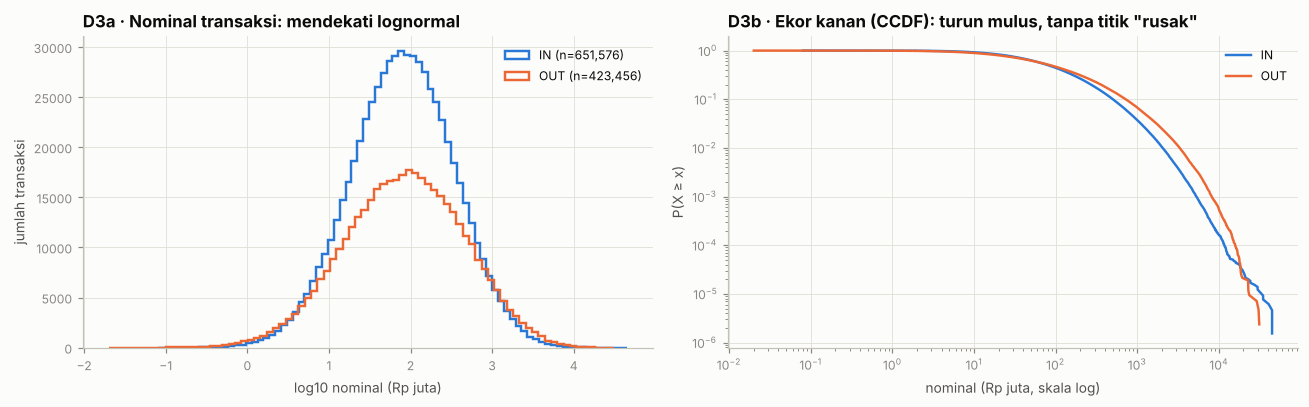

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for d, col in [('IN', C['s1']), ('OUT', C['s2'])]:
    a = np.log10(tx.loc[tx.direction == d, 'amount_idr_mn'])
    ax[0].hist(a, bins=80, histtype='step', lw=1.6, color=col, label=f'{d} (n={len(a):,})')
    s = np.sort(tx.loc[tx.direction == d, 'amount_idr_mn'].values)[::-1]; ccdf = np.arange(1, len(s) + 1) / len(s)
    ax[1].loglog(s, ccdf, color=col, lw=1.6, label=d)
ax[0].set(xlabel='log10 nominal (Rp juta)', ylabel='jumlah transaksi', title='D3a · Nominal transaksi: mendekati lognormal'); ax[0].legend()
ax[1].set(xlabel='nominal (Rp juta, skala log)', ylabel='P(X ≥ x)', title='D3b · Ekor kanan (CCDF): turun mulus, tanpa titik "rusak"'); ax[1].legend()
plt.tight_layout(); save_fig(fig, 'D3_amount_tails'); plt.show()
q = tx.amount_idr_mn.quantile([.5, .99, .999]); top = tx.amount_idr_mn.max()
print(f'median Rp{q[.5]:.0f} jt · p99 Rp{q[.99]:,.0f} jt · p99,9 Rp{q[.999]:,.0f} jt · maks Rp{top:,.0f} jt (≈{top / q[.5]:,.0f}× median)')
print('→ Ekor tebal tapi mulus = sifat alami nominal transaksi, bukan kesalahan input. Keputusan: log-transform, tidak dibuang.')

In [11]:
f25 = fin[fin.fiscal_year == 2025].merge(co[['company_id', 'industry', 'size_class_reference']], on='company_id').set_index('company_id')
f25['DER'] = f25.total_debt_idr_bn / f25.total_equity_idr_bn
f25['CR'] = f25.current_assets_idr_bn / f25.current_liabilities_idr_bn
f25['NPM'] = f25.net_profit_idr_bn / f25.revenue_idr_bn
f25['ICR'] = f25.ebit_idr_bn / f25.interest_expense_idr_bn
peer = f25[['industry', 'size_class_reference']]
ref = pd.Series(NOT_HOLD.reindex(f25.index).values, index=f25.index)
rows = []
for r in ['DER', 'CR', 'NPM', 'ICR']:
    x = np.log(f25[r].clip(lower=1e-3)) if r in ('DER', 'CR') else f25[r]
    zg, zp = robust_z(x, ref_mask=ref), robust_z(x, peer, ref_mask=ref)
    og, op = zg.abs() > 3.5, zp.abs() > 3.5
    rows.append(dict(rasio=r, outlier_global=int(og.sum()), outlier_peer=int(op.sum()), global_tapi_normal_di_peer=int((og & ~op).sum()),
                     peer_saja=int((op & ~og).sum())))
out_tab = pd.DataFrame(rows); display(out_tab)
r_ = out_tab.set_index('rasio')
print(f"→ ICR paling bermasalah: {r_.loc['ICR', 'outlier_global']} outlier global, karena penyebutnya (beban bunga) bisa sangat kecil.")
print(f"  {r_.loc['ICR', 'global_tapi_normal_di_peer']} di antaranya wajar bila dibandingkan dengan peer-nya.")
print(f"→ NPM: {r_.loc['NPM', 'peer_saja']} perusahaan normal secara global tapi menyimpang dari peer-nya. Outlier global saja tidak cukup.")
print('Keputusan FE: transform log (DER, CR) atau log1p bertanda (ICR), lalu winsorize di persentil 1/99 per peer. Baris tidak dibuang.')

→ ICR paling bermasalah: 115 outlier global, karena penyebutnya (beban bunga) bisa sangat kecil.
  57 di antaranya wajar bila dibandingkan dengan peer-nya.
→ NPM: 13 perusahaan normal secara global tapi menyimpang dari peer-nya. Outlier global saja tidak cukup.
Keputusan FE: transform log (DER, CR) atau log1p bertanda (ICR), lalu winsorize di persentil 1/99 per peer. Baris tidak dibuang.


,rasio,outlier_global,outlier_peer,global_tapi_normal_di_peer,peer_saja
0,DER,1,4,0,3
1,CR,4,4,3,3
2,NPM,3,14,2,13
3,ICR,115,76,57,18


**Lonjakan inflow bulanan.** Untuk setiap nasabah, inflow bulanan (log) dibandingkan dengan median dan MAD miliknya sendiri. Bulan dengan z robust > 3,5 ditandai.

In [12]:
cli_ids = co.loc[co.customer_type != 'Prospect', 'company_id']
L = np.log1p(inn.reindex(cli_ids))
med = L.median(axis=1); mad = L.sub(med, axis=0).abs().median(axis=1)
Z = L.sub(med, axis=0).div(1.4826 * mad.replace(0, np.nan), axis=0)
flag = (Z > 3.5).stack(); flag = flag[flag]
print(f'{len(flag)} perusahaan-bulan ditandai lonjakan, pada {flag.index.get_level_values(0).nunique()} nasabah')
gta = rd('gt_anomaly_events'); sp = gta[(gta.event_type == 'spike') & gta.company_id.isin(cli_ids)]
truth = set(zip(sp.company_id, sp.start_month)); found = {(c, str(m)) for c, m in flag.index}
print(f'🔎 Cek ground truth (evaluasi saja): presisi {len(truth & found) / len(found):.0%}, recall {len(truth & found) / len(truth):.0%} '
      f'terhadap {len(truth)} lonjakan sesaat yang sebenarnya.')
print('→ Aturan z robust sederhana sudah menangkap sebagian besar lonjakan. Sisanya bulan dengan kenaikan nyata (ekspansi) atau musim Lebaran.')
print('  Keputusan FE: agregat berbasis median, fitur max_z_inflow_12m, dan bulan lonjakan tidak ikut menghitung tren.')

250 perusahaan-bulan ditandai lonjakan, pada 222 nasabah
🔎 Cek ground truth (evaluasi saja): presisi 53%, recall 96% terhadap 139 lonjakan sesaat yang sebenarnya.
→ Aturan z robust sederhana sudah menangkap sebagian besar lonjakan. Sisanya bulan dengan kenaikan nyata (ekspansi) atau musim Lebaran.
  Keputusan FE: agregat berbasis median, fitur max_z_inflow_12m, dan bulan lonjakan tidak ikut menghitung tren.


### D4. Rencana encoding
Encoding dipilih berdasarkan kardinalitas dan sifat variabel. Untuk variabel berkardinalitas tinggi, *target encoding* dengan regularisasi dan *cross-fitting* terbukti paling baik (Pargent dkk., 2022). Pilihan yang lebih aman dari kebocoran adalah mengganti kategori dengan **atribut numeriknya**: misalnya kecamatan diganti penetrasi BNI, jumlah kawasan industri, dan jarak ke cabang.

In [13]:
plan = {('companies', 'industry'): ('one-hot (10)', 'nominal, kardinalitas kecil'),
        ('companies', 'kbli_2digit'): ('BUANG', 'identik 1:1 dengan industry (redundan)'),
        ('companies', 'size_class_reference'): ('ordinal Kecil<Menengah<Besar', 'urutan alami'),
        ('companies', 'customer_type'): ('one-hot (3) / filter populasi', 'menentukan visibilitas data'),
        ('companies', 'city'): ('one-hot (7)', 'komunitas jaringan mengikuti kota (F8)'),
        ('companies', 'district'): ('atribut numerik kecamatan', '40 level; ganti penetrasi, POI industri, jarak cabang'),
        ('companies', 'payroll_bank'): ('biner', '2 level'),
        ('companies', 'business_group'): ('fitur graf (ukuran grup, risiko rekan grup)', '46 level, 92% kosong; jangan one-hot'),
        ('transactions', 'channel'): ('porsi per kanal (agregat)', 'level transaksi → diringkas per perusahaan'),
        ('transactions', 'transaction_type'): ('porsi & timing per jenis', 'sumber sinyal dini (F2)'),
        ('transactions', 'counterparty_bank'): ('porsi BNI (agregat)', 'proxy wallet share'),
        ('transactions', 'data_visibility'): ('JANGAN dipakai sebagai fitur', 'identik dengan status nasabah/prospect (lihat G2)'),
        ('credit_facilities', 'facility_type'): ('one-hot', 'kardinalitas kecil'),
        ('credit_facilities', 'policy_restriction'): ("kategori + 'tidak ada'", 'missing struktural'),
        ('relationships', 'relationship_type'): ('hitungan & porsi per jenis', 'agregat per perusahaan'),
        ('network_entities', 'industry'): ('agregat mitra', 'dipakai lewat jaringan')}
assert co.groupby('industry').kbli_2digit.nunique().max() == 1 and co.groupby('kbli_2digit').industry.nunique().max() == 1
srcs = {'companies': co, 'transactions': tx, 'credit_facilities': cf, 'relationships': rel, 'network_entities': ne}
enc = pd.DataFrame([dict(tabel=t, kolom=k, kardinalitas=srcs[t][k].nunique(), encoding=v[0], alasan=v[1]) for (t, k), v in plan.items()])
enc.to_csv(OUT / 'encoding_plan.csv', index=False); display(enc)

,tabel,kolom,kardinalitas,encoding,alasan
0,companies,industry,10,one-hot (10),"nominal, kardinalitas kecil"
1,companies,kbli_2digit,10,BUANG,identik 1:1 dengan industry (redundan)
2,companies,size_class_reference,3,ordinal Kecil<Menengah<Besar,urutan alami
3,companies,customer_type,3,one-hot (3) / filter populasi,menentukan visibilitas data
4,companies,city,7,one-hot (7),komunitas jaringan mengikuti kota (F8)
5,companies,district,40,atribut numerik kecamatan,"40 level; ganti penetrasi, POI industri, jarak cabang"
6,companies,payroll_bank,2,biner,2 level
7,companies,business_group,46,"fitur graf (ukuran grup, risiko rekan grup)","46 level, 92% kosong; jangan one-hot"
8,transactions,channel,8,porsi per kanal (agregat),level transaksi → diringkas per perusahaan
9,transactions,transaction_type,6,porsi & timing per jenis,sumber sinyal dini (F2)


## E. Profil umum
Gambaran besar sebelum masuk ke temuan: komposisi kelas risiko (ketimpangan kelas) dan perilaku transaksi dari waktu ke waktu. Grafik yang memakai label hanya memakai porsi dev.

Kelas tidak seimbang: High hanya 13.6% → notebook 04–05 perlu cost-sensitive / class weight, dan metrik macro-F1 + recall High.
Industri dan risiko terkait (χ² p = 1.8e-02); porsi High berkisar dari 4% sampai 31%.


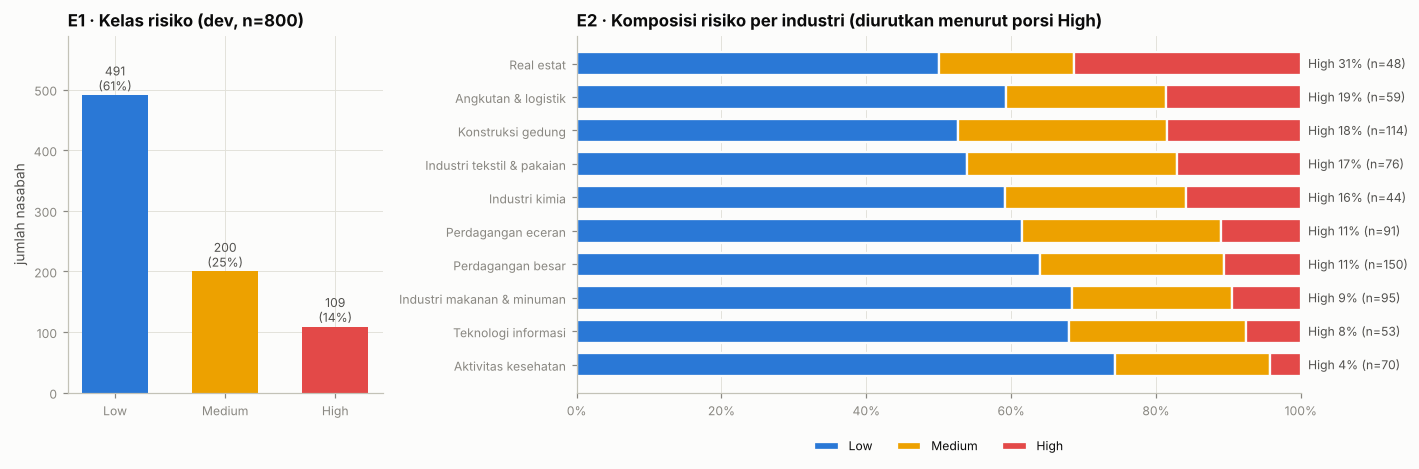

In [14]:
labd = lab[lab.company_id.isin(DEV)]
ct = pd.crosstab(labd.industry, labd.risk_class, normalize='index')[RISK_ORDER]
ct = ct.sort_values('High'); n_ind = labd.industry.value_counts()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw=dict(width_ratios=[1, 2.3]))
vc = labd.risk_class.value_counts()[RISK_ORDER]
ax[0].bar(RISK_ORDER, vc.values, color=[RISK_COL[k] for k in RISK_ORDER], width=.6)
for i, v in enumerate(vc.values): ax[0].text(i, v + 8, f'{v}\n({v / vc.sum():.0%})', ha='center', fontsize=8, color=C['ink2'])
ax[0].set(title='E1 · Kelas risiko (dev, n=800)', ylabel='jumlah nasabah'); ax[0].set_ylim(0, vc.max() * 1.2)
left = np.zeros(len(ct))
for k in RISK_ORDER:
    ax[1].barh(range(len(ct)), ct[k], left=left, color=RISK_COL[k], label=k, height=.7, edgecolor=C['surface'], linewidth=1.5); left += ct[k].values
for i, (idx, v) in enumerate(ct.High.items()): ax[1].text(1.01, i, f'High {v:.0%} (n={n_ind[idx]})', va='center', fontsize=8, color=C['ink2'], transform=ax[1].get_yaxis_transform())
ax[1].set_yticks(range(len(ct))); ax[1].set_yticklabels(ct.index); ax[1].set_xlim(0, 1); ax[1].xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax[1].set_title('E2 · Komposisi risiko per industri (diurutkan menurut porsi High)'); ax[1].legend(ncol=3, loc='lower center', bbox_to_anchor=(.5, -.2)); ax[1].grid(axis='y', visible=False)
plt.tight_layout(); save_fig(fig, 'E1_risk_profile'); plt.show()
chi, p_ind, *_ = stats.chi2_contingency(pd.crosstab(labd.industry, labd.risk_class))
print(f'Kelas tidak seimbang: High hanya {vc["High"] / vc.sum():.1%} → notebook 04–05 perlu cost-sensitive / class weight, dan metrik macro-F1 + recall High.')
print(f'Industri dan risiko terkait (χ² p = {p_ind:.1e}); porsi High berkisar dari {ct.High.min():.0%} sampai {ct.High.max():.0%}.')
record('E2', 'Porsi High berbeda antar industri', 'χ² industri × kelas (dev)', f'High {ct.High.min():.0%}–{ct.High.max():.0%}', p_ind, 'dev', 'one-hot industri')

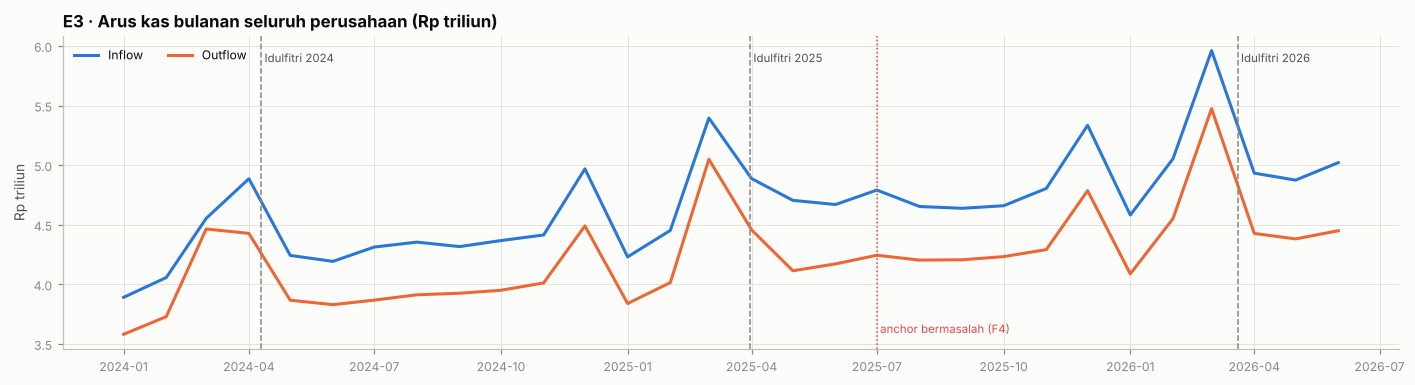

In [15]:
mon = tx.groupby(['ym', 'direction']).amount_idr_mn.sum().unstack() / 1e6
LEBARAN = {'2024-04-10': 'Idulfitri 2024', '2025-03-31': 'Idulfitri 2025', '2026-03-20': 'Idulfitri 2026'}
fig, ax = plt.subplots(figsize=(13, 3.6))
x = mon.index.to_timestamp()
ax.plot(x, mon.IN, color=C['s1'], label='Inflow'); ax.plot(x, mon.OUT, color=C['s2'], label='Outflow')
for d, n_ in LEBARAN.items():
    ax.axvline(pd.Timestamp(d), color=C['muted'], lw=1, ls='--'); ax.text(pd.Timestamp(d), ax.get_ylim()[1] * .98, ' ' + n_, fontsize=7.5, color=C['ink2'], va='top')
ax.axvline(pd.Timestamp('2025-07-01'), color=C['s8'], lw=1, ls=':'); ax.text(pd.Timestamp('2025-07-01'), ax.get_ylim()[0] + .05 * np.diff(ax.get_ylim())[0], ' anchor bermasalah (F4)', fontsize=7.5, color=C['s8'])
ax.set(title='E3 · Arus kas bulanan seluruh perusahaan (Rp triliun)', ylabel='Rp triliun'); ax.legend(loc='upper left', ncol=2)
plt.tight_layout(); save_fig(fig, 'E3_monthly_flow'); plt.show()

## F. Temuan F1–F10
Setiap temuan ditulis dengan pola yang sama: **pertanyaan → bukti (grafik + uji) → arti bisnis → fitur untuk notebook 03**.

Sebelum mulai, disiapkan dulu **tabel fitur prototipe**: satu baris per perusahaan, berisi besaran yang diuji di temuan-temuan berikut. Semua besaran ini dihitung dari data teramati sampai cutoff dan tidak memakai label. Definisi final fitur tetap dibuat di notebook 03.

In [16]:
P = pd.DataFrame(index=pd.Index(co.company_id, name='company_id'))
P = P.join(co.set_index('company_id')[['industry', 'size_class_reference', 'customer_type', 'city', 'age', 'log_emp', 'has_report']])
P['split'] = split
# --- rasio keuangan 2025: mentah (setelah transform) dan relatif-peer ---
slog = lambda v: np.sign(v) * np.log1p(np.abs(v))
RAW_R = {'DER': np.log(f25.DER.clip(lower=1e-3)), 'CR': np.log(f25.CR.clip(lower=1e-3)), 'NPM': f25.NPM, 'ICR': slog(f25.ICR)}
for r, x in RAW_R.items():
    P[f'{r}_raw'] = x; P[f'{r}_peer'] = robust_z(x, peer, ref_mask=ref)
# --- sinyal timing pembayaran (F2) ---
pay = tx[tx.transaction_type == 'Payroll']; tax = tx[tx.transaction_type == 'Tax']
P['payroll_late_share'] = pay.assign(l=pay.day >= 28).groupby('company_id').l.mean()
P['tax_late_share'] = tax.assign(l=tax.day > 15).groupby('company_id').l.mean()
P['payroll_split_share'] = pay.groupby(['company_id', 'ym']).size().gt(1).groupby('company_id').mean()
last6 = lambda d: d[d.ym >= pd.Period('2026-01', 'M')]
P['payroll_late_6m'] = last6(pay).assign(l=lambda d: d.day >= 28).groupby('company_id').l.mean()
P['tax_late_6m'] = last6(tax).assign(l=lambda d: d.day > 15).groupby('company_id').l.mean()
# --- arus kas ---
out_m = tx[tx.direction == 'OUT'].groupby(['company_id', 'ym']).amount_idr_mn.sum().unstack(fill_value=0)
in6 = inn.loc[:, '2026-01':'2026-06'].sum(axis=1)
P['out_in_ratio_6m'] = out_m.loc[:, '2026-01':'2026-06'].sum(axis=1) / in6
P['inflow_cv'] = inn.std(axis=1) / inn.mean(axis=1)
P['inflow_growth_h1'] = co.set_index('company_id').in_growth
# --- fasilitas kredit (hanya kolom berperan fitur) ---
P['utilization'] = cf.set_index('company_id').utilization
P['log_limit'] = np.log(cf.set_index('company_id').limit_idr_bn)
print(P.shape); display(P[P.split == 'dev'].describe().T.round(3).head(25))

(2000, 26)


,count,mean,std,min,25%,50%,75%,max
age,800.0,17.246,10.623,3.000,8.000,16.000,24.000,41.000
log_emp,800.0,4.674,1.016,1.609,3.951,4.610,5.314,7.826
DER_raw,799.0,0.203,0.724,-2.113,-0.280,0.173,0.715,2.748
DER_peer,799.0,-0.068,1.022,-3.836,-0.689,-0.052,0.610,3.552
CR_raw,799.0,0.381,0.370,-0.856,0.109,0.379,0.616,1.497
CR_peer,799.0,0.091,1.052,-3.821,-0.661,0.078,0.741,4.087
NPM_raw,799.0,0.012,0.066,-0.203,-0.029,0.016,0.054,0.182
NPM_peer,799.0,-0.058,1.172,-6.903,-0.755,0.020,0.676,5.755
ICR_raw,775.0,0.869,0.662,-1.125,0.470,0.837,1.275,3.078
ICR_peer,775.0,0.063,1.110,-5.180,-0.678,0.022,0.745,3.856


### F1 · Level rasio ditentukan sektor → rasio harus dibaca relatif terhadap peer
**Pertanyaan.** Apakah DER yang tinggi berarti risiko tinggi?

**Metode.** DER (log) setiap perusahaan dipecah menjadi dua komponen:
- **komponen antar-peer**: median DER peer-nya (industri × ukuran);
- **komponen dalam-peer**: seberapa jauh DER perusahaan dari peer-nya (z robust).

Kalau hampir seluruh daya prediksi ada di komponen dalam-peer, berarti rasio mentah mencampur "sinyal" dengan "ciri sektor". Ini struktur yang melahirkan paradoks Simpson (Simpson, 1951), dan sejalan dengan praktik analis kredit yang selalu membandingkan rasio dengan benchmark sektor.

Dekomposisi DER: AUC komponen antar-peer = 0.527 vs komponen dalam-peer = 0.899 (bootstrap p = 0.002).
Contoh: Aktivitas kesehatan DER median 2.0× tapi High hanya 4%; Konstruksi gedung DER median 1.2× tapi High 18%.


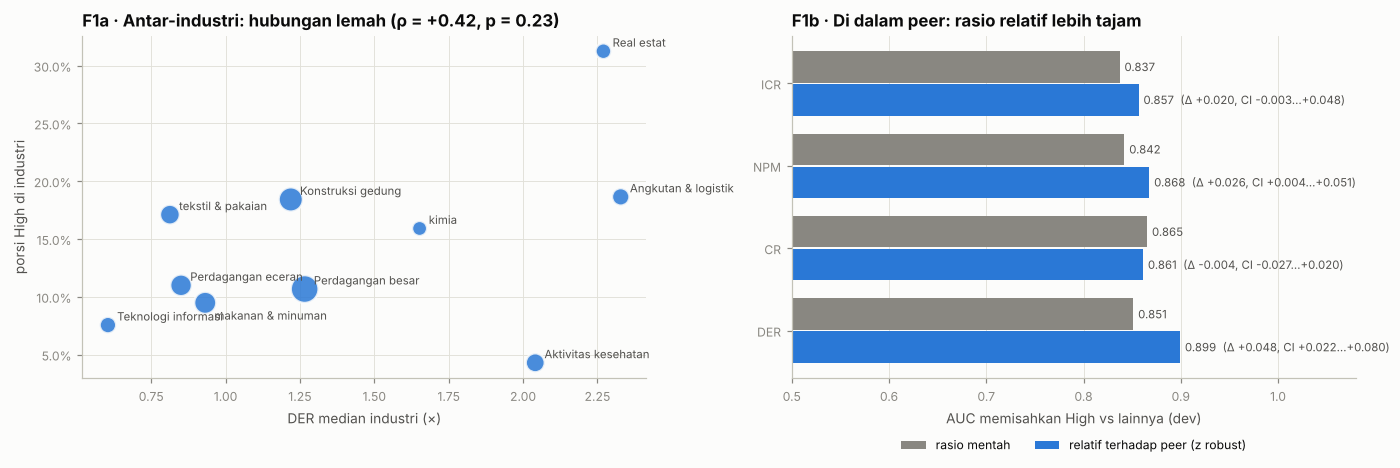

,rasio,AUC_mentah,AUC_relatif_peer,delta,CI95_bawah,CI95_atas,p_boot
0,DER,0.851,0.899,0.048,0.022,0.080,0.002
1,CR,0.865,0.861,-0.004,-0.027,0.020,0.674
2,NPM,0.842,0.868,0.026,0.004,0.051,0.018
3,ICR,0.837,0.857,0.020,-0.003,0.048,0.118


In [17]:
dv = P[P.split == 'dev'].join(rl.set_index('company_id').risk_class)
dv['High'] = (dv.risk_class == 'High').astype(int)
ind_tab = dv.groupby('industry').agg(DER_median=('DER_raw', lambda s: np.exp(s.median())), High=('High', 'mean'), n=('High', 'size'))
rho_ind, p_ind_rho = stats.spearmanr(ind_tab.DER_median, ind_tab.High)
pm_ = P.DER_raw.where(NOT_HOLD.reindex(P.index)).groupby([P.industry, P.size_class_reference]).transform('median')
dv['DER_between'] = pm_.reindex(dv.index); dv['DER_within'] = dv.DER_peer
a_btw, a_wth = auc(dv.High, dv.DER_between), auc(dv.High, dv.DER_within)
dd_ = dv[['High', 'DER_between', 'DER_within']].dropna()
bs_ = []; rr_ = np.random.default_rng(SEED)
for _ in range(500):
    ix = rr_.integers(0, len(dd_), len(dd_)); d0 = dd_.iloc[ix]
    bs_.append(auc(d0.High, d0.DER_within) - auc(d0.High, d0.DER_between))
p_dec = min(1, 2 * np.mean(np.array(bs_) <= 0) + 1 / 500)
sign = {'DER': 1, 'CR': -1, 'NPM': -1, 'ICR': -1}       # arah risiko yang diharapkan secara teori
rows = []
for r, sg in sign.items():
    d_ = dv[[f'{r}_raw', f'{r}_peer', 'High']].dropna()
    a_raw, a_peer = auc(d_.High, sg * d_[f'{r}_raw']), auc(d_.High, sg * d_[f'{r}_peer'])
    delta = lambda y, a, b: auc(y, sg * b) - auc(y, sg * a)
    lo, hi = boot_ci(delta, d_.High.values, d_[f'{r}_raw'].values, d_[f'{r}_peer'].values)
    bs = []; rr = np.random.default_rng(SEED)
    for _ in range(500):
        ix = rr.integers(0, len(d_), len(d_))
        try: bs.append(delta(d_.High.values[ix], d_[f'{r}_raw'].values[ix], d_[f'{r}_peer'].values[ix]))
        except ValueError: pass
    p_ = min(1, 2 * min(np.mean(np.array(bs) <= 0), np.mean(np.array(bs) >= 0)) + 1 / 500)
    rows.append(dict(rasio=r, AUC_mentah=a_raw, AUC_relatif_peer=a_peer, delta=a_peer - a_raw, CI95_bawah=lo, CI95_atas=hi, p_boot=p_))
f1 = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
ax[0].scatter(ind_tab.DER_median, ind_tab.High, s=ind_tab.n * 2.2, color=C['s1'], alpha=.85, edgecolor=C['surface'], linewidth=1.5)
for i, r in ind_tab.iterrows(): ax[0].annotate(i.replace('Industri ', ''), (r.DER_median, r.High), xytext=(6, -11 if 'makanan' in i else 3), textcoords='offset points', fontsize=7.5, color=C['ink2'])
ax[0].set(xlabel='DER median industri (×)', ylabel='porsi High di industri', title=f'F1a · Antar-industri: hubungan lemah (ρ = {rho_ind:+.2f}, p = {p_ind_rho:.2f})')
ax[0].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
y_ = np.arange(len(f1))
ax[1].barh(y_ + .2, f1.AUC_mentah, height=.38, color=C['muted'], label='rasio mentah')
ax[1].barh(y_ - .2, f1.AUC_relatif_peer, height=.38, color=C['s1'], label='relatif terhadap peer (z robust)')
for i, r in f1.iterrows():
    ax[1].text(r.AUC_relatif_peer + .005, i - .2, f'{r.AUC_relatif_peer:.3f}  (Δ {r.delta:+.3f}, CI {r.CI95_bawah:+.3f}…{r.CI95_atas:+.3f})', va='center', fontsize=7.5, color=C['ink2'])
    ax[1].text(r.AUC_mentah + .005, i + .2, f'{r.AUC_mentah:.3f}', va='center', fontsize=7.5, color=C['ink2'])
ax[1].set_yticks(y_); ax[1].set_yticklabels(f1.rasio); ax[1].set_xlim(.5, 1.08); ax[1].grid(axis='y', visible=False)
ax[1].set(xlabel='AUC memisahkan High vs lainnya (dev)', title='F1b · Di dalam peer: rasio relatif lebih tajam'); ax[1].legend(loc='upper center', bbox_to_anchor=(.5, -.14), ncol=2)
plt.tight_layout(); save_fig(fig, 'F1_simpson_peer'); plt.show()
display(f1.round(3))
hk = ind_tab.sort_values('DER_median', ascending=False)
print(f'Dekomposisi DER: AUC komponen antar-peer = {a_btw:.3f} vs komponen dalam-peer = {a_wth:.3f} (bootstrap p = {p_dec:.3f}).')
ex_lo = ind_tab[ind_tab.DER_median > ind_tab.DER_median.median()].High.idxmin(); ex_hi = ind_tab[ind_tab.DER_median < ind_tab.DER_median.median()].High.idxmax()
print(f'Contoh: {ex_lo} DER median {ind_tab.DER_median[ex_lo]:.1f}× tapi High hanya {ind_tab.High[ex_lo]:.0%}; '
      f'{ex_hi} DER median {ind_tab.DER_median[ex_hi]:.1f}× tapi High {ind_tab.High[ex_hi]:.0%}.')
record('F1-decomp', 'Daya prediksi DER ada di komponen dalam-peer, bukan level sektor', 'bootstrap ΔAUC (dalam − antar)', f'AUC {a_wth:.3f} vs {a_btw:.3f}', p_dec, 'dev', 'rasio relatif-peer')
for r in f1.itertuples():
    record(f'F1-{r.rasio}', f'{r.rasio} relatif-peer lebih tajam dari mentah', 'bootstrap ΔAUC berpasangan', f'ΔAUC={r.delta:+.3f}', r.p_boot, 'dev', f'{r.rasio}_peer_z')

**Arti bisnis.** Analis yang membandingkan DER sebuah perusahaan real estat dengan perusahaan IT akan salah menilai. Model juga akan salah kalau hanya diberi rasio mentah.

**Fitur untuk notebook 03:** z robust per peer (industri × ukuran) untuk DER, CR, NPM, dan ICR. Median dan MAD peer di-*fit* hanya pada data latih. Hasilnya tidak seragam: DER dan NPM membaik secara bermakna, ICR membaik tapi rentang kepercayaannya menyentuh 0, dan CR tidak membaik. Karena itu versi mentah dan relatif-peer sama-sama dibawa ke notebook 03, lalu dipilih lewat ablation.

### F2 · Sinyal dini dari timing pembayaran: kapan gaji dan pajak dibayar
**Pertanyaan.** Sebelum laporan keuangan memburuk, apakah perilaku pembayaran sudah memberi tanda?

**Temuan.** Ya. Perusahaan yang kasnya ketat mulai **membayar gaji makin mendekati akhir bulan (≥ tanggal 28)**, kadang **dicicil dua kali**, dan **menyetor pajak lewat tanggal 15** (batas setor pajak bulanan yang dipakai di data ini). Data transaksi harian memuat sinyal ini, sedangkan laporan keuangan tahunan tidak. Dari sinilah datang nilai tambah data transaksi BNI dibanding analisis kredit konvensional.

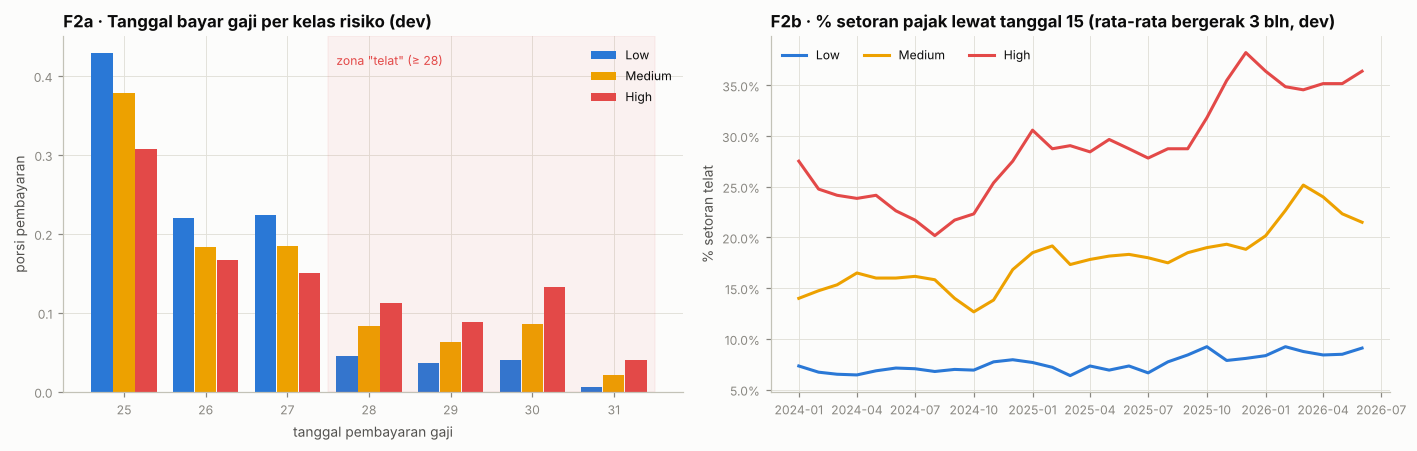

,sinyal,kolom,median_Low,median_High,AUC_High,CI95,p_MWU
0,% gaji dibayar ≥ tgl 28 (30 bln),payroll_late_share,0.1000,0.3667,0.8472,0.806–0.880,0.0
1,% pajak disetor > tgl 15 (30 bln),tax_late_share,0.0667,0.2667,0.8616,0.824–0.894,0.0
2,% bulan gaji dicicil,payroll_split_share,0.0000,0.0000,0.5702,0.534–0.606,0.0
3,"% gaji telat, 6 bln terakhir",payroll_late_6m,0.1667,0.3333,0.7542,0.699–0.800,0.0
4,"% pajak telat, 6 bln terakhir",tax_late_6m,0.0000,0.1667,0.7291,0.677–0.774,0.0


In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
pd_ = pay[pay.company_id.isin(DEV)].merge(rl, on='company_id')
days = np.arange(25, 32)
for k, off in zip(RISK_ORDER, [-.27, 0, .27]):
    s = pd_[pd_.risk_class == k].day.clip(25, 31).value_counts(normalize=True).reindex(days, fill_value=0)
    ax[0].bar(days + off, s.values, width=.26, color=RISK_COL[k], label=k)
ax[0].axvspan(27.5, 31.5, color=C['s8'], alpha=.06); ax[0].text(27.6, ax[0].get_ylim()[1] * .92, 'zona "telat" (≥ 28)', fontsize=8, color=C['s8'])
ax[0].set(xlabel='tanggal pembayaran gaji', ylabel='porsi pembayaran', title='F2a · Tanggal bayar gaji per kelas risiko (dev)'); ax[0].legend()
tl = tax[tax.company_id.isin(DEV)].merge(rl, on='company_id').assign(l=lambda d: d.day > 15)
ms = tl.groupby(['ym', 'risk_class']).l.mean().unstack()[RISK_ORDER]
for k in RISK_ORDER: ax[1].plot(ms.index.to_timestamp(), ms[k].rolling(3, min_periods=1).mean(), color=RISK_COL[k], label=k)
ax[1].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax[1].set(title='F2b · % setoran pajak lewat tanggal 15 (rata-rata bergerak 3 bln, dev)', ylabel='% setoran telat'); ax[1].legend(ncol=3)
plt.tight_layout(); save_fig(fig, 'F2_payment_timing'); plt.show()
rows = []
for c, lbl in [('payroll_late_share', '% gaji dibayar ≥ tgl 28 (30 bln)'), ('tax_late_share', '% pajak disetor > tgl 15 (30 bln)'),
               ('payroll_split_share', '% bulan gaji dicicil'), ('payroll_late_6m', '% gaji telat, 6 bln terakhir'), ('tax_late_6m', '% pajak telat, 6 bln terakhir')]:
    h, l_ = dv.loc[dv.risk_class == 'High', c].dropna(), dv.loc[dv.risk_class == 'Low', c].dropna()
    u, p = stats.mannwhitneyu(h, l_); a = auc(dv.High, dv[c]); lo, hi = boot_ci(auc, dv.High.values, dv[c].values)
    rows.append(dict(sinyal=lbl, kolom=c, median_Low=l_.median(), median_High=h.median(), AUC_High=a, CI95=f'{lo:.3f}–{hi:.3f}', p_MWU=p))
    record(f'F2-{c}', f'{lbl}: High > Low', 'Mann–Whitney High vs Low', f'AUC={a:.3f}', p, 'dev', c)
f2 = pd.DataFrame(rows); display(f2.round(4))

**Arti bisnis.** Ini sinyal *early warning* yang bisa dipantau RM setiap bulan **tanpa menunggu laporan keuangan tahunan**. Sinyal versi 30 bulan lebih kuat daripada versi 6 bulan, yang menunjukkan ada dua komponen: **kebiasaan kronis** (perusahaan lemah memang sering telat) dan **perubahan mendadak** (perusahaan yang mulai tertekan).

**Fitur untuk notebook 03:** `payroll_late_share`, `tax_late_share`, `payroll_split_share` untuk jendela 6 dan 12 bulan, serta **delta**-nya (6 bulan terakhir dikurangi 12 bulan sebelumnya) untuk menangkap perubahan. **Batasan:** fitur ini hanya tersedia untuk nasabah yang payroll/pajaknya lewat BNI. Prospect tidak punya sinyal ini (lihat G2).

### F3 · Konsentrasi pembeli: risiko naik terus, tapi "ambang 30%" tidak terbukti
**Pertanyaan.** Apakah ketergantungan pada satu pembeli besar menaikkan risiko? Kalau ya, apakah ada **ambang** (misalnya aturan praktis "porsi > 30% = berbahaya") atau hubungannya mulus?

**Metode.** Porsi pembeli terbesar diambil dari `relationships` (relasi Customer/Distributor yang aktif per cutoff). Dua model dibandingkan:
1. logistik biasa `logit P(High) = a + b·s`;
2. **logistik tersegmentasi** (Muggeo, 2003) `… + c·max(0, s − τ)`, dengan titik patah τ dicari lewat *profile likelihood*.

Karena τ dicari dari data, nilai p diperoleh lewat **uji permutasi yang ikut mencari ulang τ** di setiap permutasi. Tanpa itu, uji akan terlalu mudah "menemukan" ambang. Kestabilan τ dicek dengan bootstrap.

Efek konsentrasi (logistik linear): b = +2.82 per 1,0 porsi, LR = 19.6, p = 9.5e-06 · AUC 0.626
Ambang: τ terbaik = 0.41, tetapi bootstrap 95% 0.15–0.60 (tidak stabil) · LR hinge vs linear = 0.24 · p permutasi = 0.985
Porsi pembeli terbesar yang dihitung dari transaksi BNI saja: AUC 0.549 vs 0.626 dari data relasi (sebagian penjualan lewat bank lain, jadi data BNI tidak melihat konsentrasi yang sebenarnya).


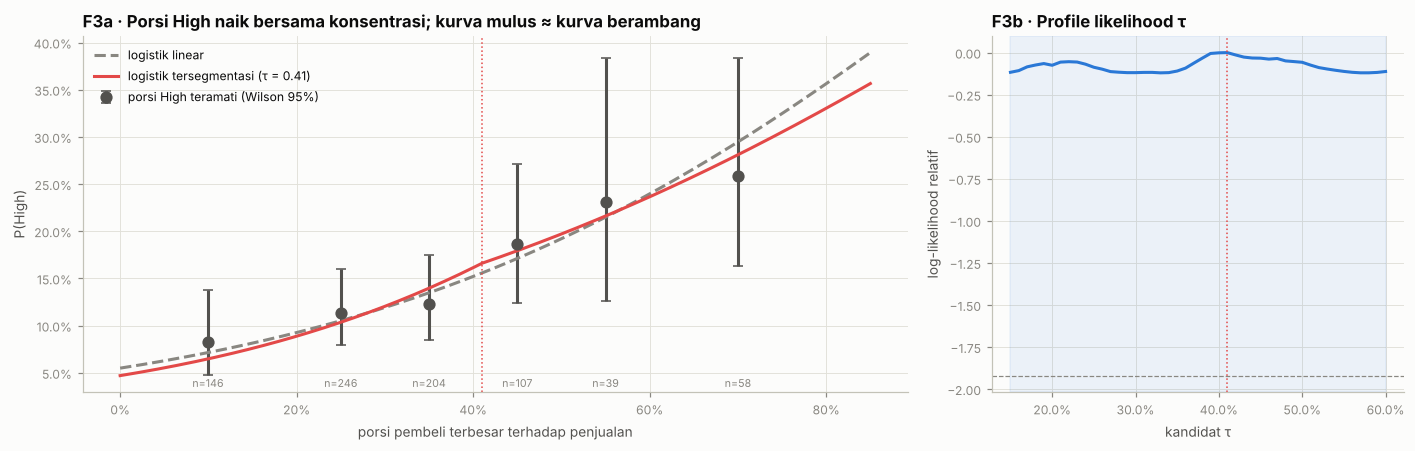

In [19]:
def logit_fit(X, y, iters=50):
    """Regresi logistik tanpa penalti (Newton–Raphson); mengembalikan (beta, log-likelihood)."""
    X = np.column_stack([np.ones(len(X)), X]); b = np.zeros(X.shape[1])
    for _ in range(iters):
        p = 1 / (1 + np.exp(-X @ b)); W = p * (1 - p) + 1e-9
        step = np.linalg.solve(X.T @ (X * W[:, None]) + 1e-8 * np.eye(len(b)), X.T @ (y - p)); b += step
        if np.abs(step).max() < 1e-8: break
    p = np.clip(1 / (1 + np.exp(-X @ b)), 1e-12, 1 - 1e-12)
    return b, float(np.sum(y * np.log(p) + (1 - y) * np.log(1 - p)))

TAUS = np.round(np.arange(.15, .61, .01), 2)
def best_tau(s, y):
    ll = np.array([logit_fit(np.column_stack([s, np.maximum(0, s - t)]), y)[1] for t in TAUS])
    return TAUS[ll.argmax()], ll

act = rel[(rel.relationship_start <= CUTOFF) & (rel.relationship_end.isna() | (rel.relationship_end > CUTOFF))]
buyers_rel = act[act.relationship_type.isin(['Customer', 'Distributor'])]
P['top_buyer_share'] = buyers_rel.groupby('source_id').dependency_share.max()
P['n_buyers'] = buyers_rel.groupby('source_id').size()
P[['top_buyer_share', 'n_buyers']] = P[['top_buyer_share', 'n_buyers']].fillna(0)
dv = dv.join(P[['top_buyer_share', 'n_buyers']])
s, y = dv.top_buyer_share.values, dv.High.values.astype(float)
tau, ll_prof = best_tau(s, y)
_, ll_lin = logit_fit(s[:, None], y); b_h, ll_h = logit_fit(np.column_stack([s, np.maximum(0, s - tau)]), y)
LR = 2 * (ll_h - ll_lin)
rr = np.random.default_rng(SEED); perm = []
for _ in range(200):
    yp = rr.permutation(y); tp, llp = best_tau(s, yp); perm.append(2 * (llp.max() - logit_fit(s[:, None], yp)[1]))
p_tau = (1 + np.sum(np.array(perm) >= LR)) / 201
tb = []
for _ in range(200):
    ix = rr.integers(0, len(s), len(s)); tb.append(best_tau(s[ix], y[ix])[0])
tau_lo, tau_hi = np.quantile(tb, [.025, .975])
b_lin, ll_lin = logit_fit(s[:, None], y); _, ll_0 = logit_fit(np.zeros((len(y), 0)), y)
LR_lin = 2 * (ll_lin - ll_0); p_lin = stats.chi2.sf(LR_lin, 1)
a_rel = auc(dv.High, dv.top_buyer_share)
ibd = ib_all[ib_all.counterparty_id.notna() & ~ib_all.counterparty_id.astype(str).str.startswith('EXT')]
tx_share = (ibd.groupby(['company_id', 'counterparty_id']).amount_idr_mn.sum() / ib_all.groupby('company_id').amount_idr_mn.sum()).groupby(level=0).max()
a_tx = auc(dv.High, tx_share.reindex(dv.index).fillna(0))
print(f'Efek konsentrasi (logistik linear): b = {b_lin[1]:+.2f} per 1,0 porsi, LR = {LR_lin:.1f}, p = {p_lin:.1e} · AUC {a_rel:.3f}')
print(f'Ambang: τ terbaik = {tau:.2f}, tetapi bootstrap 95% {tau_lo:.2f}–{tau_hi:.2f} (tidak stabil) · LR hinge vs linear = {LR:.2f} · p permutasi = {p_tau:.3f}')
print(f'Porsi pembeli terbesar yang dihitung dari transaksi BNI saja: AUC {a_tx:.3f} vs {a_rel:.3f} dari data relasi '
      '(sebagian penjualan lewat bank lain, jadi data BNI tidak melihat konsentrasi yang sebenarnya).')
record('F3-conc', 'Porsi pembeli terbesar menaikkan peluang High', 'LR logistik linear vs konstanta', f'b={b_lin[1]:+.2f}, AUC={a_rel:.3f}', p_lin, 'dev', 'top_buyer_share (kontinu)')
record('F3-threshold', 'Ada ambang konsentrasi (hinge) yang lebih baik dari kurva mulus', 'LR tersegmentasi vs linear, p permutasi (τ dicari ulang)', f'τ={tau:.2f}, LR={LR:.2f}', p_tau, 'dev', 'TIDAK dibuat fitur ambang')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[2, 1]))
bins = [0, .2, .3, .4, .5, .6, 1.0]; dv['bin'] = pd.cut(dv.top_buyer_share, bins, include_lowest=True)
bt = dv.groupby('bin', observed=True).High.agg(['sum', 'size']); mid = [(b.left + b.right) / 2 for b in bt.index]; mid[-1] = .7
lo_, hi_ = wilson(bt['sum'].values, bt['size'].values); rate = bt['sum'] / bt['size']
ax[0].errorbar(mid, rate, yerr=[rate - lo_, hi_ - rate], fmt='o', color=C['ink2'], ms=7, capsize=3, label='porsi High teramati (Wilson 95%)')
for m_, n_ in zip(mid, bt['size']): ax[0].text(m_, .035, f'n={n_}', ha='center', fontsize=7, color=C['muted'])
g = np.linspace(0, .85, 200)
ax[0].plot(g, 1 / (1 + np.exp(-(logit_fit(s[:, None], y)[0] @ np.vstack([np.ones_like(g), g])))), color=C['muted'], ls='--', label='logistik linear')
ax[0].plot(g, 1 / (1 + np.exp(-(b_h @ np.vstack([np.ones_like(g), g, np.maximum(0, g - tau)])))), color=C['s8'], label=f'logistik tersegmentasi (τ = {tau:.2f})')
ax[0].axvline(tau, color=C['s8'], lw=1, ls=':'); ax[0].xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); ax[0].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax[0].set(xlabel='porsi pembeli terbesar terhadap penjualan', ylabel='P(High)', title='F3a · Porsi High naik bersama konsentrasi; kurva mulus ≈ kurva berambang'); ax[0].legend(loc='upper left')
ax[1].plot(TAUS, ll_prof - ll_prof.max(), color=C['s1']); ax[1].axvline(tau, color=C['s8'], ls=':', lw=1)
ax[1].axvspan(tau_lo, tau_hi, color=C['s1'], alpha=.08); ax[1].axhline(-1.92, color=C['muted'], lw=.8, ls='--')
ax[1].set(xlabel='kandidat τ', ylabel='log-likelihood relatif', title='F3b · Profile likelihood τ'); ax[1].xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
plt.tight_layout(); save_fig(fig, 'F3_concentration_threshold'); plt.show()

**Kesimpulan F3 (termasuk hasil negatif).** Konsentrasi pembeli **memang** menaikkan risiko: porsi High naik dari ±8% menjadi ±26% di kelompok paling terkonsentrasi. Namun **ambang tajam tidak terbukti**. Kurva logistik biasa sudah melengkung dengan sendirinya, dan τ hasil bootstrap melompat-lompat. Membuat fitur "porsi > 30%" hanya akan membuang informasi.

**Fitur untuk notebook 03:** `top_buyer_share` kontinu dari data relasi, `n_buyers`, dan HHI pembeli. Untuk model berbasis pohon, ambang biarlah dipelajari model sendiri. **Catatan:** konsentrasi yang dihitung dari transaksi BNI saja jauh lebih lemah. Ini alasan kuat memakai data relasi/ekosistem, dan sekaligus bukti bahwa sebagian dompet nasabah ada di bank lain (lihat F6).

### F4 · Efek berantai dari anchor yang bermasalah: deteksi dari data + dosis–respons + plasebo
**Pertanyaan.** Kalau pembeli besar (anchor) dalam ekosistem mengalami kesulitan, apakah pemasoknya ikut terdampak, dan seberapa besar dampaknya bergantung pada tingkat ketergantungan?

**Metode** (tanpa label, semua perusahaan). Ada tiga langkah:
1. **Deteksi anchor yang bermasalah murni dari data.** Untuk 12 kandidat anchor (`is_anchor_candidate`), tren inflow 18 bulan pertama diestimasi dengan Theil–Sen (tahan outlier). Lalu dihitung seberapa jauh inflow 6 bulan sesudahnya menyimpang dari tren itu. Ini pendekatan *interrupted time series* (Bernal dkk., 2017): yang dicari adalah **patahan dari tren sendiri**, bukan sekadar penurunan, supaya anchor yang memang sedang menurun pelan tidak ikut tertandai.
2. **Dosis–respons.** Paparan pemasok = jumlah `dependency_share` ke anchor bermasalah. Kalau efeknya nyata, makin besar paparan, makin besar penurunan inflow (kriteria dosis–respons ala Hill).
3. **Kontrol plasebo.** Paparan yang sama besar ke anchor yang **sehat** seharusnya **tidak** menurunkan inflow. Kalau ternyata ikut turun, "efek berantai" itu hanyalah artefak, misalnya pemasok besar memang sedang melambat.

Gagasan bahwa guncangan merambat lewat ketergantungan antar-pihak adalah inti DebtRank (Battiston dkk., 2012). Di sini gagasan itu diterapkan pada rantai pasok nasabah.

Anchor bermasalah terdeteksi dari data: ['C0299', 'C0409']
Dosis–respons (terpapar, n=183): Spearman ρ = -0.42 (p = 2.6e-09) · plasebo (n=433): ρ = +0.00 (p = 0.94)
Paparan tinggi vs tanpa paparan: selisih median Δlog inflow = -0.242 (≈ -21%), Mann–Whitney p = 1.3e-12
Terhadap label risiko (dev): porsi High di antara yang terpapar 18% (n=76) vs tidak terpapar 13% · p = 0.20


,anchor,industri,tren_tahunan,deviasi_pasca,z,bermasalah
2,C0299,Perdagangan eceran,0.033,-0.544,-9.316,True
3,C0409,Perdagangan besar,0.076,-0.493,-4.618,True
7,C1190,Perdagangan besar,0.259,-0.066,-1.299,False
9,C1484,Industri makanan & minuman,0.076,-0.096,-1.131,False
5,C0847,Perdagangan eceran,0.606,-0.643,-1.024,False
11,C1888,Industri makanan & minuman,-0.245,-0.083,-0.857,False
4,C0766,Perdagangan eceran,0.256,-0.033,-0.240,False
1,C0241,Aktivitas kesehatan,0.154,0.020,0.346,False
6,C0878,Aktivitas kesehatan,0.043,0.020,0.509,False
10,C1674,Perdagangan besar,-0.020,0.088,0.818,False


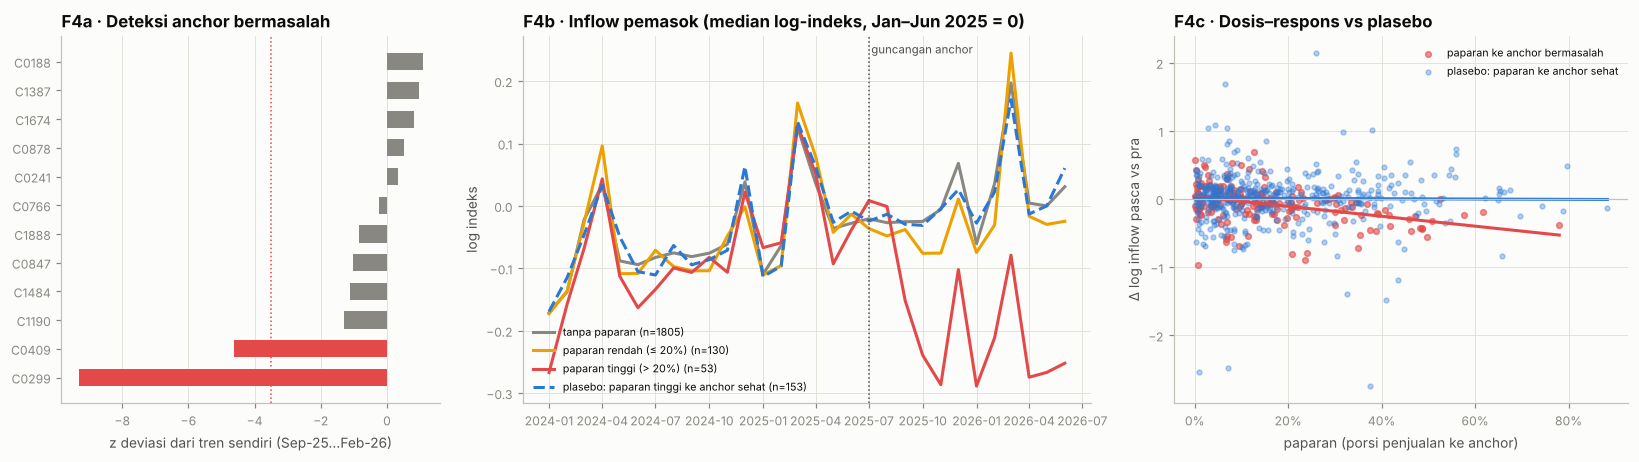

In [20]:
anchors = co.loc[co.is_anchor_candidate, 'company_id'].tolist()
months = inn.columns; xm = np.arange(len(months)); pre_m = xm < 18; post_m = (xm >= 20) & (xm < 26)   # pra: Jan-24…Jun-25; pasca: Sep-25…Feb-26
rows = []
for a in anchors:
    yv = np.log1p(inn.loc[a].values); sl, ic, *_ = stats.theilslopes(yv[pre_m], xm[pre_m]); res = yv - (ic + sl * xm)
    mad_ = 1.4826 * np.median(np.abs(res[pre_m] - np.median(res[pre_m])))
    rows.append(dict(anchor=a, industri=co.set_index('company_id').industry[a], tren_tahunan=sl * 12, deviasi_pasca=np.median(res[post_m]), z=np.median(res[post_m]) / mad_))
anc = pd.DataFrame(rows).sort_values('z'); anc['bermasalah'] = anc.z < -3.5
SHOCKED = anc.loc[anc.bermasalah, 'anchor'].tolist(); STABLE = anc.loc[~anc.bermasalah, 'anchor'].tolist()
display(anc.round(3))
print('Anchor bermasalah terdeteksi dari data:', SHOCKED)

# --- paparan pemasok (relasi jual ke anchor yang aktif per Jul 2025) ---
r_act = rel[(rel.relationship_start <= '2025-07-01') & (rel.relationship_end.isna() | (rel.relationship_end > '2025-07-01'))
            & rel.relationship_type.isin(['Customer', 'Distributor']) & rel.source_id.str.startswith('C')]
P['exp_shocked_anchor'] = r_act[r_act.target_id.isin(SHOCKED)].groupby('source_id').dependency_share.sum()
P['exp_stable_anchor'] = r_act[r_act.target_id.isin(STABLE)].groupby('source_id').dependency_share.sum()
P[['exp_shocked_anchor', 'exp_stable_anchor']] = P[['exp_shocked_anchor', 'exp_stable_anchor']].fillna(0)
P.loc[anchors, ['exp_shocked_anchor', 'exp_stable_anchor']] = np.nan                       # anchor sendiri tidak dihitung
base = inn.loc[:, '2025-01':'2025-06'].mean(axis=1)
P['inflow_chg_post'] = np.log((inn.loc[:, '2025-10':'2026-06'].mean(axis=1) + 1) / (base + 1))
idx = np.log((inn + 1).div(base + 1, axis=0))                                               # indeks log inflow relatif Jan–Jun 2025

def grp(e, cut=(0, .2)):
    return np.select([e.isna(), e <= cut[0], e <= cut[1]], ['-', 'tanpa paparan', 'paparan rendah (≤ 20%)'], 'paparan tinggi (> 20%)')
P['exp_grp'] = grp(P.exp_shocked_anchor); P['plc_grp'] = grp(P.exp_stable_anchor)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw=dict(width_ratios=[1, 1.5, 1.2]))
ax[0].barh(anc.anchor, anc.z, color=[C['s8'] if b else C['muted'] for b in anc.bermasalah], height=.6)
ax[0].axvline(-3.5, color=C['s8'], ls=':', lw=1); ax[0].set(xlabel='z deviasi dari tren sendiri (Sep-25…Feb-26)', title='F4a · Deteksi anchor bermasalah'); ax[0].grid(axis='y', visible=False)
cols = {'tanpa paparan': C['muted'], 'paparan rendah (≤ 20%)': C['s4'], 'paparan tinggi (> 20%)': C['s8']}
tt = months.to_timestamp()
for g_, col in cols.items():
    m_ = P.exp_grp == g_
    ax[1].plot(tt, idx.loc[P.index[m_]].median(), color=col, label=f'{g_} (n={m_.sum()})')
m_ = P.plc_grp == 'paparan tinggi (> 20%)'
ax[1].plot(tt, idx.loc[P.index[m_ & (P.exp_grp == 'tanpa paparan')]].median(), color=C['s1'], ls='--', label=f'plasebo: paparan tinggi ke anchor sehat (n={(m_ & (P.exp_grp == "tanpa paparan")).sum()})')
ax[1].axvline(pd.Timestamp('2025-07-01'), color=C['ink2'], lw=1, ls=':'); ax[1].text(pd.Timestamp('2025-07-05'), ax[1].get_ylim()[1] * .9, 'guncangan anchor', fontsize=7.5, color=C['ink2'])
ax[1].set(title='F4b · Inflow pemasok (median log-indeks, Jan–Jun 2025 = 0)', ylabel='log indeks'); ax[1].legend(fontsize=7, loc='lower left')
ex = P[P.exp_shocked_anchor > 0]
ax[2].scatter(ex.exp_shocked_anchor, ex.inflow_chg_post, s=14, color=C['s8'], alpha=.6, label='paparan ke anchor bermasalah')
pl = P[(P.exp_stable_anchor > 0) & (P.exp_shocked_anchor == 0)]
ax[2].scatter(pl.exp_stable_anchor, pl.inflow_chg_post, s=10, color=C['s1'], alpha=.35, label='plasebo: paparan ke anchor sehat')
for d_, col in [(ex.rename(columns={'exp_shocked_anchor': 'e'}), C['s8']), (pl.rename(columns={'exp_stable_anchor': 'e'}), C['s1'])]:
    b_ = np.polyfit(d_.e, d_.inflow_chg_post, 1); gx = np.linspace(0, d_.e.max(), 50); ax[2].plot(gx, np.polyval(b_, gx), color=col, lw=2)
ax[2].axhline(0, color=C['axis'], lw=.8); ax[2].xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax[2].set(xlabel='paparan (porsi penjualan ke anchor)', ylabel='Δ log inflow pasca vs pra', title='F4c · Dosis–respons vs plasebo'); ax[2].legend(fontsize=7)
plt.tight_layout(); save_fig(fig, 'F4_anchor_contagion'); plt.show()
rho_e, p_e = stats.spearmanr(ex.exp_shocked_anchor, ex.inflow_chg_post)
rho_p, p_p = stats.spearmanr(pl.exp_stable_anchor, pl.inflow_chg_post)
hi_e = P.loc[P.exp_grp == 'paparan tinggi (> 20%)', 'inflow_chg_post']; no_e = P.loc[P.exp_grp == 'tanpa paparan', 'inflow_chg_post']
did = hi_e.median() - no_e.median(); _, p_did = stats.mannwhitneyu(hi_e, no_e)
print(f'Dosis–respons (terpapar, n={len(ex)}): Spearman ρ = {rho_e:+.2f} (p = {p_e:.1e}) · plasebo (n={len(pl)}): ρ = {rho_p:+.2f} (p = {p_p:.2f})')
print(f'Paparan tinggi vs tanpa paparan: selisih median Δlog inflow = {did:+.3f} (≈ {np.expm1(did):+.0%}), Mann–Whitney p = {p_did:.1e}')
record('F4-dose', 'Makin bergantung pada anchor bermasalah, makin turun inflow', 'Spearman paparan vs Δinflow (terpapar)', f'ρ={rho_e:+.2f}', p_e, 'semua (tanpa label)', 'exp_shocked_anchor')
record('F4-placebo', 'Plasebo: paparan ke anchor sehat TIDAK menurunkan inflow (harapan: tidak signifikan)', 'Spearman (plasebo)', f'ρ={rho_p:+.2f}', p_p, 'semua (tanpa label)', 'kontrol validitas', expect_null=True)
dvx = dv.join(P[['exp_shocked_anchor']]).dropna(subset=['exp_shocked_anchor']); ex_d = dvx[dvx.exp_shocked_anchor > 0]
_, p_rk = stats.mannwhitneyu(dvx.loc[dvx.High == 1, 'exp_shocked_anchor'], dvx.loc[dvx.High == 0, 'exp_shocked_anchor'])
print(f'Terhadap label risiko (dev): porsi High di antara yang terpapar {ex_d.High.mean():.0%} (n={len(ex_d)}) vs tidak terpapar {dvx.loc[dvx.exp_shocked_anchor == 0, "High"].mean():.0%} · p = {p_rk:.2f}')
record('F4-risk', 'Paparan anchor bermasalah menaikkan porsi High', 'Mann–Whitney paparan High vs non-High', f'High {ex_d.High.mean():.0%} vs {dvx.loc[dvx.exp_shocked_anchor == 0, "High"].mean():.0%}', p_rk, 'dev', 'exp_shocked_anchor (untuk Why Now)')

**🔎 Cek ground truth (evaluasi saja).** Apakah dua anchor yang terdeteksi memang yang mengalami distress di dunia sintetis?

In [21]:
gtl = rd('gt_company_latent').set_index('company_id')
true_da = gtl.index[gtl.is_distressed_anchor].tolist()
print('anchor distress sebenarnya:', true_da, '→ cocok' if set(true_da) == set(SHOCKED) else '→ TIDAK cocok')
print(f'korelasi paparan hasil EDA vs paparan sebenarnya: ρ = {stats.spearmanr(P.exp_shocked_anchor.fillna(0), gtl.contagion_exposure.reindex(P.index)).correlation:.3f}')

anchor distress sebenarnya: ['C0299', 'C0409'] → cocok
korelasi paparan hasil EDA vs paparan sebenarnya: ρ = 0.972


**Arti bisnis.** Guncangan pada satu anchor merambat ke pemasoknya kira-kira **2–3 bulan kemudian**, dan besarnya sebanding dengan ketergantungan. Plasebo yang datar membuktikan efek ini bukan artefak. Begitu sebuah anchor terdeteksi bermasalah, BNI bisa **membuat daftar pemasok terdampak beserta urutan prioritasnya**, sebelum dampaknya muncul di kolektibilitas. Pada label risiko per Juni 2026, efeknya belum terlihat jelas (jumlah yang terpapar sedikit dan efeknya baru setengah tahun). Jadi nilai utama fitur ini ada di modul **"Why Now" / early warning**, bukan di klasifikasi risiko statis.

**Fitur untuk notebook 03:** `exp_shocked_anchor` (dihitung ulang setiap bulan dengan detektor patahan tren), `anchor_shock_z`, dan perluasan ke 2 lapis (paparan tidak langsung, gaya DebtRank).

### F5 · Musiman Lebaran bergeser setiap tahun → pakai regresor **hari raya bergerak**, bukan dummy bulan
**Pertanyaan.** Bagaimana cara menghilangkan efek musiman supaya penurunan inflow yang sebenarnya tidak tertutup oleh efek musim?

**Temuan.** Idulfitri jatuh pada 10 Apr 2024, 31 Mar 2025, dan 20 Mar 2026: **maju ±11 hari per tahun** mengikuti kalender Hijriah. Indeks musiman per bulan kalender (Jan–Des), yang umum dipakai, mencampur bulan "sebelum Lebaran" dan "sesudah Lebaran" dari tahun yang berbeda, sehingga puncaknya menjadi tumpul. Solusi standar di statistik resmi (X-12/X-13ARIMA; Bell & Hillmer, 1983; Findley dkk., 1998) adalah **regresor hari raya bergerak**: porsi jendela pra-Lebaran (30 hari sebelum s.d. 3 hari sesudah) yang jatuh di setiap bulan.

Regresor Lebaran menambah informasi di atas 11 dummy bulan (uji F bersarang, p < 0,05) di 6 industri: Perdagangan eceran, Industri makanan & minuman, Industri tekstil & pakaian, Perdagangan besar, Angkutan & logistik, Industri kimia.
Di 3 industri, 2 regresor menyamai/melampaui R² 11 dummy dengan BIC lebih baik: Perdagangan eceran, Industri makanan & minuman, Perdagangan besar.
Industri non-musiman (mis. konstruksi, IT, real estat) lebih cocok dengan pola kalender (Desember/awal tahun) → di FE: model musiman dipilih per industri lewat BIC.
Payroll bulan Maret (THR) = 1.89× rata-rata bulan lain.


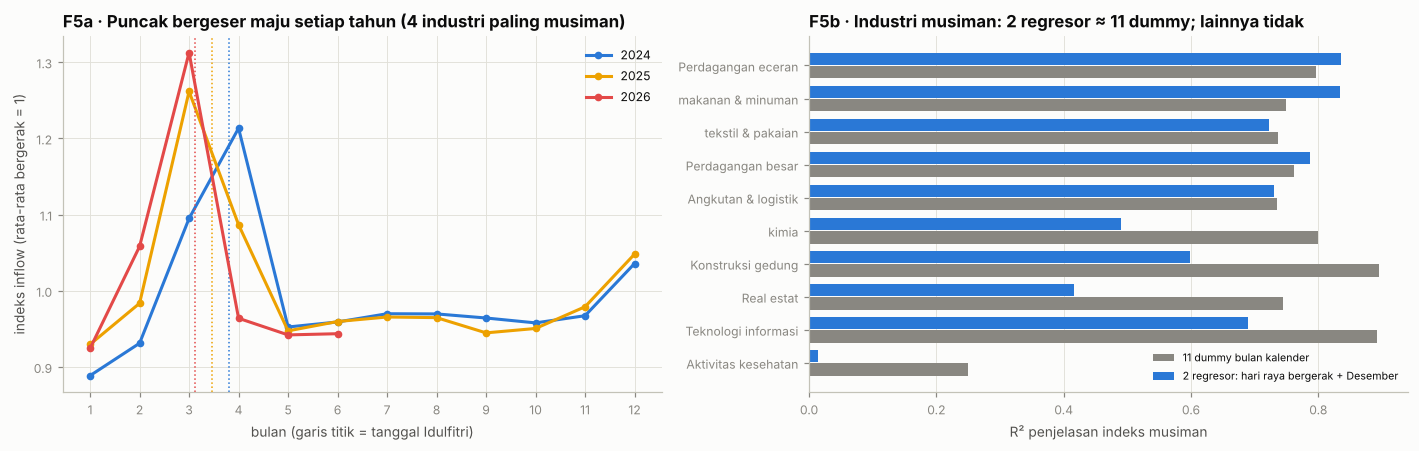

,industri,efek_lebaran,R2_dummy_bulan,R2_lebaran_des,BIC_dummy_bulan,BIC_lebaran_des,p_tambahan_lebaran,ΔBIC
7,Perdagangan eceran,0.494,0.796,0.835,-130.512,-167.507,0.000,-36.995
3,Industri makanan & minuman,0.431,0.749,0.835,-133.309,-176.499,0.001,-43.190
4,Industri tekstil & pakaian,0.367,0.737,0.723,-137.466,-166.463,0.000,-28.997
6,Perdagangan besar,0.310,0.762,0.787,-152.624,-186.587,0.002,-33.963
1,Angkutan & logistik,0.217,0.735,0.731,-163.360,-193.460,0.003,-30.100
2,Industri kimia,0.132,0.800,0.490,-190.843,-193.317,0.000,-2.474
5,Konstruksi gedung,0.100,0.896,0.598,-161.473,-151.510,0.165,9.963
8,Real estat,0.095,0.744,0.416,-177.126,-182.957,0.925,-5.831
9,Teknologi informasi,0.085,0.892,0.690,-195.281,-194.309,0.166,0.972
0,Aktivitas kesehatan,0.002,0.249,0.014,-147.993,-170.408,0.692,-22.415


In [22]:
LEB_DATES = [pd.Timestamp(d) for d in LEBARAN]
def lebaran_exposure(period, before=30, after=3):
    s_, e_ = period.start_time, period.end_time.normalize(); tot = 0
    for L_ in LEB_DATES:
        a_, b_ = max(s_, L_ - pd.Timedelta(days=before)), min(e_, L_ + pd.Timedelta(days=after)); tot += max(0, (b_ - a_).days + 1)
    return tot / (before + after + 1)
cli_ids_set = set(cli_ids)
xi_ = tx[(tx.direction == 'IN') & tx.company_id.isin(cli_ids_set)].merge(co[['company_id', 'industry']], on='company_id')
mi = xi_.groupby(['industry', 'ym']).amount_idr_mn.sum().unstack()
SI = mi.div(mi.T.rolling(12, center=True, min_periods=6).mean().T)          # indeks musiman = rasio terhadap rata-rata bergerak 12 bln
leb = pd.Series([lebaran_exposure(p_) for p_ in mi.columns], index=mi.columns); dec = pd.Series((mi.columns.month == 12).astype(float), index=mi.columns)

def ols(X, yv):
    X = np.column_stack([np.ones(len(yv)), X]); b, *_ = np.linalg.lstsq(X, yv, rcond=None); rss = ((yv - X @ b) ** 2).sum(); return b, rss, X.shape[1]
rows = []
for ind_, sr in SI.iterrows():
    sr = sr.dropna(); yv = sr.values; n = len(yv); per = sr.index
    MD = pd.get_dummies(per.month, drop_first=True).astype(float).values
    b2, rss2, k2 = ols(np.column_stack([leb[per], dec[per]]), yv)
    _, rss1, k1 = ols(MD, yv)
    _, rss3, k3 = ols(np.column_stack([MD, leb[per]]), yv)                  # nested: dummy bulan + Lebaran
    bic = lambda rss, k: n * np.log(rss / n) + k * np.log(n)
    F = (rss1 - rss3) / (rss3 / (n - k3)); pF = stats.f.sf(F, 1, n - k3)
    tss = ((yv - yv.mean()) ** 2).sum()
    rows.append(dict(industri=ind_, efek_lebaran=b2[1], R2_dummy_bulan=1 - rss1 / tss, R2_lebaran_des=1 - rss2 / tss,
                     BIC_dummy_bulan=bic(rss1, k1), BIC_lebaran_des=bic(rss2, k2), p_tambahan_lebaran=pF))
f5 = pd.DataFrame(rows).sort_values('efek_lebaran', ascending=False); f5['ΔBIC'] = f5.BIC_lebaran_des - f5.BIC_dummy_bulan

SEAS = f5.industri.head(4).tolist()
agg = mi.loc[SEAS].sum(); agg_i = (agg / agg.rolling(12, center=True, min_periods=6).mean())
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for yr, col in zip([2024, 2025, 2026], [C['s1'], C['s4'], C['s8']]):
    s_ = agg_i[agg_i.index.year == yr]; ax[0].plot(s_.index.month, s_.values, marker='o', ms=4, color=col, label=str(yr))
    Ld = LEB_DATES[yr - 2024]; ax[0].axvline(Ld.month + (Ld.day - 1) / Ld.days_in_month - .5, color=col, ls=':', lw=1)
ax[0].set_xticks(range(1, 13)); ax[0].set(xlabel='bulan (garis titik = tanggal Idulfitri)', ylabel='indeks inflow (rata-rata bergerak = 1)',
                                         title='F5a · Puncak bergeser maju setiap tahun (4 industri paling musiman)'); ax[0].legend()
yy = np.arange(len(f5))
ax[1].barh(yy + .2, f5.R2_dummy_bulan, height=.38, color=C['muted'], label='11 dummy bulan kalender')
ax[1].barh(yy - .2, f5.R2_lebaran_des, height=.38, color=C['s1'], label='2 regresor: hari raya bergerak + Desember')
ax[1].set_yticks(yy); ax[1].set_yticklabels([s_.replace('Industri ', '') for s_ in f5.industri]); ax[1].invert_yaxis(); ax[1].grid(axis='y', visible=False)
ax[1].set(xlabel='R² penjelasan indeks musiman', title='F5b · Industri musiman: 2 regresor ≈ 11 dummy; lainnya tidak'); ax[1].legend(loc='lower right', fontsize=7)
plt.tight_layout(); save_fig(fig, 'F5_moving_holiday'); plt.show()
display(f5.round(3))
pay_m = pay.groupby('ym').amount_idr_mn.sum(); thr_ratio = pay_m[pay_m.index.month == 3].mean() / pay_m[pay_m.index.month != 3].mean()
sig_ = f5[f5.p_tambahan_lebaran < .05]
print(f'Regresor Lebaran menambah informasi di atas 11 dummy bulan (uji F bersarang, p < 0,05) di {len(sig_)} industri: {", ".join(sig_.industri)}.')
better = f5[(f5.R2_lebaran_des >= f5.R2_dummy_bulan) & (f5['ΔBIC'] < 0)]
print(f'Di {len(better)} industri, 2 regresor menyamai/melampaui R² 11 dummy dengan BIC lebih baik: {", ".join(better.industri)}.')
print('Industri non-musiman (mis. konstruksi, IT, real estat) lebih cocok dengan pola kalender (Desember/awal tahun) → di FE: model musiman dipilih per industri lewat BIC.')
print(f'Payroll bulan Maret (THR) = {thr_ratio:.2f}× rata-rata bulan lain.')
p_best = f5.p_tambahan_lebaran.iloc[0]
record('F5-lebaran', f'Regresor Lebaran menambah informasi di atas dummy bulan ({f5.industri.iloc[0]})', 'uji F bersarang', f"ΔBIC={f5['ΔBIC'].iloc[0]:.1f}", p_best, 'nasabah (tanpa label)', 'inflow_deseasonalized (regresor Lebaran per industri)')

**Arti bisnis.** Tanpa koreksi yang benar, penurunan inflow di bulan April 2026 terlihat "mengkhawatirkan", padahal itu hanya efek **Lebaran 2026 yang jatuh lebih awal**. Peringatan palsu ke RM akan berkurang.

**Fitur untuk notebook 03:** inflow yang sudah dikoreksi musiman. Model musimannya dipilih per industri: regresor Lebaran + Desember untuk industri musiman, dummy kalender untuk industri lain (pilih lewat BIC; koefisien di tabel di atas). Bulan Maret ditandai khusus untuk payroll karena THR. Pertumbuhan dan tren dihitung **setelah** koreksi ini.

### F6 · Erosi *share of wallet*: omzet tetap tumbuh, inflow ke BNI turun
**Pertanyaan.** Nasabah yang mulai memindahkan transaksinya ke bank lain tidak terlihat sebagai "risiko". Mereka **kehilangan peluang** yang diam-diam. Bisakah dideteksi?

**Metode.** Ada dua besaran:
- **Capture ratio** = inflow yang terlihat di BNI ÷ omzet di laporan keuangan. Ini proxy *share of wallet* (Du dkk., 2007).
- **Divergensi** = pertumbuhan inflow BNI (H1-2026 vs H1-2025) − pertumbuhan omzet (2025 vs 2024). Nilai yang sangat negatif berarti bisnis nasabah tidak menyusut, tapi uangnya tidak lagi lewat BNI.

69 nasabah (5.0%) berdivergensi ekstrem. Distribusi divergensi miring ke kiri (skew z = -11.4, p = 2.9e-30).
Median capture ratio 56%: rata-rata hanya sekitar separuh omzet nasabah yang lewat BNI → ruang deepening besar.


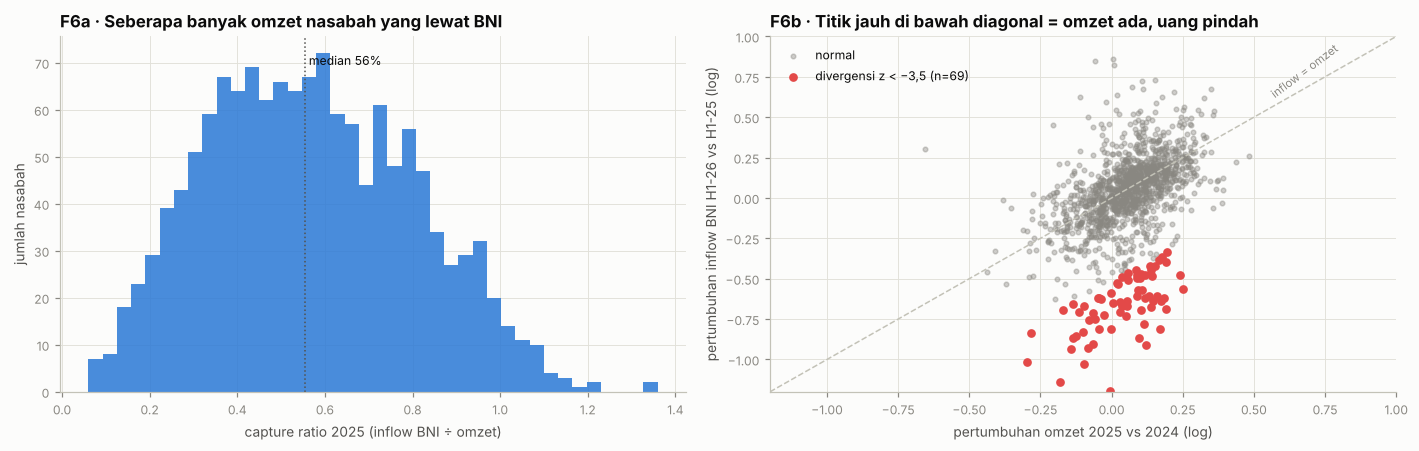

In [23]:
rev = fin.pivot(index='company_id', columns='fiscal_year', values='revenue_idr_bn')
w = pd.DataFrame(index=cli_ids).join(rev)
w['capture_2025'] = inn.loc[:, '2025-01':'2025-12'].sum(axis=1).reindex(w.index) / (w[2025] * 1000)
w['g_inflow'] = np.log(inn.loc[:, '2026-01':'2026-06'].sum(axis=1) / inn.loc[:, '2025-01':'2025-06'].sum(axis=1)).reindex(w.index)
w['g_revenue'] = np.log(w[2025] / w[2024])
w['divergence'] = w.g_inflow - w.g_revenue
w = w.dropna(subset=['divergence'])
w['div_z'] = robust_z(w.divergence)
w['erosi_flag'] = w.div_z < -3.5
P = P.join(w[['capture_2025', 'divergence', 'div_z']])
sk, p_sk = stats.skewtest(w.divergence)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].hist(w.capture_2025.clip(0, 1.4), bins=40, color=C['s1'], alpha=.85)
ax[0].set(xlabel='capture ratio 2025 (inflow BNI ÷ omzet)', ylabel='jumlah nasabah', title='F6a · Seberapa banyak omzet nasabah yang lewat BNI')
ax[0].axvline(w.capture_2025.median(), color=C['ink2'], ls=':', lw=1); ax[0].text(w.capture_2025.median(), ax[0].get_ylim()[1] * .92, f' median {w.capture_2025.median():.0%}', fontsize=8)
nf = w[~w.erosi_flag]; fl = w[w.erosi_flag]
ax[1].scatter(nf.g_revenue, nf.g_inflow, s=9, color=C['muted'], alpha=.4, label='normal')
ax[1].scatter(fl.g_revenue, fl.g_inflow, s=22, color=C['s8'], label=f'divergensi z < −3,5 (n={len(fl)})')
lim = [-1.2, 1.0]; ax[1].plot(lim, lim, color=C['axis'], lw=1, ls='--'); ax[1].text(.55, .62, 'inflow = omzet', fontsize=7.5, color=C['muted'], rotation=37)
ax[1].set(xlim=lim, ylim=lim, xlabel='pertumbuhan omzet 2025 vs 2024 (log)', ylabel='pertumbuhan inflow BNI H1-26 vs H1-25 (log)',
          title='F6b · Titik jauh di bawah diagonal = omzet ada, uang pindah'); ax[1].legend(loc='upper left')
plt.tight_layout(); save_fig(fig, 'F6_wallet_erosion'); plt.show()
print(f'{w.erosi_flag.sum()} nasabah ({w.erosi_flag.mean():.1%}) berdivergensi ekstrem. Distribusi divergensi miring ke kiri (skew z = {sk:.1f}, p = {p_sk:.1e}).')
print(f'Median capture ratio {w.capture_2025.median():.0%}: rata-rata hanya sekitar separuh omzet nasabah yang lewat BNI → ruang deepening besar.')
record('F6-erosion', 'Ada kelompok nasabah dengan inflow BNI turun jauh lebih cepat dari omzet (ekor kiri)', 'uji kemiringan D’Agostino', f'skew z={sk:.1f}', p_sk, 'nasabah (tanpa label)', 'divergence, div_z, capture_ratio')

**🔎 Cek ground truth (evaluasi saja).**

In [24]:
we = w.join(gtl[['wallet_erosion', 'wallet_share_bni']])
print(f'AUC divergensi → erosi sebenarnya: {auc(we.wallet_erosion, -we.divergence):.3f} · presisi flag z < −3,5: {we.loc[we.erosi_flag, "wallet_erosion"].mean():.0%} '
      f'· recall: {we.loc[we.wallet_erosion, "erosi_flag"].mean():.0%}')
print(f'Capture ratio vs share of wallet sebenarnya: Spearman ρ = {stats.spearmanr(we.capture_2025, we.wallet_share_bni).correlation:.3f}')

AUC divergensi → erosi sebenarnya: 0.956 · presisi flag z < −3,5: 81% · recall: 65%
Capture ratio vs share of wallet sebenarnya: Spearman ρ = 0.962


**Arti bisnis.** Capture ratio adalah proxy *share of wallet* yang sangat akurat, dan bisa dihitung untuk setiap nasabah yang punya laporan keuangan. Dari sini Opportunity Score bisa menghitung **ukuran peluang dalam rupiah**: (1 − capture) × omzet. Divergensi yang ekstrem memberi daftar nasabah untuk **retensi segera**.

**Fitur untuk notebook 03:** `capture_ratio`, `divergence`, `div_z`, dan `wallet_gap_idr` = (1 − capture) × omzet, dengan inflow sudah dikoreksi musiman (F5). **Batasan:** butuh laporan keuangan, jadi tidak tersedia untuk perusahaan yang tidak melapor (D2).

### F7 · *White-space*: di mana dan produk apa yang belum digarap
**F7a — Geografis.** Penetrasi BNI per kecamatan diukur sebagai porsi perusahaan inti yang sudah menjadi nasabah. Lalu penetrasi itu dibandingkan dengan potensi kecamatan (jumlah korporasi, kawasan industri) dan keberadaan cabang.

Kawasan industri padat TANPA cabang: penetrasi median 40% (n=6) vs padat DENGAN cabang 85% (n=8), Mann–Whitney p = 0.005. Semua kecamatan: tanpa cabang 80% vs dengan cabang 83%.
Korelasi jumlah kawasan industri–penetrasi: ρ = -0.31 (p = 0.048). Jarak ke cabang terdekat bukan penjelasnya (mis. Cakung hanya 0.9 km dari cabang).
Omzet prospect yang melapor di 6 kecamatan white-space: Rp9.2 T (batas bawah, karena tidak semua prospect melapor).


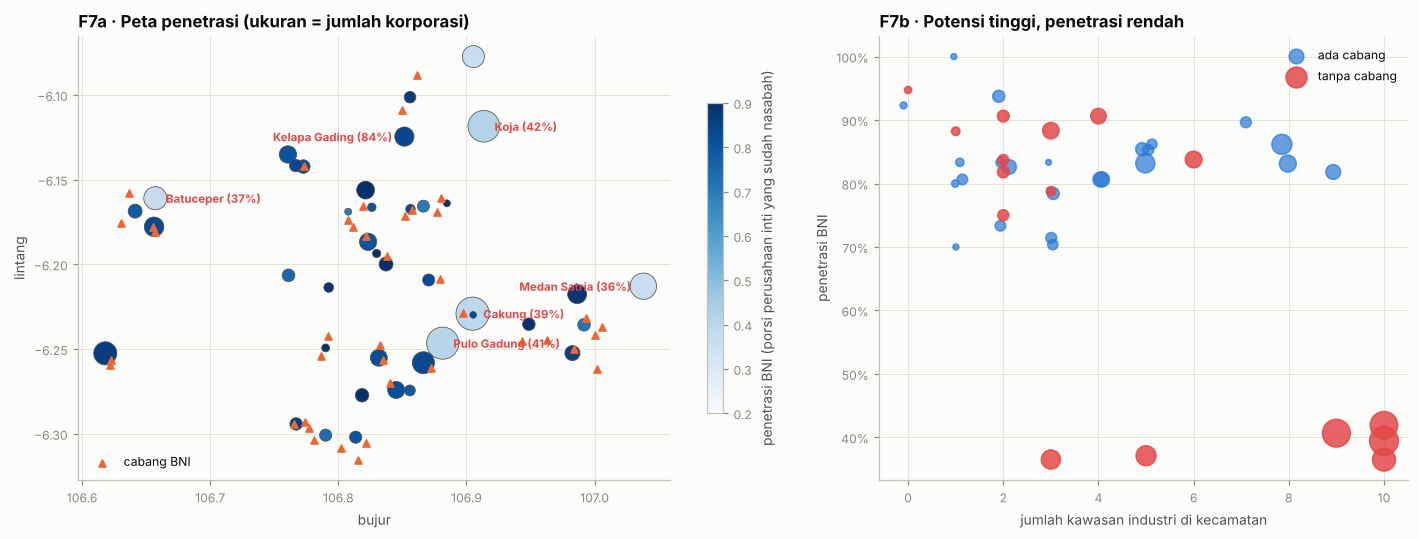

,district,city,perusahaan,penetrasi,cabang,jarak_cabang_km,poi_industrial_count,corporate_count,omzet_prospect_Rp_T
location_id,,,,,,,,,
L036,Medan Satria,Kota Bekasi,74,0.36,0,4.44,10,1782,1.60
L040,Batuceper,Kota Tangerang,62,0.37,0,1.87,5,1363,0.59
L027,Cakung,Jakarta Timur,180,0.39,0,0.85,10,2821,3.78
L028,Pulo Gadung,Jakarta Timur,123,0.41,0,1.91,9,2650,1.71
L017,Koja,Jakarta Utara,105,0.42,0,5.95,10,2584,1.35
L019,Kelapa Gading,Jakarta Utara,74,0.84,0,1.73,6,952,0.15


In [25]:
def hav(a1, o1, a2, o2):
    a1, o1, a2, o2 = map(np.radians, [a1, o1, a2, o2])
    return 6371 * 2 * np.arcsin(np.sqrt(np.sin((a2 - a1) / 2) ** 2 + np.cos(a1) * np.cos(a2) * np.sin((o2 - o1) / 2) ** 2))
co['is_client'] = co.customer_type != 'Prospect'
co['dist_branch_km'] = hav(co.latitude.values[:, None], co.longitude.values[:, None], br.latitude.values[None], br.longitude.values[None]).min(axis=1)
P['dist_branch_km'] = co.set_index('company_id').dist_branch_km
gd = co.groupby('location_id').agg(perusahaan=('company_id', 'size'), penetrasi=('is_client', 'mean')).join(geo.set_index('location_id'))
gd['cabang'] = br.groupby('location_id').size().reindex(gd.index).fillna(0).astype(int)
gd['jarak_cabang_km'] = hav(gd.centroid_lat.values[:, None], gd.centroid_lon.values[:, None], br.latitude.values[None], br.longitude.values[None]).min(axis=1)
pros_rev = fin[fin.fiscal_year == 2025].set_index('company_id').revenue_idr_bn
co['rev25'] = co.company_id.map(pros_rev)
gd['omzet_prospect_Rp_T'] = co[~co.is_client].groupby('location_id').rev25.sum().reindex(gd.index).fillna(0) / 1000
nb_ = gd[gd.cabang == 0]; wb_ = gd[gd.cabang > 0]
dense = gd.poi_industrial_count >= gd.poi_industrial_count.quantile(.75)          # kawasan industri padat (kuartil atas), ditetapkan sebelum melihat penetrasi
ws = gd[dense & (gd.cabang == 0)].sort_values('penetrasi'); ctrl = gd[dense & (gd.cabang > 0)]
u, p_ws = stats.mannwhitneyu(ws.penetrasi, ctrl.penetrasi)
rho_poi, p_poi = stats.spearmanr(gd.poi_industrial_count, gd.penetrasi)
fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw=dict(width_ratios=[1.4, 1]))
sc = ax[0].scatter(gd.centroid_lon, gd.centroid_lat, s=gd.corporate_count / 6, c=gd.penetrasi, cmap='Blues', vmin=.2, vmax=.9, edgecolor=C['ink2'], linewidth=.5)
ax[0].scatter(br.longitude, br.latitude, marker='^', s=22, color=C['s2'], label='cabang BNI', zorder=3)
for i, r in ws.iterrows(): ax[0].annotate(f'{r.district} ({r.penetrasi:.0%})', (r.centroid_lon, r.centroid_lat), xytext=(-8, -3) if r.district in ('Kelapa Gading', 'Medan Satria') else (7, -3),
                                          ha='right' if r.district in ('Kelapa Gading', 'Medan Satria') else 'left', textcoords='offset points', fontsize=7.5, color=C['s8'], fontweight='bold')
plt.colorbar(sc, ax=ax[0], shrink=.7, label='penetrasi BNI (porsi perusahaan inti yang sudah nasabah)')
ax[0].set(xlabel='bujur', ylabel='lintang', title='F7a · Peta penetrasi (ukuran = jumlah korporasi)'); ax[0].legend(loc='lower left')
ax[1].scatter(wb_.poi_industrial_count + rng_global.uniform(-.15, .15, len(wb_)), wb_.penetrasi, s=wb_.corporate_count / 8, color=C['s1'], alpha=.7, label='ada cabang')
ax[1].scatter(nb_.poi_industrial_count, nb_.penetrasi, s=nb_.corporate_count / 8, color=C['s8'], alpha=.85, label='tanpa cabang')
ax[1].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax[1].set(xlabel='jumlah kawasan industri di kecamatan', ylabel='penetrasi BNI', title='F7b · Potensi tinggi, penetrasi rendah'); ax[1].legend()
plt.tight_layout(); save_fig(fig, 'F7a_geo_whitespace'); plt.show()
display(ws[['district', 'city', 'perusahaan', 'penetrasi', 'cabang', 'jarak_cabang_km', 'poi_industrial_count', 'corporate_count', 'omzet_prospect_Rp_T']].round(2))
print(f'Kawasan industri padat TANPA cabang: penetrasi median {ws.penetrasi.median():.0%} (n={len(ws)}) vs padat DENGAN cabang {ctrl.penetrasi.median():.0%} '
      f'(n={len(ctrl)}), Mann–Whitney p = {p_ws:.3f}. Semua kecamatan: tanpa cabang {nb_.penetrasi.median():.0%} vs dengan cabang {wb_.penetrasi.median():.0%}.')
print(f'Korelasi jumlah kawasan industri–penetrasi: ρ = {rho_poi:+.2f} (p = {p_poi:.3f}). Jarak ke cabang terdekat bukan penjelasnya '
      f'(mis. {ws.district.iloc[ws.jarak_cabang_km.argmin()]} hanya {ws.jarak_cabang_km.min():.1f} km dari cabang).')
print(f'Omzet prospect yang melapor di {len(ws)} kecamatan white-space: Rp{ws.omzet_prospect_Rp_T.sum():.1f} T (batas bawah, karena tidak semua prospect melapor).')
record('F7-geo', 'Kawasan industri padat tanpa cabang berpenetrasi lebih rendah', 'Mann–Whitney level kecamatan (padat: tanpa vs dengan cabang)', f'{ws.penetrasi.median():.0%} vs {ctrl.penetrasi.median():.0%}', p_ws, 'semua (tanpa label)', 'district_penetration, district_poi_industrial, has_branch_in_district')

**F7b — Produk.** Ada dua lensa untuk white-space produk:
1. **Lift co-holding** antar produk (Brin dkk., 1997): produk mana yang biasanya dipegang bersama.
2. **Celah peer**: produk yang dipegang ≥ 50% perusahaan sejenis (industri × ukuran), tetapi belum dimiliki nasabah ini.

592 pasangan nasabah–produk masuk celah peer (37% nasabah punya ≥ 1 celah). Payroll: hanya 21% nasabah memakai payroll BNI → kaitkan dengan F2: sinyal timing gaji hanya ada untuk mereka.


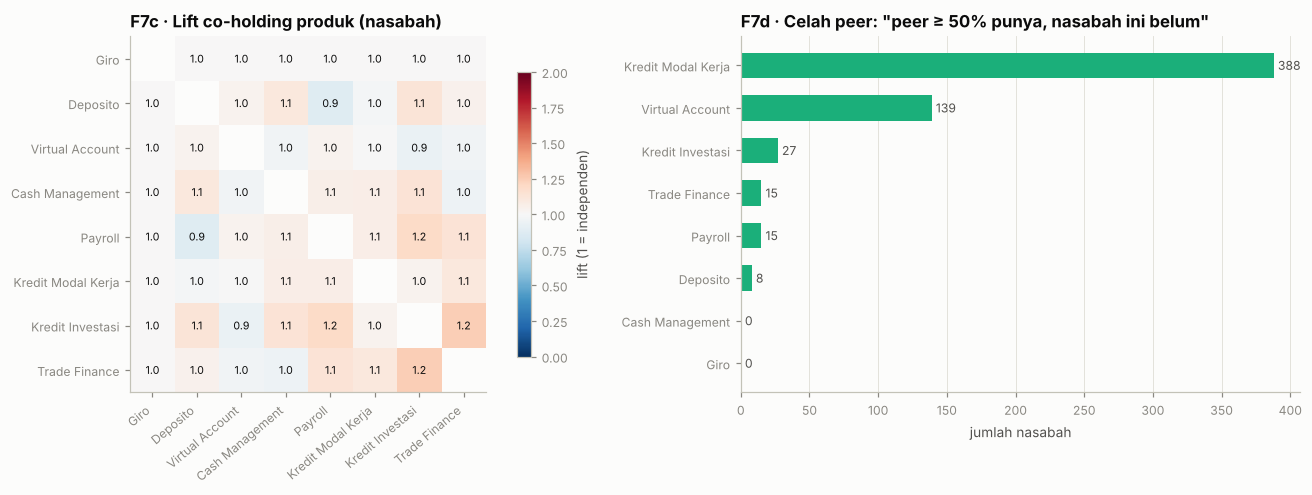

In [26]:
H = ph[ph.active == 1].pivot_table(index='company_id', columns='product_id', values='active', aggfunc='max', fill_value=0)
H = H.reindex(cli_ids, fill_value=0)
pn = pm.set_index('product_id').product_name
supp = H.mean(); co_ = (H.T @ H) / len(H); lv = (co_ / np.outer(supp, supp)).to_numpy(dtype=float, copy=True); np.fill_diagonal(lv, np.nan)
lift = pd.DataFrame(lv, index=H.columns, columns=H.columns)
Hc = H.join(co.set_index('company_id')[['industry', 'size_class_reference']])
peer_rate = Hc.groupby(['industry', 'size_class_reference'])[H.columns].transform('mean')
gap = (peer_rate >= .5) & (H == 0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[1.1, 1]))
im = ax[0].imshow(lift.values, cmap='RdBu_r', vmin=0, vmax=2); ax[0].grid(False)
lab_p = [pn[c] for c in lift.columns]
ax[0].set_xticks(range(8)); ax[0].set_xticklabels(lab_p, rotation=40, ha='right'); ax[0].set_yticks(range(8)); ax[0].set_yticklabels(lab_p)
for i in range(8):
    for j in range(8):
        if i != j: ax[0].text(j, i, f'{lift.values[i, j]:.1f}', ha='center', va='center', fontsize=7, color=C['ink'])
plt.colorbar(im, ax=ax[0], shrink=.8, label='lift (1 = independen)'); ax[0].set_title('F7c · Lift co-holding produk (nasabah)')
gp = gap.sum().rename(index=pn).sort_values()
ax[1].barh(gp.index, gp.values, color=C['s3'], height=.6)
for i, v in enumerate(gp.values): ax[1].text(v + 3, i, f'{v}', va='center', fontsize=8, color=C['ink2'])
ax[1].set(xlabel='jumlah nasabah', title='F7d · Celah peer: "peer ≥ 50% punya, nasabah ini belum"'); ax[1].grid(axis='y', visible=False)
plt.tight_layout(); save_fig(fig, 'F7c_product_whitespace'); plt.show()
print(f'{int(gap.values.sum())} pasangan nasabah–produk masuk celah peer ({gap.any(axis=1).mean():.0%} nasabah punya ≥ 1 celah). '
      f'Payroll: hanya {supp["P05"]:.0%} nasabah memakai payroll BNI → kaitkan dengan F2: sinyal timing gaji hanya ada untuk mereka.')

**🔎 Cek ground truth (evaluasi saja).** Apakah celah peer benar-benar mencerminkan kebutuhan?

In [27]:
need = rd('gt_product_need').pivot(index='company_id', columns='product_id', values='true_need').reindex(H.index)
notheld = (H == 0)
base_rate = need[notheld].stack().mean(); gap_rate = need[gap].stack().mean()
print(f'Di antara produk yang belum dimiliki: kebutuhan nyata {base_rate:.0%} (dasar) vs {gap_rate:.0%} bila masuk celah peer (lift {gap_rate / base_rate:.2f}×).')

Di antara produk yang belum dimiliki: kebutuhan nyata 13% (dasar) vs 21% bila masuk celah peer (lift 1.57×).


**Arti bisnis.** Lima kecamatan kawasan industri padat tanpa cabang (Medan Satria, Batuceper, Cakung, Pulo Gadung, Koja) punya penetrasi hanya 36–42%, padahal kecamatan sejenis yang punya cabang jauh lebih tinggi. Pengecualian yang menarik: Kelapa Gading, tanpa cabang tetapi penetrasinya 84%, jadi tidak adanya cabang saja tidak menentukan. Kelima kecamatan itu adalah kandidat **sentra bisnis baru atau penugasan RM khusus kawasan industri**. Untuk produk, celah peer adalah heuristik cepat yang sudah lebih tajam daripada menawarkan acak. Di notebook 04, heuristik ini menjadi baseline untuk model propensity.

**Fitur untuk notebook 03:** `district_penetration`, `dist_branch_km`, `district_poi_industrial`, `peer_adoption_rate_<produk>`, `n_products`, dan lift dari produk yang sudah dimiliki.

### F8 · Jaringan ekosistem: komunitas mengikuti **kota**, risiko **tidak menular lewat tetangga**
**Pertanyaan.** Apa yang sebenarnya dikodekan oleh struktur jaringan rantai pasok, dan apakah risiko "menular" ke tetangga langsung?

Graf aktif: 5,818 simpul, 19,747 sisi, modularitas 0.54; subgraf berlabel dev: 2690 sisi.
  AUC degree       → High (dev): 0.422
  AUC pagerank     → High (dev): 0.431
  AUC core_number  → High (dev): 0.440


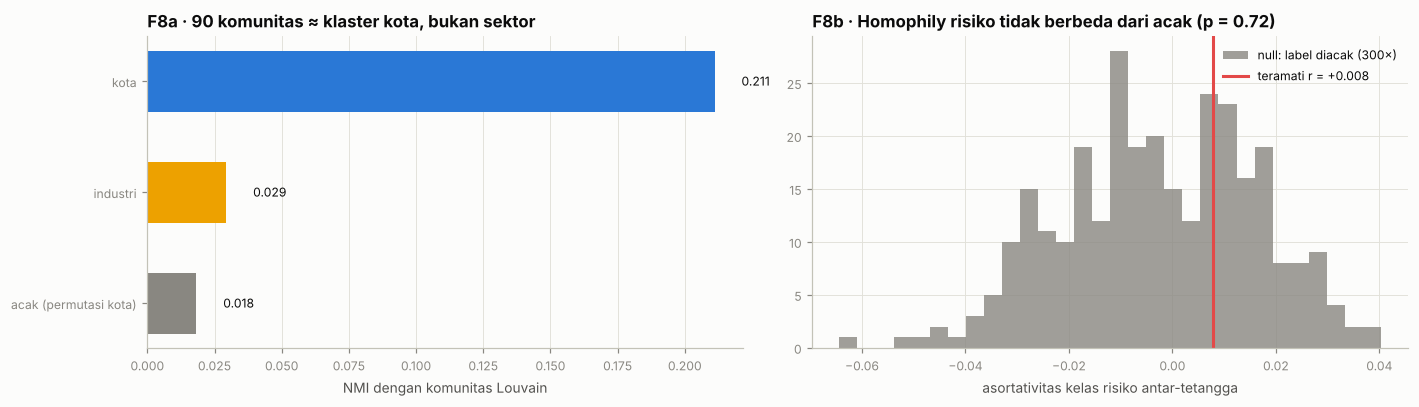

In [28]:
ract = rel[(rel.relationship_start <= CUTOFF) & (rel.relationship_end.isna() | (rel.relationship_end > CUTOFF))]
G = nx.Graph(); G.add_edges_from(ract[['source_id', 'target_id']].values)
comm = nx.community.louvain_communities(G, seed=SEED); cmap_ = {n: i for i, c_ in enumerate(comm) for n in c_}
attr = pd.concat([co.set_index('company_id')[['city', 'industry']], ne.set_index('entity_id')[['city', 'industry']]])
nodes = [n for n in G if n in attr.index]; cid_ = [cmap_[n] for n in nodes]
nmi_city = normalized_mutual_info_score(attr.loc[nodes, 'city'], cid_); nmi_ind = normalized_mutual_info_score(attr.loc[nodes, 'industry'], cid_)
nmi_rand = np.mean([normalized_mutual_info_score(rng_global.permutation(attr.loc[nodes, 'city'].values), cid_) for _ in range(20)])
P['degree'] = pd.Series(dict(G.degree())); P['pagerank'] = pd.Series(nx.pagerank(G)) * len(G); P['core_number'] = pd.Series(nx.core_number(G))
P[['degree', 'pagerank', 'core_number']] = P[['degree', 'pagerank', 'core_number']].fillna(0)
# homophily risiko: tetangga langsung antar-nasabah berlabel (dev saja)
lab_dev = rl.set_index('company_id').risk_class.reindex(DEV).map({'Low': 0, 'Medium': 1, 'High': 2})
Hs = G.subgraph([n for n in DEV if n in G]).copy(); nx.set_node_attributes(Hs, lab_dev.to_dict(), 'r')
obs_as = nx.numeric_assortativity_coefficient(Hs, 'r'); nodes_h = list(Hs.nodes); vals = np.array([lab_dev[n] for n in nodes_h])
null = []
for _ in range(300):
    nx.set_node_attributes(Hs, dict(zip(nodes_h, rng_global.permutation(vals))), 'r'); null.append(nx.numeric_assortativity_coefficient(Hs, 'r'))
p_as = (1 + np.sum(np.abs(null) >= abs(obs_as))) / 301
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].barh(['acak (permutasi kota)', 'industri', 'kota'], [nmi_rand, nmi_ind, nmi_city], color=[C['muted'], C['s4'], C['s1']], height=.55)
for i, v in enumerate([nmi_rand, nmi_ind, nmi_city]): ax[0].text(v + .01, i, f'{v:.3f}', va='center', fontsize=8)
ax[0].set(xlabel='NMI dengan komunitas Louvain', title=f'F8a · {len(comm)} komunitas ≈ klaster kota, bukan sektor'); ax[0].grid(axis='y', visible=False)
ax[1].hist(null, bins=30, color=C['muted'], alpha=.8, label='null: label diacak (300×)'); ax[1].axvline(obs_as, color=C['s8'], lw=2, label=f'teramati r = {obs_as:+.3f}')
ax[1].set(xlabel='asortativitas kelas risiko antar-tetangga', title=f'F8b · Homophily risiko tidak berbeda dari acak (p = {p_as:.2f})'); ax[1].legend()
plt.tight_layout(); save_fig(fig, 'F8_network'); plt.show()
print(f'Graf aktif: {G.number_of_nodes():,} simpul, {G.number_of_edges():,} sisi, modularitas {nx.community.modularity(G, comm):.2f}; subgraf berlabel dev: {Hs.number_of_edges()} sisi.')
for c in ['degree', 'pagerank', 'core_number']: print(f'  AUC {c:12s} → High (dev): {auc(dv.High, P.loc[dv.index, c]):.3f}')
record('F8-community', 'Komunitas jaringan lebih selaras dengan kota daripada industri', 'NMI (kota vs permutasi)', f'NMI kota {nmi_city:.2f} vs industri {nmi_ind:.2f}',
       (1 + sum(normalized_mutual_info_score(rng_global.permutation(attr.loc[nodes, 'city'].values), cid_) >= nmi_city for _ in range(50))) / 51, 'semua (tanpa label)', 'community_id → agregat per komunitas')
record('F8-homophily', 'Risiko berkorelasi dengan tetangga langsung', 'asortativitas + permutasi', f'r={obs_as:+.3f}', p_as, 'dev', 'TIDAK prioritas: risiko rata-rata tetangga')

**Daftar prospek ekosistem.** Mitra dalam jaringan yang **belum menjadi nasabah BNI**, tetapi bertransaksi dengan banyak nasabah BNI, adalah target akuisisi yang "hangat". Mereka sudah punya hubungan dagang dengan ekosistem BNI.

In [29]:
cl_set = set(cli_ids)
non_bni = set(ne.loc[~ne.is_bni_customer, 'entity_id']) | set(co.loc[~co.is_client, 'company_id'])
e1 = ract[ract.source_id.isin(cl_set) & ract.target_id.isin(non_bni)].rename(columns={'target_id': 'mitra', 'source_id': 'nasabah'})
e2 = ract[ract.target_id.isin(cl_set) & ract.source_id.isin(non_bni)].rename(columns={'source_id': 'mitra', 'target_id': 'nasabah'})
eco = pd.concat([e1, e2]).groupby('mitra').agg(nasabah_BNI_terhubung=('nasabah', 'nunique'), nilai_tahunan_Rp_M=('annual_transaction_value_idr_mn', 'sum'))
eco['nilai_tahunan_Rp_M'] = (eco.nilai_tahunan_Rp_M / 1000).round(1)
eco = eco.join(attr).sort_values(['nasabah_BNI_terhubung', 'nilai_tahunan_Rp_M'], ascending=False)
print(f'{len(eco):,} mitra non-BNI terhubung ke nasabah BNI; {(eco.nasabah_BNI_terhubung >= 5).sum()} di antaranya terhubung ke ≥ 5 nasabah.')
display(eco.head(10))
P['n_nonbni_partners'] = pd.concat([e1.groupby('nasabah').mitra.nunique(), e2.groupby('nasabah').mitra.nunique()]).groupby(level=0).sum()
P['n_nonbni_partners'] = P.n_nonbni_partners.fillna(0)

1,425 mitra non-BNI terhubung ke nasabah BNI; 542 di antaranya terhubung ke ≥ 5 nasabah.


,nasabah_BNI_terhubung,nilai_tahunan_Rp_M,city,industry
mitra,,,,
C0847,37,423.6,Jakarta Utara,Perdagangan eceran
C1660,37,305.8,Jakarta Timur,Industri makanan & minuman
E00623,35,177.8,Kota Tangerang,Perdagangan eceran
E01266,31,381.2,Jakarta Timur,Perdagangan eceran
E00459,29,377.9,Jakarta Selatan,Perdagangan eceran
C1958,27,135.1,Jakarta Utara,Angkutan & logistik
C1230,27,73.8,Jakarta Timur,Perdagangan besar
C1297,26,307.2,Kota Tangerang,Industri makanan & minuman
C1696,25,303.4,Jakarta Utara,Industri makanan & minuman


**Kesimpulan F8 (termasuk hasil negatif).** Struktur jaringan terutama mengodekan **geografi** (klaster industri per kota). Risiko **tidak** menular lewat tetangga langsung secara umum. Satu-satunya jalur penularan yang terbukti adalah ketergantungan pada anchor yang bermasalah (F4). Ini konsisten dengan catatan notebook 01 bahwa efek grup usaha lemah. Sentralitas (derajat, PageRank) sedikit **protektif**: perusahaan yang terhubung ke banyak pihak cenderung lebih sehat.

**Fitur untuk notebook 03:** `degree`, `pagerank`, `core_number`, `n_nonbni_partners` (peluang akuisisi), dan `exp_shocked_anchor` (F4). Fitur "rata-rata risiko tetangga" **tidak diprioritaskan**.

### F9 · Catatan kunjungan RM: kata kunci saja menyesatkan karena **negasi**
**Pertanyaan.** Bisakah masalah nasabah diekstrak dari catatan kunjungan RM dengan pencocokan kata kunci (`issue_product_map.keywords`)?

**Metode.** Dua ekstraktor dibandingkan:
1. **naif**: kata kunci muncul → masalah ada;
2. **sadar-negasi gaya NegEx** (Chapman dkk., 2001): kalimat yang mengandung penanda negasi Indonesia ("tidak", "belum", "bukan", "tanpa", "tak") diabaikan.

Kunci jawabannya ada di `gt_visit_issues`, jadi seluruh bagian evaluasi ini memakai 🔎 ground truth.

72 negasi masih lolos. Kalimat pemicunya (tanpa kata "tidak/belum/bukan"), dua jenis:
  (a) negasi IMPLISIT, mis. "masih tercukupi", "sudah lewat BNI", "masih rutin order";
  (b) TABRAKAN kata kunci, mis. "investasi" untuk kebutuhan pribadi pemilik, bukan ekspansi usaha.


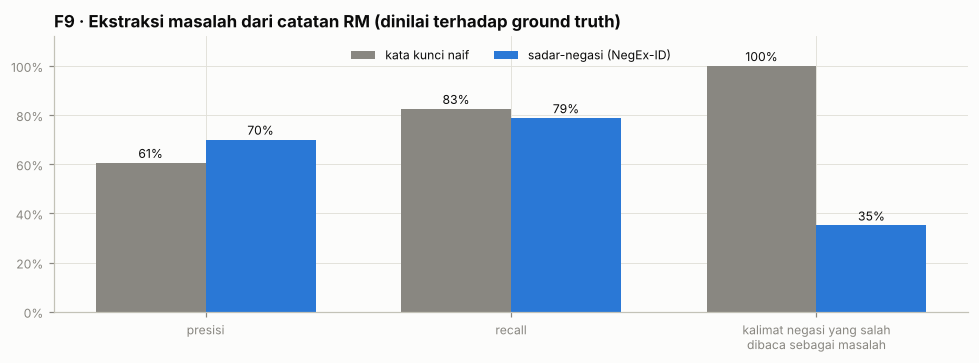

,presisi,recall,negasi_salah_dibaca
naif,0.606,0.826,1.000
negex,0.701,0.788,0.351


,jumlah
Gaji karyawan sudah lewat rekening BNI.,32
Pelanggan utama masih rutin order.,27
Kebutuhan dana operasional saat ini masih tercukupi.,11
Pemilik menanyakan layanan investasi untuk keperluan pribadi.,2


In [30]:
NEG = r'\b(tidak|tak|belum|bukan|tanpa)\b'
def extract(text, mode):
    found = set()
    for sent in re.split(r'(?<=[.!?])\s+', text.lower()):
        for r in imap.itertuples():
            if re.search('(' + r.keywords + ')', sent):
                if mode == 'negex' and re.search(NEG, sent): continue
                found.add(r.issue_id)
    return found
gv = rd('gt_visit_issues'); truth = {(r.visit_id, r.issue_id) for r in gv[gv.present == 1].itertuples()}
negated = {(r.visit_id, r.issue_id) for r in gv[gv.present == 0].itertuples()}
res, leftovers = {}, []
for mode in ['naif', 'negex']:
    pred = {(v, i) for v, t_ in zip(notes.visit_id, notes.note_text) for i in extract(t_, 'naive' if mode == 'naif' else 'negex')}
    tp = len(pred & truth); res[mode] = dict(presisi=tp / len(pred), recall=tp / len(truth), negasi_salah_dibaca=len(pred & negated) / len(negated))
    if mode == 'negex': leftovers = sorted(pred & negated)
f9 = pd.DataFrame(res).T
fig, ax = plt.subplots(figsize=(9, 3.4))
xx = np.arange(3); wdt = .36
for k, (m_, col) in enumerate([('naif', C['muted']), ('negex', C['s1'])]):
    ax.bar(xx + (k - .5) * wdt, f9.loc[m_].values, width=wdt, color=col, label={'naif': 'kata kunci naif', 'negex': 'sadar-negasi (NegEx-ID)'}[m_])
    for j, v in enumerate(f9.loc[m_].values): ax.text(xx[j] + (k - .5) * wdt, v + .02, f'{v:.0%}', ha='center', fontsize=8)
ax.set_xticks(xx); ax.set_xticklabels(['presisi', 'recall', 'kalimat negasi yang salah\ndibaca sebagai masalah']); ax.set_ylim(0, 1.12)
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); ax.set_title('F9 · Ekstraksi masalah dari catatan RM (dinilai terhadap ground truth)'); ax.legend(loc='upper center', ncol=2)
plt.tight_layout(); save_fig(fig, 'F9_visit_notes_negation'); plt.show()
display(f9.round(3))
kw = imap.set_index('issue_id').keywords; note_of = notes.set_index('visit_id').note_text
trig = pd.Series([sent for v, i in leftovers for sent in re.split(r'(?<=[.!?])\s+', note_of[v])
                  if re.search('(' + kw[i] + ')', sent.lower()) and not re.search(NEG, sent.lower())]).value_counts()
print(f'{len(leftovers)} negasi masih lolos. Kalimat pemicunya (tanpa kata "tidak/belum/bukan"), dua jenis:')
print('  (a) negasi IMPLISIT, mis. "masih tercukupi", "sudah lewat BNI", "masih rutin order";')
print('  (b) TABRAKAN kata kunci, mis. "investasi" untuk kebutuhan pribadi pemilik, bukan ekspansi usaha.')
display(trig.rename('jumlah').to_frame().head(8))
b_ = len(negated & {(v, i) for v, t_ in zip(notes.visit_id, notes.note_text) for i in extract(t_, 'naive')}); c_ = len(leftovers)
p_neg = stats.binomtest(c_, b_, .5).pvalue if b_ else np.nan
record('F9-negation', 'Penanda negasi mengurangi salah-baca negasi', 'uji binomial (proporsi negasi tersisa)', f'{b_} → {c_}', p_neg, 'catatan RM', 'issue flags + LLM untuk negasi implisit', gt=True)

**Arti bisnis & jembatan ke GenAI.** Kata kunci naif membaca **setiap** kalimat negasi sebagai masalah ("kebutuhan dana operasional masih tercukupi" terbaca sebagai *butuh modal kerja*). Akibatnya RM bisa menawarkan produk yang jelas tidak dibutuhkan. Aturan NegEx sederhana memotong sebagian besar kesalahan itu. Sisanya adalah **negasi implisit** ("masih tercukupi", "masih rutin order") dan **tabrakan makna kata kunci** ("investasi" pribadi ≠ ekspansi usaha), dan keduanya butuh pemahaman konteks. Inilah **alasan berbasis data** untuk memakai LLM di komponen RM Copilot, dengan aturan NegEx sebagai baseline dan *guardrail* pembanding.

**Fitur untuk notebook 03:** `issue_<id>` (biner, versi NegEx) per perusahaan untuk 6 bulan terakhir. Versi LLM dibuat di modul GenAI dan dievaluasi terhadap set ini.

### F10 · EDA anomali: apa yang sebenarnya perlu dideteksi, dan sinyal mana yang menangkapnya
Modul **"Why Now"** harus memberi tahu RM *kapan* sesuatu berubah pada nasabah. Menurut taksonomi Chandola dkk. (2009), "anomali" di sini bukan satu jenis:
- **anomali titik**: lonjakan satu bulan (termin proyek, penjualan aset). Ini netral, RM cukup tahu;
- **anomali kolektif / perubahan level**: kenaikan yang bertahan (ekspansi) atau penurunan yang bertahan (distress, erosi wallet, efek berantai);
- **anomali kontekstual**: nilai yang wajar di bulan lain tapi aneh di bulan ini, misalnya inflow tinggi di bulan Lebaran itu normal.

Karena itu bagian ini menjawab lima pertanyaan:
1. Bagaimana bentuk "normal", dan seberapa sering penyimpangan terjadi (*base rate*)?
2. Bisakah **lonjakan sesaat** dibedakan dari **perubahan level**?
3. Bisakah **pembeli utama yang berhenti** dideteksi langsung dari transaksi?
4. 🔎 Sinyal mana yang menangkap jenis kejadian mana, dan apakah ada jenis yang **trivial** (cukup aturan satu baris; Wu & Keogh, 2021)?
5. 🔎 Apakah sinyal timing pembayaran **mendahului** penurunan inflow?

**Cakupan.** Panel bulanan **nasabah** (1.400 perusahaan non-prospect × 30 bulan). Prospect tidak dimasukkan karena transaksinya hanya terlihat sebagian (G2). Pertanyaan 1–3 tidak memakai ground truth. Pertanyaan 4–5 memakai `gt_anomaly_events` **hanya untuk evaluasi**.

**Catatan metodologi.** Beberapa skor di bawah bersifat **retrospektif** (melihat data sebelum *dan* sesudah suatu bulan), dan itu sah untuk memahami data. Di notebook 03, semua fitur anomali wajib versi **online**: hanya memakai data sampai bulan berjalan, supaya tidak ada *look-ahead*.

Panel: 1,400 nasabah × 30 bulan. |z| > 3,5 di 0.92% perusahaan-bulan; 19% nasabah punya ≥ 1 bulan seperti itu.
Base rate naik dari rata-rata 0.7% (2024) ke 2.2% (H1-2026): kejadian yang bertahan (erosi, distress, efek berantai) menumpuk menjelang cutoff. Ambang alarm di FE sebaiknya per bulan (top-k), bukan ambang z tetap.
Bulan musim = 9 dari 30 bulan (30%). Tanpa koreksi, 49% alarm jatuh di bulan musim; setelah koreksi 33% (≈ proporsional).
Alarm "naik" di bulan musim turun 143 → 64, sedangkan alarm "turun" di bulan biasa naik 65 → 99: alarm berpindah dari puncak musim yang bisa ditebak ke penyimpangan yang sebenarnya.


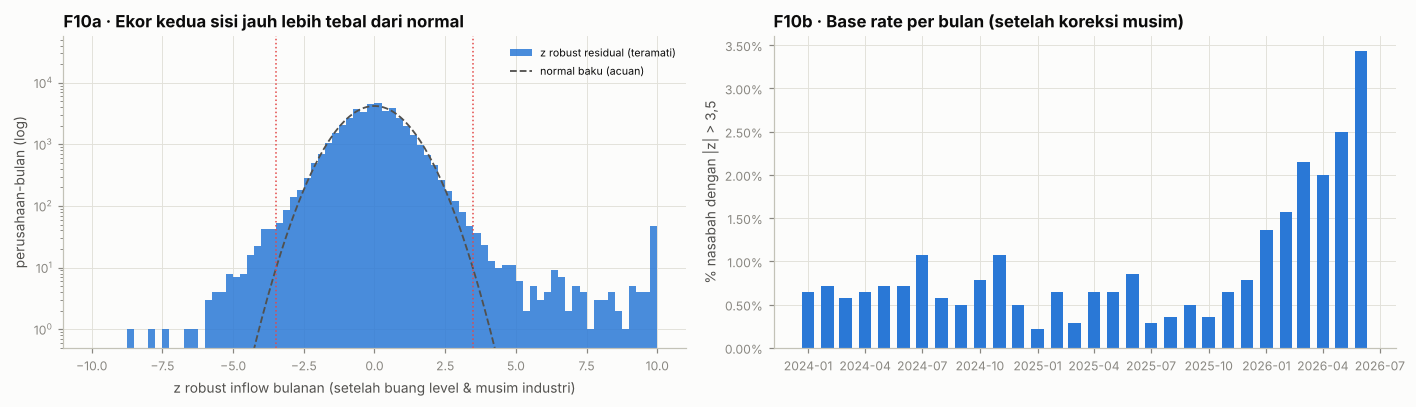

,total,porsi_di_bulan_musim,naik_di_bulan_musim,turun_di_bulan_biasa
tanpa koreksi musiman,0.0080,0.4911,143.0,65.0
dengan koreksi musiman industri,0.0092,0.3299,64.0,99.0


In [31]:
months = inn.columns
Lp = np.log1p(inn.reindex(cli_ids).fillna(0))                               # log inflow nasabah × bulan
Ld = Lp.sub(Lp.median(axis=1), axis=0)                                      # buang level perusahaan
ind_of = co.set_index('company_id').industry.reindex(Ld.index)
seas_im = Ld.groupby(ind_of).transform('median')                            # pola musiman industri × bulan (kontekstual)
Rres = Ld - seas_im                                                         # residual: sudah bebas level & musim
mad_r = 1.4826 * Rres.sub(Rres.median(axis=1), axis=0).abs().median(axis=1)
Zp = Rres.sub(Rres.median(axis=1), axis=0).div(mad_r.replace(0, np.nan), axis=0)
zf = Zp.values.ravel(); zf = zf[np.isfinite(zf)]
br_pt = np.mean(np.abs(zf) > 3.5); br_co = (Zp.abs() > 3.5).any(axis=1).mean()
Zraw = Ld.sub(Ld.median(axis=1), axis=0).div(1.4826 * Ld.sub(Ld.median(axis=1), axis=0).abs().median(axis=1), axis=0)
seas_cols = [m_ for m_ in months if m_.month in (3, 4, 12) or str(m_) == '2026-02']     # bulan Lebaran (bergeser) & Desember
def alarm_mix(Z_):
    f_ = Z_.abs() > 3.5
    return dict(total=f_.values.mean(), porsi_di_bulan_musim=f_[seas_cols].values.sum() / f_.values.sum(),
                naik_di_bulan_musim=int((Z_[seas_cols] > 3.5).values.sum()), turun_di_bulan_biasa=int((Z_.drop(columns=seas_cols) < -3.5).values.sum()))
mix = pd.DataFrame({'tanpa koreksi musiman': alarm_mix(Zraw), 'dengan koreksi musiman industri': alarm_mix(Zp)}).T
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
bins_ = np.linspace(-10, 10, 81)
ax[0].hist(np.clip(zf, -10, 10), bins=bins_, color=C['s1'], alpha=.85, label='z robust residual (teramati)')
xx_ = np.linspace(-10, 10, 400); ax[0].plot(xx_, stats.norm.pdf(xx_) * len(zf) * (bins_[1] - bins_[0]), color=C['ink2'], lw=1.2, ls='--', label='normal baku (acuan)')
ax[0].set_yscale('log'); ax[0].set_ylim(.5, None); ax[0].axvline(-3.5, color=C['s8'], ls=':', lw=1); ax[0].axvline(3.5, color=C['s8'], ls=':', lw=1)
ax[0].set(xlabel='z robust inflow bulanan (setelah buang level & musim industri)', ylabel='perusahaan-bulan (log)', title='F10a · Ekor kedua sisi jauh lebih tebal dari normal'); ax[0].legend(fontsize=7)
share_m = (Zp.abs() > 3.5).mean()
ax[1].bar(share_m.index.to_timestamp(), share_m.values, width=20, color=C['s1'])
ax[1].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax[1].set(ylabel='% nasabah dengan |z| > 3,5', title='F10b · Base rate per bulan (setelah koreksi musim)')
plt.tight_layout(); save_fig(fig, 'F10a_anomaly_base_rate'); plt.show()
print(f'Panel: {Zp.shape[0]:,} nasabah × {Zp.shape[1]} bulan. |z| > 3,5 di {br_pt:.2%} perusahaan-bulan; {br_co:.0%} nasabah punya ≥ 1 bulan seperti itu.')
print(f'Base rate naik dari rata-rata {share_m.iloc[:12].mean():.1%} (2024) ke {share_m.iloc[-6:].mean():.1%} (H1-2026): kejadian yang bertahan '
      '(erosi, distress, efek berantai) menumpuk menjelang cutoff. Ambang alarm di FE sebaiknya per bulan (top-k), bukan ambang z tetap.')
display(mix.round(4))
print(f'Bulan musim = {len(seas_cols)} dari {len(months)} bulan ({len(seas_cols) / len(months):.0%}). Tanpa koreksi, {mix.iloc[0].porsi_di_bulan_musim:.0%} alarm jatuh di bulan musim; '
      f'setelah koreksi {mix.iloc[1].porsi_di_bulan_musim:.0%} (≈ proporsional).')
print(f'Alarm "naik" di bulan musim turun {int(mix.iloc[0].naik_di_bulan_musim)} → {int(mix.iloc[1].naik_di_bulan_musim)}, sedangkan alarm "turun" di bulan biasa naik '
      f'{int(mix.iloc[0].turun_di_bulan_biasa)} → {int(mix.iloc[1].turun_di_bulan_biasa)}: alarm berpindah dari puncak musim yang bisa ditebak ke penyimpangan yang sebenarnya.')

**F10 · 2 — Lonjakan sesaat vs perubahan level.** Satu bulan dengan z tinggi bisa berarti dua hal yang maknanya sangat berbeda bagi RM: termin proyek sekali jalan, atau awal ekspansi yang bertahan. Dua skor retrospektif dihitung untuk setiap nasabah:
- **skor spike**: seberapa jauh satu bulan melampaui **kedua** tetangganya (bulan sebelum dan sesudah);
- **skor level shift**: selisih median residual sesudah vs sebelum titik patah terbaik (segmen minimal 4 bulan), dibagi MAD. Ini versi sederhana deteksi *change point* (CUSUM, Page, 1954; pencarian titik patah optimal, Killick dkk., 2012).

Untuk membuktikan bahwa perubahan level itu nyata dan bukan sekadar derau, urutan bulan setiap nasabah diacak (struktur waktunya dirusak), lalu skor shift dihitung ulang sebagai pembanding (*null*).

|skor shift| > 3: teramati 3.0% nasabah vs null (urutan bulan diacak) 0.1% → Fisher p = 4.2e-11.
Dari bulan dengan z > 3,5, hanya 5% yang tetap tinggi 2 bulan berikutnya. Alarm "z bulanan" saja mencampur spike dan ekspansi.


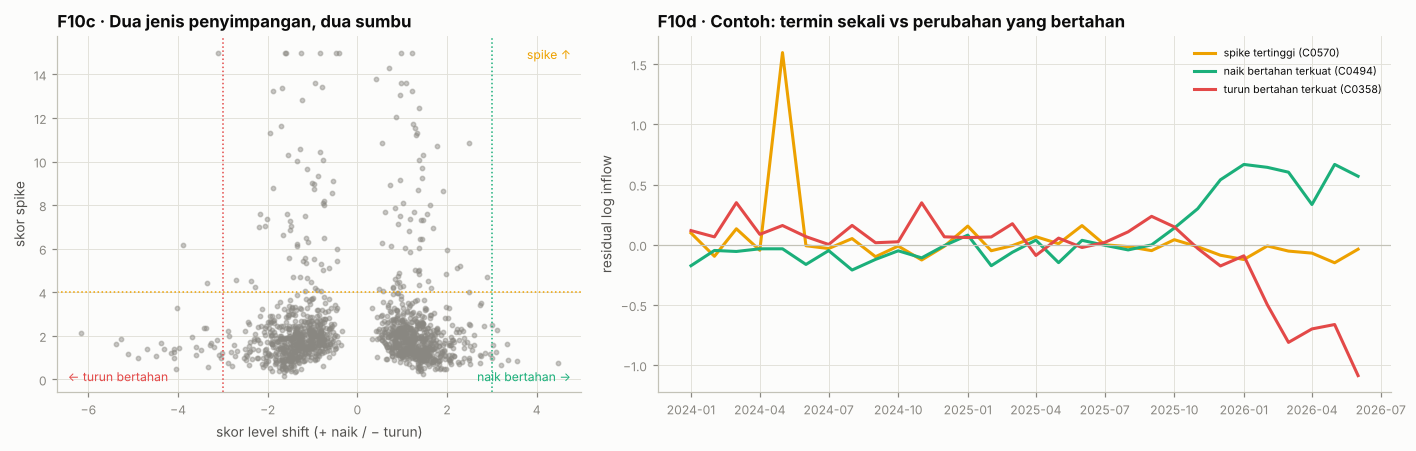

In [32]:
def spike_score(z):
    return np.nanmax(np.minimum(z[1:-1] - z[:-2], z[1:-1] - z[2:]))
def shift_score(r, m, minseg=4):
    best, bk = 0.0, 0
    for b in range(minseg, len(r) - minseg + 1):
        s_ = (np.median(r[b:]) - np.median(r[:b])) / m if m > 0 else 0.0
        if abs(s_) > abs(best): best, bk = s_, b
    return best, bk
Rv, Zv, mv = Rres.values, Zp.fillna(0).values, mad_r.values
sh = np.array([shift_score(Rv[i], mv[i]) for i in range(len(Rv))])
AN = pd.DataFrame({'spike_score': [spike_score(Zv[i]) for i in range(len(Zv))], 'shift_score': sh[:, 0], 'shift_break': sh[:, 1].astype(int)}, index=Rres.index)
AN['shift_month'] = [str(months[b]) if b > 0 else None for b in AN.shift_break]
rp = np.random.default_rng(SEED)
null_sh = np.array([shift_score(rp.permutation(Rv[i]), mv[i])[0] for i in range(len(Rv))])
obs_big, null_big = np.mean(np.abs(AN.shift_score) > 3), np.mean(np.abs(null_sh) > 3)
_, p_shift = stats.fisher_exact([[int((np.abs(AN.shift_score) > 3).sum()), int((np.abs(AN.shift_score) <= 3).sum())],
                                 [int((np.abs(null_sh) > 3).sum()), int((np.abs(null_sh) <= 3).sum())]], alternative='greater')
hi_m = (Zp > 3.5).values; persist = []
for i, j in zip(*np.where(hi_m[:, :-2])): persist.append((Zv[i, j + 1] > 2) and (Zv[i, j + 2] > 2))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[1, 1.4]))
ax[0].scatter(AN.shift_score.clip(-12, 12), AN.spike_score.clip(0, 15), s=8, color=C['muted'], alpha=.45)
ax[0].axhline(4, color=C['s4'], ls=':', lw=1); ax[0].axvline(3, color=C['s3'], ls=':', lw=1); ax[0].axvline(-3, color=C['s8'], ls=':', lw=1)
ax[0].text(.98, .97, 'spike ↑', color=C['s4'], fontsize=8, ha='right', va='top', transform=ax[0].transAxes)
ax[0].text(.98, .03, 'naik bertahan →', color=C['s3'], fontsize=8, ha='right', transform=ax[0].transAxes); ax[0].text(.02, .03, '← turun bertahan', color=C['s8'], fontsize=8, transform=ax[0].transAxes)
ax[0].set(xlabel='skor level shift (+ naik / − turun)', ylabel='skor spike', title='F10c · Dua jenis penyimpangan, dua sumbu')
ex_ids = {'spike tertinggi': AN.spike_score.idxmax(), 'naik bertahan terkuat': AN.shift_score.idxmax(), 'turun bertahan terkuat': AN.shift_score.idxmin()}
for (lbl, cid_x), col in zip(ex_ids.items(), [C['s4'], C['s3'], C['s8']]):
    ax[1].plot(months.to_timestamp(), Rres.loc[cid_x].values, color=col, label=f'{lbl} ({cid_x})')
ax[1].axhline(0, color=C['axis'], lw=.8); ax[1].set(ylabel='residual log inflow', title='F10d · Contoh: termin sekali vs perubahan yang bertahan'); ax[1].legend(fontsize=7)
plt.tight_layout(); save_fig(fig, 'F10c_spike_vs_shift'); plt.show()
print(f'|skor shift| > 3: teramati {obs_big:.1%} nasabah vs null (urutan bulan diacak) {null_big:.1%} → Fisher p = {p_shift:.1e}.')
print(f'Dari bulan dengan z > 3,5, hanya {np.mean(persist):.0%} yang tetap tinggi 2 bulan berikutnya. Alarm "z bulanan" saja mencampur spike dan ekspansi.')
record('F10-shift', 'Perubahan level yang bertahan lebih sering dari derau (null: urutan bulan diacak)', 'Fisher exact, |shift| > 3', f'{obs_big:.1%} vs {null_big:.1%}', p_shift, 'nasabah (tanpa label)', 'shift_score online (CUSUM)')

**F10 · 3 — Pembeli utama berhenti.** Dari transaksi masuk, dicari counterparty (perusahaan inti atau mitra jaringan) yang memenuhi dua syarat:
- menyumbang porsi berarti dari inflow selama 12 bulan terakhir keaktifannya;
- lalu **tidak pernah bertransaksi lagi** minimal 2 bulan sampai cutoff.

Skor detektornya adalah porsi inflow yang hilang. Kalau detektor ini menangkap kejadian nyata, makin besar porsi yang hilang, makin besar penurunan inflow total sesudahnya (dosis–respons).

114 nasabah kehilangan counterparty dengan porsi ≥ 15%. Spearman porsi hilang vs Δinflow = -0.31 (p = 3.4e-05, n = 175).
Silang dengan kolom relationships.relationship_end (relasi jual yang tercatat berakhir): 64 nasabah, 61 di antaranya juga ditemukan detektor transaksi (95%).


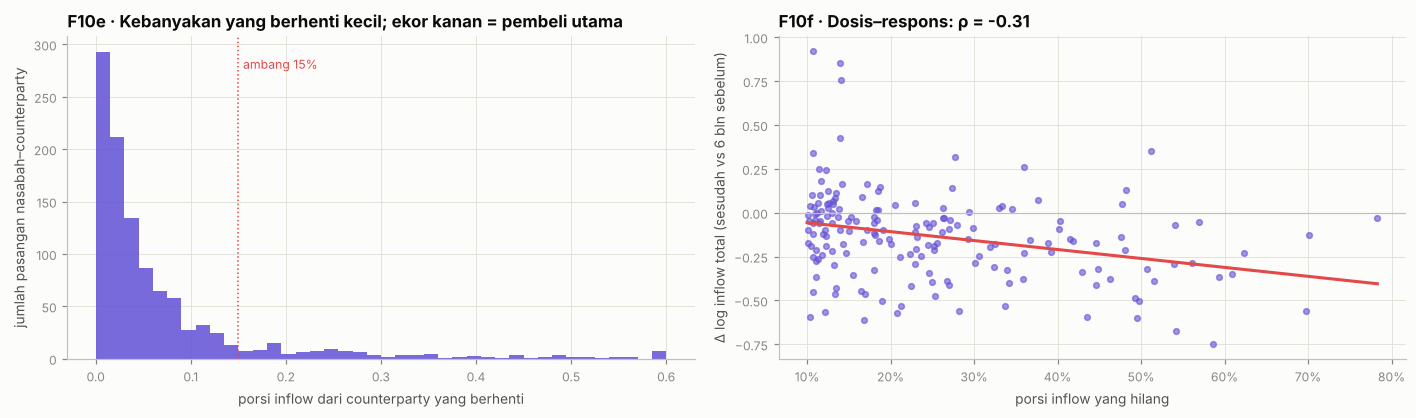

In [33]:
ibk = ib_all[ib_all.company_id.isin(cli_ids) & ib_all.counterparty_id.notna() & ib_all.counterparty_id.astype(str).str.match(r'^[CE]\d')]
cpm = ibk.groupby(['company_id', 'counterparty_id', 'ym']).amount_idr_mn.sum().unstack(fill_value=0).reindex(columns=months, fill_value=0)
totm = inn.reindex(cli_ids).fillna(0)
arr_, comp_, cpid_ = cpm.values, cpm.index.get_level_values(0), cpm.index.get_level_values(1)
tot_arr = totm.reindex(comp_).values; rows = []
for j in range(len(arr_)):
    nz = np.flatnonzero(arr_[j])
    if len(nz) == 0 or nz.max() >= len(months) - 2: continue                 # masih aktif di 2 bulan terakhir
    last = nz.max(); w0 = max(0, last - 11)
    rows.append((comp_[j], cpid_[j], arr_[j, w0:last + 1].sum() / max(tot_arr[j, w0:last + 1].sum(), 1e-9), str(months[last])))
exits = pd.DataFrame(rows, columns=['company_id', 'counterparty_id', 'porsi_hilang', 'bulan_terakhir'])
bx = exits.sort_values('porsi_hilang').groupby('company_id').tail(1).set_index('company_id')
AN['buyer_exit_share'] = bx.porsi_hilang.reindex(AN.index).fillna(0)
dose = []
for c_, r_ in bx[bx.porsi_hilang >= .10].iterrows():
    b_ = months.get_loc(pd.Period(r_.bulan_terakhir, 'M')) + 1; v_ = totm.loc[c_].values
    if b_ < len(months): dose.append((r_.porsi_hilang, np.log((v_[b_:].mean() + 1) / (v_[max(0, b_ - 6):b_].mean() + 1))))
dose = np.array(dose); rho_bx, p_bx = stats.spearmanr(dose[:, 0], dose[:, 1])
ended = set(rel.loc[rel.relationship_end.notna() & rel.relationship_type.isin(['Customer', 'Distributor']), 'source_id']) & set(cli_ids)
flag_bx = set(AN.index[AN.buyer_exit_share >= .15])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
ax[0].hist(exits.porsi_hilang.clip(0, .6), bins=40, color=C['s7'], alpha=.85); ax[0].axvline(.15, color=C['s8'], ls=':', lw=1)
ax[0].text(.155, ax[0].get_ylim()[1] * .9, 'ambang 15%', fontsize=8, color=C['s8'])
ax[0].set(xlabel='porsi inflow dari counterparty yang berhenti', ylabel='jumlah pasangan nasabah–counterparty', title='F10e · Kebanyakan yang berhenti kecil; ekor kanan = pembeli utama')
ax[1].scatter(dose[:, 0], dose[:, 1], s=14, color=C['s7'], alpha=.6); b_fit = np.polyfit(dose[:, 0], dose[:, 1], 1)
gx_ = np.linspace(.1, dose[:, 0].max(), 50); ax[1].plot(gx_, np.polyval(b_fit, gx_), color=C['s8'])
ax[1].axhline(0, color=C['axis'], lw=.8); ax[1].xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax[1].set(xlabel='porsi inflow yang hilang', ylabel='Δ log inflow total (sesudah vs 6 bln sebelum)', title=f'F10f · Dosis–respons: ρ = {rho_bx:+.2f}')
plt.tight_layout(); save_fig(fig, 'F10e_buyer_exit'); plt.show()
print(f'{len(flag_bx)} nasabah kehilangan counterparty dengan porsi ≥ 15%. Spearman porsi hilang vs Δinflow = {rho_bx:+.2f} (p = {p_bx:.1e}, n = {len(dose)}).')
print(f'Silang dengan kolom relationships.relationship_end (relasi jual yang tercatat berakhir): {len(ended)} nasabah, '
      f'{len(ended & flag_bx)} di antaranya juga ditemukan detektor transaksi ({len(ended & flag_bx) / max(len(ended), 1):.0%}).')
record('F10-buyerexit', 'Makin besar porsi pembeli yang berhenti, makin turun inflow', 'Spearman porsi hilang vs Δinflow', f'ρ={rho_bx:+.2f}', p_bx, 'nasabah (tanpa label)', 'buyer_exit_share (online)')

**🔎 F10 · 4 — Peta sinyal × jenis kejadian (evaluasi saja).** Inilah inti EDA anomali. Setiap sinyal diringkas menjadi satu skor per nasabah (nilai maksimum sepanjang panel), lalu dinilai seberapa baik skor itu memisahkan nasabah yang mengalami suatu jenis kejadian dari yang tidak (AUC).

Tiga sinyal pertama adalah **aturan satu baris** (*one-liner*) versi online, dipakai sebagai pembanding trivialitas ala Wu & Keogh (2021). Kalau aturan satu baris sudah mendapat AUC ≥ 0,90 untuk suatu jenis kejadian, jenis itu tidak membutuhkan model ML yang rumit. Nilai tambah ML ada di jenis-jenis yang tidak bisa ditangkap oleh satu sinyal.

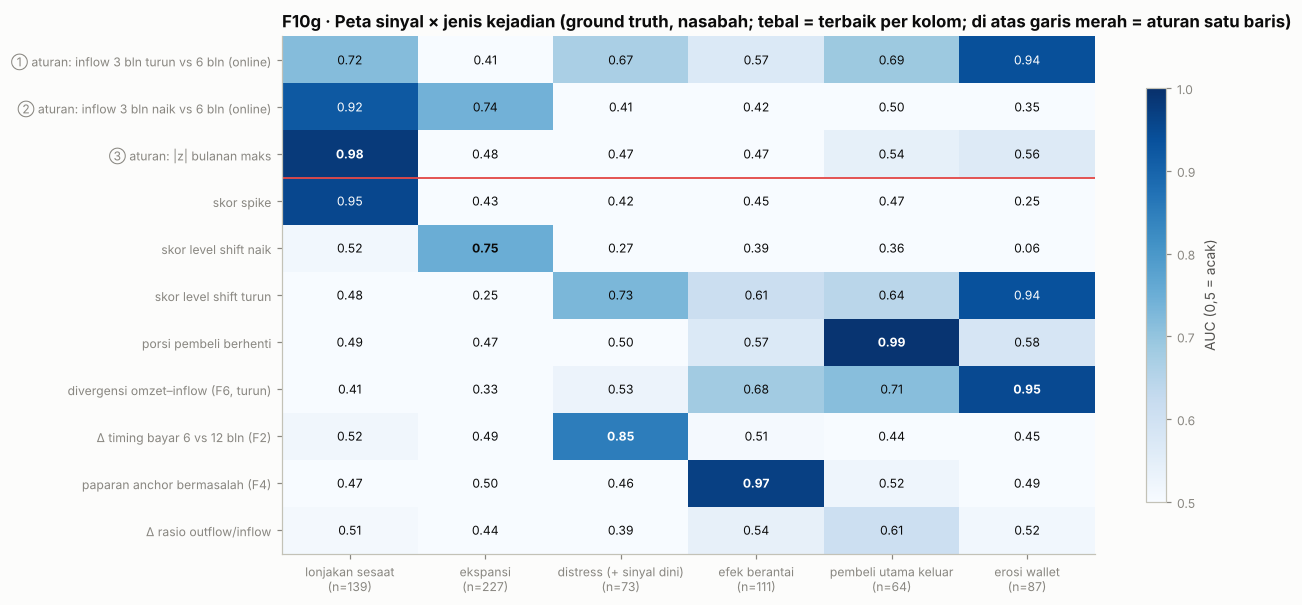

,sinyal_terbaik,AUC_terbaik,AUC_aturan_1_baris_terbaik,kategori
lonjakan sesaat,③ aturan: |z| bulanan maks,0.979,0.979,trivial (aturan cukup)
ekspansi,skor level shift naik,0.751,0.742,butuh kombinasi sinyal (ML)
distress (+ sinyal dini),Δ timing bayar 6 vs 12 bln (F2),0.851,0.669,butuh kombinasi sinyal (ML)
efek berantai,paparan anchor bermasalah (F4),0.968,0.570,butuh sinyal khusus
pembeli utama keluar,porsi pembeli berhenti,0.992,0.688,butuh sinyal khusus
erosi wallet,"divergensi omzet–inflow (F6, turun)",0.951,0.938,trivial (aturan cukup)


In [34]:
lt = pd.concat([pay.assign(l=pay.day >= 28)[['company_id', 'ym', 'l']], tax.assign(l=tax.day > 15)[['company_id', 'ym', 'l']]])
late_m = lt.groupby(['company_id', 'ym']).l.mean().unstack().reindex(index=AN.index, columns=months)
roll3 = Rres.T.rolling(3).mean().T; prev6 = Rres.T.shift(3).rolling(6).mean().T            # online: 3 bln terakhir vs 6 bln sebelumnya
drop_on = (prev6 - roll3)
SIG = pd.DataFrame(index=AN.index)
SIG['① aturan: inflow 3 bln turun vs 6 bln (online)'] = drop_on.max(axis=1)
SIG['② aturan: inflow 3 bln naik vs 6 bln (online)'] = (-drop_on).max(axis=1)
SIG['③ aturan: |z| bulanan maks'] = Zp.abs().max(axis=1)
SIG['skor spike'] = AN.spike_score
SIG['skor level shift naik'] = AN.shift_score
SIG['skor level shift turun'] = -AN.shift_score
SIG['porsi pembeli berhenti'] = AN.buyer_exit_share
SIG['divergensi omzet–inflow (F6, turun)'] = -P.divergence.reindex(AN.index).fillna(0)
SIG['Δ timing bayar 6 vs 12 bln (F2)'] = (late_m.iloc[:, -6:].mean(axis=1) - late_m.iloc[:, -18:-6].mean(axis=1)).fillna(0)
SIG['paparan anchor bermasalah (F4)'] = P.exp_shocked_anchor.reindex(AN.index).fillna(0)
SIG['Δ rasio outflow/inflow'] = (out_m.reindex(AN.index).iloc[:, -6:].sum(axis=1) / inn.reindex(AN.index).iloc[:, -6:].sum(axis=1)
                                 - out_m.reindex(AN.index).iloc[:, -18:-6].sum(axis=1) / inn.reindex(AN.index).iloc[:, -18:-6].sum(axis=1)).fillna(0)
ETYPES = ['spike', 'expansion', 'distress', 'contagion', 'buyer_exit', 'wallet_erosion']
EV_LBL = {'spike': 'lonjakan sesaat', 'expansion': 'ekspansi', 'distress': 'distress (+ sinyal dini)', 'contagion': 'efek berantai', 'buyer_exit': 'pembeli utama keluar', 'wallet_erosion': 'erosi wallet'}
gta_c = gta[gta.company_id.isin(AN.index)]
M_auc = pd.DataFrame({EV_LBL[e]: [auc(AN.index.isin(gta_c.loc[gta_c.event_type == e, 'company_id']).astype(int), SIG[s].values) for s in SIG] for e in ETYPES}, index=SIG.columns)
n_ev = {EV_LBL[e]: int(AN.index.isin(gta_c.loc[gta_c.event_type == e, 'company_id']).sum()) for e in ETYPES}
fig, ax = plt.subplots(figsize=(12, 5.6))
im = ax.imshow(M_auc.values, cmap='Blues', vmin=.5, vmax=1, aspect='auto'); ax.grid(False)
ax.set_xticks(range(len(ETYPES))); ax.set_xticklabels([f'{k}\n(n={v})' for k, v in n_ev.items()], fontsize=8)
ax.set_yticks(range(len(SIG.columns))); ax.set_yticklabels(SIG.columns, fontsize=8)
for i in range(M_auc.shape[0]):
    for j in range(M_auc.shape[1]):
        v = M_auc.values[i, j]; best_ = v == M_auc.values[:, j].max()
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8, color='white' if v > .8 else C['ink'], fontweight='bold' if best_ else 'normal')
ax.axhline(2.5, color=C['s8'], lw=1.2)
plt.colorbar(im, ax=ax, shrink=.8, label='AUC (0,5 = acak)'); ax.set_title('F10g · Peta sinyal × jenis kejadian (ground truth, nasabah; tebal = terbaik per kolom; di atas garis merah = aturan satu baris)')
plt.tight_layout(); save_fig(fig, 'F10g_signal_event_matrix'); plt.show()
best_sig = M_auc.idxmax(); best_val = M_auc.max(); best_rule = M_auc.iloc[:3].max()
triv = pd.DataFrame({'sinyal_terbaik': best_sig, 'AUC_terbaik': best_val, 'AUC_aturan_1_baris_terbaik': best_rule,
                     'kategori': np.where(best_rule >= .9, 'trivial (aturan cukup)', np.where(best_val >= .9, 'butuh sinyal khusus', 'butuh kombinasi sinyal (ML)'))})
display(triv.round(3))
M_auc.to_csv(OUT / 'anomaly_signal_event_auc.csv')

**🔎 F10 · 5 — Apakah timing pembayaran mendahului penurunan inflow?** Semua nasabah yang mengalami distress diselaraskan pada bulan mulainya penurunan omzet (bulan 0). Lalu dihitung rata-rata **% gaji/pajak telat** dan **residual inflow** untuk setiap bulan relatif, dari −9 sampai +6. Kalau timing bayar adalah sinyal dini, kurvanya akan naik **sebelum** bulan 0, sementara inflow baru turun **setelah** bulan 0.

Panel kanan menjawab pertanyaan lanjutan: kalau inflow turun, apa penyebabnya? Distress dan erosi wallet sama-sama membuat inflow turun, tetapi seharusnya meninggalkan jejak yang berbeda di timing bayar dan divergensi omzet.

% telat bulan −3…−1 vs −9…−6: 55.3% vs 17.0% (Wilcoxon p = 2.2e-13, n = 73); residual inflow pada periode yang sama +0.061 vs +0.078 (belum turun).


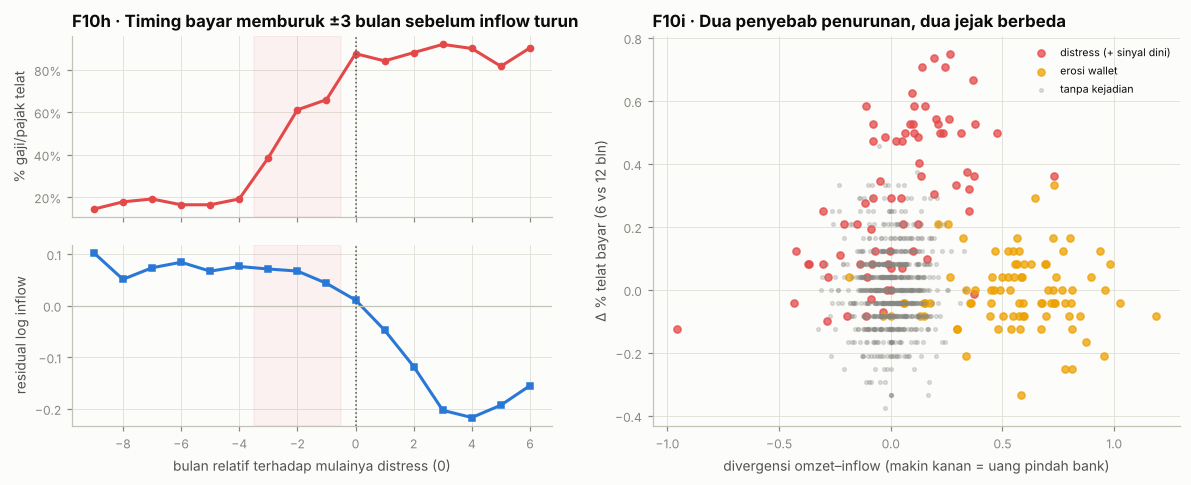

In [35]:
dis = gta_c[gta_c.event_type == 'distress'][['company_id', 'start_month']]
rows = []
for r_ in dis.itertuples():
    if r_.company_id not in late_m.index: continue
    b_ = months.get_loc(pd.Period(r_.start_month, 'M'))
    for k_ in range(-9, 7):
        if 0 <= b_ + k_ < len(months): rows.append((r_.company_id, k_, late_m.loc[r_.company_id].iloc[b_ + k_], Rres.loc[r_.company_id].iloc[b_ + k_]))
es = pd.DataFrame(rows, columns=['c', 'k', 'late', 'resid'])
prof = es.groupby('k')[['late', 'resid']].mean()
pre_ = es[es.k.between(-3, -1)].groupby('c').late.mean(); base_ = es[es.k.between(-9, -6)].groupby('c').late.mean()
dd_ = (pre_ - base_).dropna(); _, p_lead = stats.wilcoxon(dd_) if len(dd_) > 5 else (np.nan, np.nan)
pre_r = es[es.k.between(-3, -1)].groupby('c').resid.mean(); base_r = es[es.k.between(-9, -6)].groupby('c').resid.mean()
fig = plt.figure(figsize=(13, 4.6)); gs_ = fig.add_gridspec(2, 2, width_ratios=[1, 1.1], hspace=.15)
a_top, a_bot, a_r = fig.add_subplot(gs_[0, 0]), fig.add_subplot(gs_[1, 0]), fig.add_subplot(gs_[:, 1])
a_top.plot(prof.index, prof.late, color=C['s8'], marker='o', ms=4); a_top.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
a_top.set(ylabel='% gaji/pajak telat', title='F10h · Timing bayar memburuk ±3 bulan sebelum inflow turun'); a_top.tick_params(labelbottom=False)
a_bot.plot(prof.index, prof.resid, color=C['s1'], marker='s', ms=4); a_bot.axhline(0, color=C['axis'], lw=.8)
a_bot.set(xlabel='bulan relatif terhadap mulainya distress (0)', ylabel='residual log inflow')
for a_ in (a_top, a_bot): a_.axvline(0, color=C['ink2'], ls=':', lw=1); a_.axvspan(-3.5, -.5, color=C['s8'], alpha=.06)
ax = [None, a_r]
grp_ = {'distress': C['s8'], 'wallet_erosion': C['s4']}
for e_, col in grp_.items():
    ids_ = list(set(gta_c.loc[gta_c.event_type == e_, 'company_id']) - set(gta_c.loc[gta_c.event_type == ({'distress': 'wallet_erosion', 'wallet_erosion': 'distress'}[e_]), 'company_id']))
    ax[1].scatter(SIG.loc[ids_, 'divergensi omzet–inflow (F6, turun)'], SIG.loc[ids_, 'Δ timing bayar 6 vs 12 bln (F2)'], s=22, color=col, alpha=.75, label=EV_LBL[e_])
oth = AN.index.difference(gta_c.company_id)
ax[1].scatter(SIG.loc[oth, 'divergensi omzet–inflow (F6, turun)'], SIG.loc[oth, 'Δ timing bayar 6 vs 12 bln (F2)'], s=6, color=C['muted'], alpha=.25, label='tanpa kejadian')
ax[1].set(xlabel='divergensi omzet–inflow (makin kanan = uang pindah bank)', ylabel='Δ % telat bayar (6 vs 12 bln)', title='F10i · Dua penyebab penurunan, dua jejak berbeda'); ax[1].legend(fontsize=7)
plt.tight_layout(); save_fig(fig, 'F10h_lead_time'); plt.show()
print(f'% telat bulan −3…−1 vs −9…−6: {pre_.mean():.1%} vs {base_.mean():.1%} (Wilcoxon p = {p_lead:.1e}, n = {len(dd_)}); '
      f'residual inflow pada periode yang sama {pre_r.mean():+.3f} vs {base_r.mean():+.3f} (belum turun).')
record('F10-leadtime', 'Timing bayar memburuk sebelum inflow turun (distress)', 'Wilcoxon berpasangan (−3…−1 vs −9…−6)', f'{pre_.mean():.0%} vs {base_.mean():.0%}', p_lead, 'nasabah distress', 'timing_delta sebagai early warning', gt=True)

**Kesimpulan F10 untuk modul anomali.**
1. **Koreksi kontekstual wajib.** Dengan membuang level perusahaan dan pola musiman industri, alarm "naik" di bulan Lebaran/Desember berkurang lebih dari separuh, dan kepekaan terhadap penurunan di bulan biasa justru meningkat. Jumlah alarm total tidak turun; yang berubah adalah **ketepatan sasarannya**.
2. **Spike dan perubahan level harus dipisah.** Hanya ±5% bulan ber-z tinggi yang tetap tinggi dua bulan kemudian. Deteksi harus mengeluarkan **jenis** kejadian, bukan sekadar "anomali / bukan". Perubahan level yang bertahan jauh lebih sering daripada derau acak (F10c).
3. **Dua jenis sudah trivial** (Wu & Keogh, 2021): lonjakan sesaat (|z| maks) dan erosi wallet (aturan "inflow 3 bulan turun vs 6 bulan") sudah tertangkap aturan satu baris dengan AUC ≥ 0,90. Untuk keduanya, aturan transparan lebih tepat daripada model ML. Erosi tetap perlu divergensi omzet supaya **penyebabnya** tidak tertukar dengan distress (F10i).
4. **Dua jenis butuh sinyal khusus, bukan model rumit.** Pembeli utama keluar tertangkap oleh porsi pembeli berhenti, dan efek berantai oleh paparan anchor bermasalah (AUC ≥ 0,96). Kolom `relationship_end` bahkan menandai buyer exit secara langsung. Di dunia nyata informasi ini biasanya datang terlambat dari RM, jadi kolom itu **tidak dipakai sebagai fitur anomali** dan hanya dipakai untuk cross-check. Detektor dari transaksi menemukan 95% kasus yang sama tanpa menunggu pencatatan.
5. **ML dibutuhkan untuk distress dan ekspansi.** Sinyal terbaiknya hanya ±0,75–0,85 dan aturan satu baris jauh di bawahnya. Inilah tempat model yang **menggabungkan** sinyal memberi nilai tambah.
6. **Timing bayar adalah sinyal dini ±3 bulan.** % gaji/pajak telat naik sebelum inflow turun (F10h), jadi RM bisa bertindak lebih awal.

**Fitur anomali untuk notebook 03** (panel nasabah × bulan, semuanya **online** / tanpa look-ahead):
- `inflow_resid_z` (setelah buang level & musim industri);
- `spike_flag` (z bulan ini tinggi tapi rata-rata 3 bulan tidak);
- `cusum_up` / `cusum_down` (akumulasi penyimpangan sejak bulan referensi);
- `drop_3v6`;
- `buyer_exit_share` (counterparty berporsi ≥ 15% yang berhenti ≥ 2 bulan);
- `n_active_counterparties` dan perubahannya;
- `late_share_3m` dan `timing_delta`;
- `out_in_ratio_delta`;
- `divergence` (tahunan);
- `exp_shocked_anchor`.

**Protokol evaluasi untuk notebook 06:** evaluasi per jenis kejadian, lead time (berapa bulan lebih awal dari kejadian), dan presisi pada top-k alarm per bulan, karena kapasitas RM terbatas.

## G. Audit lanjutan
### G1 · Penyaringan fitur: AUC, Spearman, dan ξ Chatterjee + koreksi FDR, lalu cek redundansi
Semua kandidat fitur dari tabel prototipe dinilai pada data dev dengan tiga ukuran yang saling melengkapi:
- **AUC** High vs lainnya (dengan rentang bootstrap): seberapa baik memisahkan kelas yang paling penting;
- **Spearman** terhadap kelas ordinal Low < Medium < High: hubungan monoton;
- **ξ Chatterjee (2021)**: koefisien korelasi baru yang bernilai 0 hanya jika independen, dan bisa menangkap hubungan **tidak monoton** yang terlewat oleh Spearman.

Nilai p dikoreksi dengan Benjamini–Hochberg. Setelah itu dicek **redundansi**: fitur-fitur yang kuat mungkin sebenarnya mengukur hal yang sama, yaitu kesehatan keuangan.

21 dari 27 fitur signifikan setelah BH. Komponen utama pertama dari 14 fitur teratas menjelaskan 47% variasi (AUC PC1 = 0.918).
→ Banyak fitur kuat adalah "saksi" dari faktor kesehatan yang sama. Model akan lebih diuntungkan oleh fitur yang mengukur hal LAIN:
  konsentrasi pembeli dan utilisasi (paparan anchor bernilai untuk Why Now, belum untuk label statis). Di notebook 03, kelompok fitur dievaluasi lewat ablation.


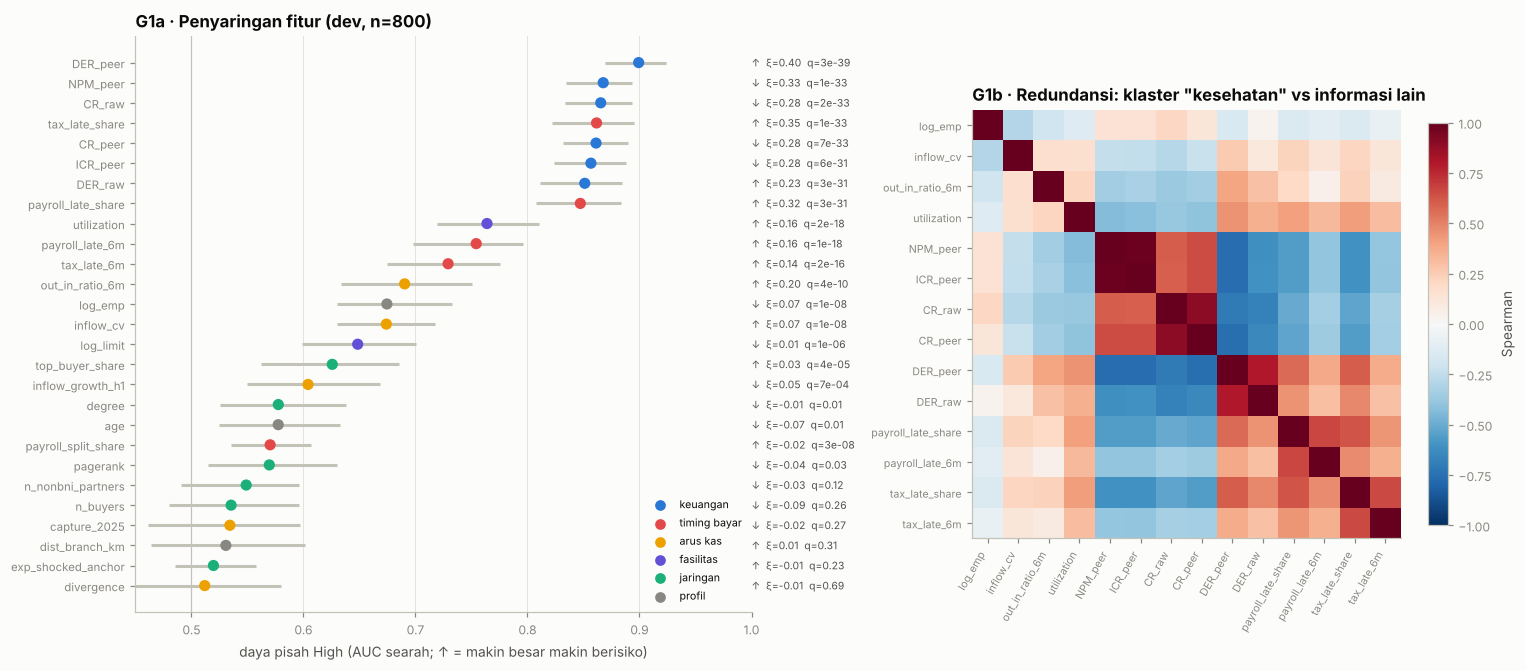

,fitur,kelompok,n,AUC_High,AUC_lo,AUC_hi,spearman,xi,q_BH
0,DER_peer,keuangan,799,0.899,0.869,0.924,0.610,0.399,0.000
1,NPM_peer,keuangan,799,0.132,0.106,0.166,-0.591,0.328,0.000
2,CR_raw,keuangan,799,0.135,0.107,0.166,-0.541,0.276,0.000
3,tax_late_share,timing bayar,800,0.862,0.822,0.895,0.614,0.355,0.000
4,CR_peer,keuangan,799,0.139,0.110,0.168,-0.550,0.285,0.000
5,ICR_peer,keuangan,775,0.143,0.112,0.176,-0.585,0.280,0.000
6,DER_raw,keuangan,799,0.851,0.811,0.885,0.491,0.233,0.000
7,payroll_late_share,timing bayar,800,0.847,0.808,0.884,0.583,0.316,0.000
8,utilization,fasilitas,800,0.764,0.719,0.810,0.413,0.156,0.000
9,payroll_late_6m,timing bayar,800,0.754,0.698,0.796,0.413,0.155,0.000


In [36]:
SCREEN = {'DER_peer': 'keuangan', 'CR_peer': 'keuangan', 'NPM_peer': 'keuangan', 'ICR_peer': 'keuangan', 'DER_raw': 'keuangan', 'CR_raw': 'keuangan',
          'payroll_late_share': 'timing bayar', 'tax_late_share': 'timing bayar', 'payroll_split_share': 'timing bayar', 'payroll_late_6m': 'timing bayar', 'tax_late_6m': 'timing bayar',
          'out_in_ratio_6m': 'arus kas', 'inflow_cv': 'arus kas', 'inflow_growth_h1': 'arus kas', 'divergence': 'arus kas', 'capture_2025': 'arus kas',
          'utilization': 'fasilitas', 'log_limit': 'fasilitas', 'top_buyer_share': 'jaringan', 'n_buyers': 'jaringan', 'exp_shocked_anchor': 'jaringan',
          'degree': 'jaringan', 'pagerank': 'jaringan', 'n_nonbni_partners': 'jaringan', 'log_emp': 'profil', 'age': 'profil', 'dist_branch_km': 'profil'}
D = P.loc[DEV].join(rl.set_index('company_id').risk_class); yH = (D.risk_class == 'High').astype(int).values
yO = D.risk_class.map({'Low': 0, 'Medium': 1, 'High': 2}).values
rows = []
for c, grp_ in SCREEN.items():
    x = D[c].astype(float); m = x.notna().values; xv = x.values
    a = auc(yH, xv); lo, hi = boot_ci(auc, yH[m], xv[m], B=300)
    _, p = stats.mannwhitneyu(xv[m][yH[m] == 1], xv[m][yH[m] == 0])
    rows.append(dict(fitur=c, kelompok=grp_, n=int(m.sum()), AUC_High=a, AUC_lo=lo, AUC_hi=hi, kekuatan=abs(a - .5) + .5,
                     spearman=stats.spearmanr(xv[m], yO[m]).correlation, xi=xi_corr(xv[m], yO[m]), p=p))
scr = pd.DataFrame(rows)
o = np.argsort(scr.p.values); bh_ = scr.p.values[o] * len(scr) / np.arange(1, len(scr) + 1); bh_ = np.minimum.accumulate(bh_[::-1])[::-1]
scr.loc[scr.index[o], 'q_BH'] = np.minimum(bh_, 1)
scr = scr.sort_values('kekuatan', ascending=False).reset_index(drop=True)
scr.to_csv(OUT / 'feature_screening.csv', index=False)
gcol = {'keuangan': C['s1'], 'timing bayar': C['s8'], 'arus kas': C['s4'], 'fasilitas': C['s7'], 'jaringan': C['s3'], 'profil': C['muted']}
fig, ax = plt.subplots(1, 2, figsize=(14, 6.2), gridspec_kw=dict(width_ratios=[1.15, 1]))
yy = np.arange(len(scr))[::-1]
ax[0].hlines(yy, scr.AUC_lo.where(scr.AUC_High >= .5, 1 - scr.AUC_hi), scr.AUC_hi.where(scr.AUC_High >= .5, 1 - scr.AUC_lo), color=C['axis'], lw=2)
ax[0].scatter(scr.kekuatan, yy, color=[gcol[g_] for g_ in scr.kelompok], s=40, zorder=3)
for y_, r in zip(yy, scr.itertuples()):
    ax[0].text(1.0, y_, f"{'↑' if r.AUC_High >= .5 else '↓'}  ξ={r.xi:.2f}  q={r.q_BH:.0e}" if r.q_BH < .001 else f"{'↑' if r.AUC_High >= .5 else '↓'}  ξ={r.xi:.2f}  q={r.q_BH:.2f}",
               va='center', fontsize=6.8, color=C['ink2'], transform=ax[0].get_yaxis_transform())
ax[0].set_yticks(yy); ax[0].set_yticklabels(scr.fitur, fontsize=7.5); ax[0].axvline(.5, color=C['axis'], lw=.8); ax[0].set_xlim(.45, 1)
ax[0].set(xlabel='daya pisah High (AUC searah; ↑ = makin besar makin berisiko)', title='G1a · Penyaringan fitur (dev, n=800)'); ax[0].grid(axis='y', visible=False)
for g_, col in gcol.items(): ax[0].scatter([], [], color=col, label=g_)
ax[0].legend(loc='lower right', fontsize=7)
top = scr[scr.q_BH < .05].fitur.head(14).tolist()
Rm = D[top].rank().corr(method='pearson').values
from scipy.cluster.hierarchy import linkage, leaves_list
ordr = leaves_list(linkage(1 - np.abs(Rm[np.triu_indices(len(top), 1)]), 'average')); Rm = Rm[np.ix_(ordr, ordr)]; tl_ = [top[i] for i in ordr]
im = ax[1].imshow(Rm, cmap='RdBu_r', vmin=-1, vmax=1); ax[1].grid(False)
ax[1].set_xticks(range(len(tl_))); ax[1].set_xticklabels(tl_, rotation=60, ha='right', fontsize=7); ax[1].set_yticks(range(len(tl_))); ax[1].set_yticklabels(tl_, fontsize=7)
plt.colorbar(im, ax=ax[1], shrink=.7, label='Spearman'); ax[1].set_title('G1b · Redundansi: klaster "kesehatan" vs informasi lain')
plt.tight_layout(); save_fig(fig, 'G1_feature_screening'); plt.show()
Z_ = D[top].fillna(D[top].median()); Z_ = (Z_ - Z_.mean()) / Z_.std()
ev, evec = np.linalg.eigh(np.corrcoef(Z_.T.values)); share1 = ev[-1] / ev.sum(); pc1 = Z_.values @ evec[:, -1]
print(f'{(scr.q_BH < .05).sum()} dari {len(scr)} fitur signifikan setelah BH. Komponen utama pertama dari {len(top)} fitur teratas menjelaskan {share1:.0%} variasi '
      f'(AUC PC1 = {max(auc(yH, pc1), 1 - auc(yH, pc1)):.3f}).')
print('→ Banyak fitur kuat adalah "saksi" dari faktor kesehatan yang sama. Model akan lebih diuntungkan oleh fitur yang mengukur hal LAIN:')
print('  konsentrasi pembeli dan utilisasi (paparan anchor bernilai untuk Why Now, belum untuk label statis). Di notebook 03, kelompok fitur dievaluasi lewat ablation.')
display(scr[['fitur', 'kelompok', 'n', 'AUC_High', 'AUC_lo', 'AUC_hi', 'spearman', 'xi', 'q_BH']].round(3))

### G2 · Pergeseran distribusi nasabah → prospect: *classifier two-sample test*
Model risiko dilatih pada **nasabah kredit** (yang punya label), tetapi juga akan dipakai untuk menilai **prospect**. Kalau kedua populasi berbeda, performa di prospect akan lebih buruk dari perkiraan. Teknik *adversarial validation* atau *classifier two-sample test* (C2ST; Lopez-Paz & Oquab, 2017) mengukurnya: sebuah classifier dilatih untuk membedakan nasabah dari prospect.
- AUC ≈ 0,5 berarti kedua populasi tidak bisa dibedakan, jadi fitur aman dipindahkan.
- AUC ≈ 1 berarti populasinya berbeda total.

Nilai p diperoleh dari 30 permutasi, sehingga nilai terkecil yang bisa dicapai adalah 1/31 ≈ 0,032.

Sinyal timing gaji/pajak: TIDAK tersedia untuk prospect (payroll & pajak tidak lewat BNI) → 0% prospect punya nilai.
Bobot importance (Shimodaira, 2000) dari model profil+keuangan: effective sample size nasabah = 541 dari 999 (54%) → hanya sebagian nasabah yang "mirip prospect".


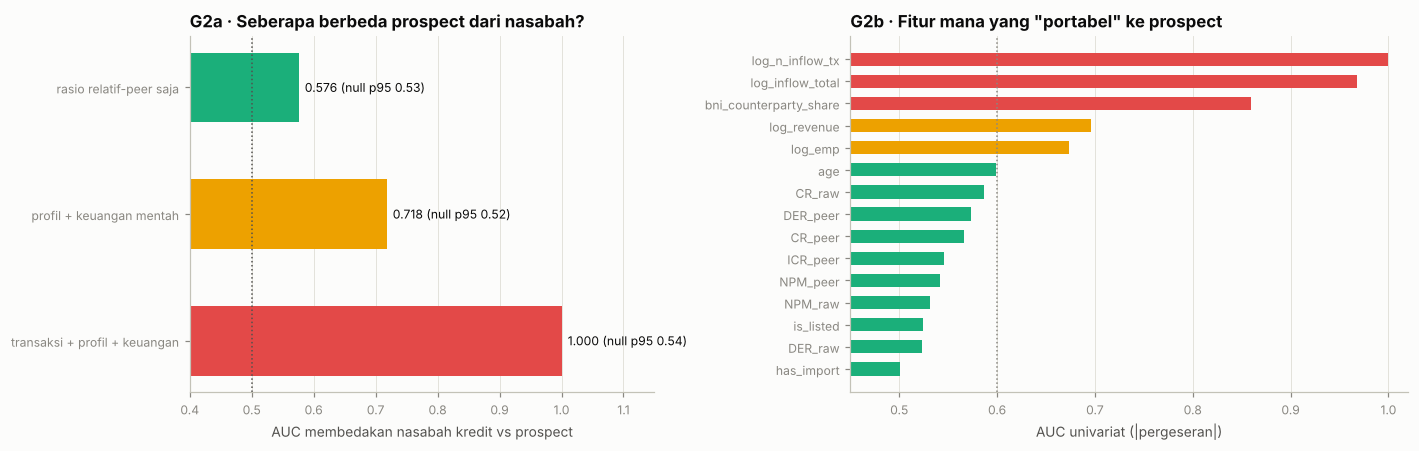

,set_fitur,n_fitur,AUC_C2ST,null_p95,p_perm
0,transaksi + profil + keuangan,11,1.000,0.537,0.032
1,profil + keuangan mentah,8,0.718,0.524,0.032
2,rasio relatif-peer saja,4,0.576,0.529,0.032


In [37]:
pop = co.set_index('company_id').customer_type
ibc = ib_all.groupby('company_id')
P['log_n_inflow_tx'] = np.log1p(ibc.size()); P['log_inflow_total'] = np.log1p(ibc.amount_idr_mn.sum())
P['bni_counterparty_share'] = ib_all.assign(b=ib_all.counterparty_bank == 'BNI').groupby('company_id').b.mean()
P['log_revenue'] = np.log(f25.revenue_idr_bn); P['is_listed'] = co.set_index('company_id').is_listed.astype(int); P['has_import'] = co.set_index('company_id').has_import_activity.astype(int)
SETS = {'transaksi + profil + keuangan': ['log_n_inflow_tx', 'log_inflow_total', 'bni_counterparty_share', 'log_emp', 'age', 'is_listed', 'has_import', 'log_revenue', 'DER_raw', 'CR_raw', 'NPM_raw'],
        'profil + keuangan mentah': ['log_emp', 'age', 'is_listed', 'has_import', 'log_revenue', 'DER_raw', 'CR_raw', 'NPM_raw'],
        'rasio relatif-peer saja': ['DER_peer', 'CR_peer', 'NPM_peer', 'ICR_peer']}
mask = pop.isin(['Existing credit client', 'Prospect']) & P.has_report
A_ = P[mask]; yA = (pop[mask] == 'Prospect').astype(int).values
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
c2st = lambda cols, yv: roc_auc_score(yv, cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), A_[cols].fillna(A_[cols].median()), yv, cv=skf, method='predict_proba')[:, 1])
rows = []
for nm, cols in SETS.items():
    a_obs = c2st(cols, yA); nulls = [c2st(cols, rng_global.permutation(yA)) for _ in range(30)]
    rows.append(dict(set_fitur=nm, n_fitur=len(cols), AUC_C2ST=a_obs, null_p95=np.quantile(nulls, .95), p_perm=(1 + np.sum(np.array(nulls) >= a_obs)) / 31))
g2 = pd.DataFrame(rows)
uni = pd.Series({c: auc(yA, A_[c].values) for c in SETS['transaksi + profil + keuangan'] + SETS['rasio relatif-peer saja']})
uni = (uni - .5).abs().add(.5).sort_values()
pr_ = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(A_[SETS['profil + keuangan mentah']].fillna(A_[SETS['profil + keuangan mentah']].median()), yA)
pp_ = pr_.predict_proba(A_[SETS['profil + keuangan mentah']].fillna(A_[SETS['profil + keuangan mentah']].median()))[yA == 0, 1]
wgt = pp_ / (1 - pp_); ess = wgt.sum() ** 2 / (wgt ** 2).sum()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[1, 1.2]))
ax[0].barh(g2.set_fitur, g2.AUC_C2ST, color=[C['s8'], C['s4'], C['s3']], height=.55)
for i, r in g2.iterrows(): ax[0].text(r.AUC_C2ST + .01, i, f'{r.AUC_C2ST:.3f} (null p95 {r.null_p95:.2f})', va='center', fontsize=8)
ax[0].axvline(.5, color=C['ink2'], ls=':', lw=1); ax[0].set_xlim(.4, 1.15); ax[0].grid(axis='y', visible=False)
ax[0].set(xlabel='AUC membedakan nasabah kredit vs prospect', title='G2a · Seberapa berbeda prospect dari nasabah?')
ax[1].barh(uni.index, uni.values, color=[C['s8'] if v > .75 else (C['s4'] if v > .6 else C['s3']) for v in uni.values], height=.6)
ax[1].axvline(.6, color=C['muted'], ls=':', lw=1); ax[1].set_xlim(.45, 1.02); ax[1].grid(axis='y', visible=False)
ax[1].set(xlabel='AUC univariat (|pergeseran|)', title='G2b · Fitur mana yang "portabel" ke prospect')
plt.tight_layout(); save_fig(fig, 'G2_client_prospect_shift'); plt.show()
display(g2.round(3))
print(f'Sinyal timing gaji/pajak: TIDAK tersedia untuk prospect (payroll & pajak tidak lewat BNI) → {P.loc[pop[pop == "Prospect"].index, "payroll_late_share"].notna().mean():.0%} prospect punya nilai.')
print(f'Bobot importance (Shimodaira, 2000) dari model profil+keuangan: effective sample size nasabah = {ess:.0f} dari {(yA == 0).sum()} '
      f'({ess / (yA == 0).sum():.0%}) → hanya sebagian nasabah yang "mirip prospect".')
for r in g2.itertuples(): record(f'G2-{r.set_fitur[:12]}', f'Prospect berbeda dari nasabah pada set "{r.set_fitur}"', 'C2ST (LR, CV 5) + permutasi', f'AUC={r.AUC_C2ST:.3f}', r.p_perm, 'nasabah kredit + prospect', 'pisahkan set fitur portabel')

**Arti untuk modelling.** Fitur volume transaksi membuat prospect **terpisah sempurna** dari nasabah (AUC ≈ 1). Penyebabnya bukan perbedaan bisnis, tetapi **visibilitas data**: transaksi prospect hanya terlihat lewat counterparty BNI. Model yang memakai fitur ini akan gagal total di prospect. Bahkan profil dan rasio keuangan pun bergeser (prospect lebih kecil dan lebih muda). **Rasio relatif-peer adalah set yang paling portabel**, karena normalisasi peer ikut menetralkan perbedaan ukuran.

**Keputusan untuk notebook 03–05:** dibuat **dua set fitur**:
1. **Set nasabah** (lengkap: timing bayar, arus kas, fasilitas);
2. **Set portabel** (rasio relatif-peer, `has_report`, jaringan/relasi, profil).

Model prospect memakai set portabel dengan *importance weighting* (Shimodaira, 2000), lalu dievaluasi ke `gt_prospect_risk`.

### G3 · Audit kualitas label dengan *confident learning*
Rating internal bisa salah. Notebook 01 menanam ±4% kesalahan rating, tetapi di dunia nyata kita **tidak tahu** label mana yang salah. *Confident learning* (Northcutt dkk., 2021) mencari label yang mencurigakan dengan cara berikut:
1. hitung probabilitas *out-of-fold* dari model sederhana;
2. tentukan ambang kepercayaan per kelas;
3. tandai baris yang modelnya "yakin" kelas sebenarnya berbeda dari labelnya.

Hasilnya adalah **antrean review untuk analis kredit**, bukan penghapusan otomatis. Model probe ini juga memberi gambaran awal seberapa jauh fitur hasil EDA sudah membawa kita.

In [38]:
from sklearn.impute import SimpleImputer
FEAT_EDA = ['DER_peer', 'CR_peer', 'NPM_peer', 'ICR_peer', 'payroll_late_share', 'tax_late_share', 'payroll_late_6m', 'tax_late_6m', 'payroll_split_share',
            'out_in_ratio_6m', 'inflow_cv', 'utilization', 'top_buyer_share', 'exp_shocked_anchor', 'log_emp', 'age', 'degree']
FEAT_FIN = ['DER_raw', 'CR_raw', 'NPM_raw', 'ICR_raw']
Xd = D.join(pd.get_dummies(P.industry, prefix='ind', drop_first=True).astype(int)).assign(size_ord=D.size_class_reference.map({'Kecil': 0, 'Menengah': 1, 'Besar': 2}))
ind_cols = [c for c in Xd if c.startswith('ind_')]
probe = lambda cols: make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LogisticRegression(max_iter=3000, C=.5))
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
from sklearn.metrics import f1_score
res_probe = {}
for nm, cols in [('keuangan mentah saja', FEAT_FIN), ('fitur hasil EDA', FEAT_EDA + ind_cols + ['size_ord'])]:
    Pr = cross_val_predict(probe(cols), Xd[cols], yO, cv=skf, method='predict_proba'); res_probe[nm] = (Pr, f1_score(yO, Pr.argmax(axis=1), average='macro'))
    print(f'probe {nm:22s}: macro-F1 OOF = {res_probe[nm][1]:.3f}')
print('(batas atas realistis / oracle dari notebook 01 ≈ 0,83). Model sebenarnya dibangun di notebook 04.')
Pr = res_probe['fitur hasil EDA'][0]
thr = np.array([Pr[yO == k, k].mean() for k in range(3)])
above = Pr >= thr; cand = np.where(above, Pr, -1).argmax(axis=1); issue = above.any(axis=1) & (cand != yO)
selfconf = Pr[np.arange(len(yO)), yO]
names_ = np.array(RISK_ORDER)
audit = pd.DataFrame(dict(company_id=D.index, label_tercatat=names_[yO], saran_model=names_[Pr.argmax(axis=1)], keyakinan_label=selfconf.round(3),
                          p_Low=Pr[:, 0].round(3), p_Medium=Pr[:, 1].round(3), p_High=Pr[:, 2].round(3), ditandai_CL=issue)).sort_values('keyakinan_label')
queue = audit[audit.ditandai_CL].head(50); queue.to_csv(OUT / 'label_audit_queue.csv', index=False)
print(f'Confident learning menandai {issue.sum()} label ({issue.mean():.1%} dev); 50 dengan keyakinan terendah masuk antrean review.')
display(queue.head(10))

probe keuangan mentah saja  : macro-F1 OOF = 0.575
probe fitur hasil EDA       : macro-F1 OOF = 0.718
(batas atas realistis / oracle dari notebook 01 ≈ 0,83). Model sebenarnya dibangun di notebook 04.
Confident learning menandai 121 label (15.1% dev); 50 dengan keyakinan terendah masuk antrean review.


,company_id,label_tercatat,saran_model,keyakinan_label,p_Low,p_Medium,p_High,ditandai_CL
725,C1818,High,Low,0.004,0.936,0.060,0.004,True
124,C0287,Medium,Low,0.004,0.996,0.004,0.000,True
436,C1126,Medium,Low,0.005,0.995,0.005,0.000,True
306,C0786,High,Medium,0.007,0.355,0.638,0.007,True
678,C1704,Medium,Low,0.009,0.991,0.009,0.000,True
258,C0654,Medium,Low,0.009,0.991,0.009,0.000,True
42,C0099,Medium,Low,0.013,0.987,0.013,0.000,True
351,C0912,Medium,Low,0.021,0.979,0.021,0.000,True
424,C1105,Medium,Low,0.024,0.976,0.024,0.000,True
654,C1642,Medium,Low,0.028,0.971,0.028,0.001,True


> **🔎 Cek ground truth (evaluasi saja).** Berapa banyak label di antrean yang memang salah?

Top-50: 21 label memang salah (42%) vs 4.8% bila acak → 8.8× lebih efisien (hipergeometrik p = 7.5e-18).


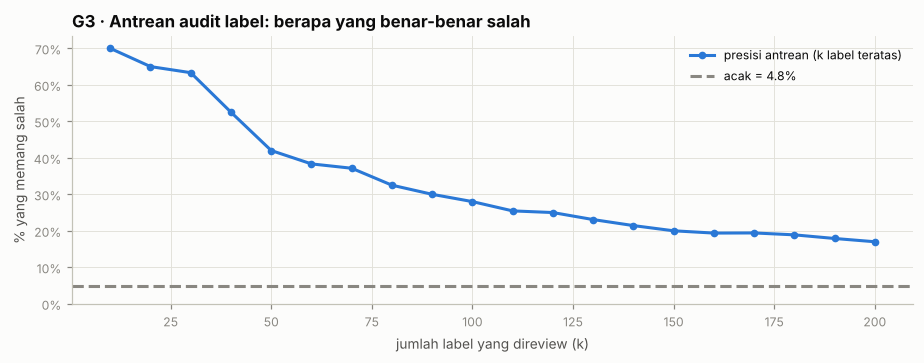

In [39]:
flip = rd('gt_client_risk').set_index('company_id').label_flipped.reindex(audit.company_id).values.astype(bool)
base_fl = flip.mean(); ks = np.arange(10, 201, 10); prec_k = [flip[:k].mean() for k in ks]
k50 = flip[:50].sum(); p_hg = stats.hypergeom.sf(k50 - 1, len(flip), flip.sum(), 50)
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.plot(ks, prec_k, color=C['s1'], marker='o', ms=4, label='presisi antrean (k label teratas)'); ax.axhline(base_fl, color=C['muted'], ls='--', label=f'acak = {base_fl:.1%}')
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); ax.set(xlabel='jumlah label yang direview (k)', ylabel='% yang memang salah', title='G3 · Antrean audit label: berapa yang benar-benar salah'); ax.set_ylim(0, None); ax.legend()
plt.tight_layout(); save_fig(fig, 'G3_label_audit'); plt.show()
print(f'Top-50: {k50} label memang salah ({k50 / 50:.0%}) vs {base_fl:.1%} bila acak → {k50 / 50 / base_fl:.1f}× lebih efisien (hipergeometrik p = {p_hg:.1e}).')
record('G3-CL', 'Antrean confident learning diperkaya label yang salah', 'hipergeometrik top-50', f'{k50}/50 vs acak {base_fl:.1%}', p_hg, 'dev', 'sample weight / review analis', gt=True)

**Arti bisnis.** Dengan mereview 50 label saja, analis menemukan hampir 9× lebih banyak rating salah dibanding sampling acak. Untuk notebook 04–05, ada dua opsi: (a) label di antrean diberi bobot lebih kecil, atau (b) diuji sensitivitas model terhadap penghapusan label tersebut. Holdout **tidak** diaudit, supaya evaluasi akhir tetap jujur.

## H. Ringkasan hipotesis, kontrak fitur, dan langkah berikutnya
### H1 · Buku besar hipotesis dengan koreksi Benjamini–Hochberg
Seluruh uji di notebook ini dikoreksi **bersama-sama** untuk *false discovery rate* 5% (Benjamini & Hochberg, 1995). Status "sesuai harapan" dipakai untuk uji yang memang diharapkan tidak signifikan: plasebo, dan uji MCAR yang dipakai untuk membenarkan imputasi sederhana.

In [40]:
hyp = pd.DataFrame(HYP)
o = np.argsort(hyp.p.values); q = hyp.p.values[o] * len(hyp) / np.arange(1, len(hyp) + 1); q = np.minimum.accumulate(q[::-1])[::-1]
hyp.loc[hyp.index[o], 'q_BH'] = np.minimum(q, 1)
hyp['status'] = np.where(hyp.harapan_nol, np.where(hyp.q_BH >= .05, 'sesuai harapan (tidak signifikan)', 'PERLU DICEK'),
                         np.where(hyp.q_BH < .05, 'didukung', 'tidak didukung'))
hyp['p'] = hyp.p.map(lambda v: f'{v:.1e}'); hyp['q_BH'] = hyp.q_BH.map(lambda v: f'{v:.1e}')
hyp.drop(columns='harapan_nol').to_csv(OUT / 'hypothesis_tests.csv', index=False)
print(hyp.status.value_counts().to_string())
display(hyp[['id', 'temuan', 'uji', 'statistik', 'p', 'q_BH', 'status', 'data', 'pakai_gt']])

status
didukung                             25
sesuai harapan (tidak signifikan)     5
tidak didukung                        5


,id,temuan,uji,statistik,p,q_BH,status,data,pakai_gt
0,D2-ebit_idr_bn,Kekosongan ebit_idr_bn bergantung pada kelas risiko (dev) (tidak signifikan ...,χ² vs kelas risiko (dev),χ²=1.22,5.4e-01,6.1e-01,sesuai harapan (tidak signifikan),dev,False
1,D2-interest_expense_idr_bn,Kekosongan interest_expense_idr_bn bergantung pada kelas risiko (dev) (tidak...,χ² vs kelas risiko (dev),χ²=1.49,4.7e-01,5.5e-01,sesuai harapan (tidak signifikan),dev,False
2,D2-channel,Kekosongan channel bergantung pada jenis transaksi (tidak signifikan = MCAR ...,χ² vs jenis transaksi,χ²=5.53,3.5e-01,4.4e-01,sesuai harapan (tidak signifikan),semua,False
3,D2-counterparty_id,Kekosongan counterparty_id bergantung pada jenis transaksi (tidak signifikan...,χ² vs jenis transaksi,χ²=4.9,4.3e-01,5.2e-01,sesuai harapan (tidak signifikan),semua,False
4,D2-MNAR,Yang tidak melapor berbeda secara teramati (lebih kecil),Mann–Whitney log karyawan,AUC karyawan 0.654,4.9e-10,1.6e-09,didukung,non-kredit + prospect (tanpa label),False
5,D2-MNAR-GT,Tanpa laporan → risiko sebenarnya lebih tinggi,χ² vs kelas risiko sebenarnya,High 49% vs 18%,4.4e-21,2.6e-20,didukung,non-kredit + prospect,True
6,E2,Porsi High berbeda antar industri,χ² industri × kelas (dev),High 4%–31%,1.8e-02,3.0e-02,didukung,dev,False
7,F1-decomp,"Daya prediksi DER ada di komponen dalam-peer, bukan level sektor",bootstrap ΔAUC (dalam − antar),AUC 0.899 vs 0.527,2.0e-03,3.9e-03,didukung,dev,False
8,F1-DER,DER relatif-peer lebih tajam dari mentah,bootstrap ΔAUC berpasangan,ΔAUC=+0.048,2.0e-03,3.9e-03,didukung,dev,False
9,F1-CR,CR relatif-peer lebih tajam dari mentah,bootstrap ΔAUC berpasangan,ΔAUC=-0.004,6.7e-01,7.4e-01,tidak didukung,dev,False


### H2 · Kontrak fitur untuk notebook 03
Setiap baris adalah "janji" yang harus dipenuhi notebook 03: definisi, alasan, jendela waktu, populasi yang bisa memakainya, dan pagar kebocorannya. Prioritas: **P1** = bukti kuat dan langsung dipakai; **P2** = bernilai untuk modul tertentu (Why Now, Opportunity); **P3** = dicoba lewat ablation.

In [41]:
S_ = scr.set_index('fitur')
ev_ = lambda f: (f"AUC {S_.loc[f, 'kekuatan']:.2f} ({'↑' if S_.loc[f, 'AUC_High'] >= .5 else '↓'} risiko), q {S_.loc[f, 'q_BH']:.0e}") if f in S_.index else ''
contract = pd.DataFrame([
    ('DER_peer_z', 'keuangan', 'z robust log(DER) per industri×ukuran; median/MAD di-fit di train', 'F1', ev_('DER_peer'), 'FY2025', 'ya', 'ya (bila melapor)', 'statistik peer hanya dari train', 'P1'),
    ('NPM_peer_z', 'keuangan', 'z robust NPM per peer', 'F1', ev_('NPM_peer'), 'FY2025', 'ya', 'ya (bila melapor)', 'idem', 'P1'),
    ('ICR_peer_z', 'keuangan', 'z robust sign·log1p(ICR) per peer; winsor 1/99', 'F1, D3', ev_('ICR_peer'), 'FY2025', 'ya', 'ya (bila melapor)', 'idem', 'P1'),
    ('CR_raw / CR_peer_z', 'keuangan', 'log(CR) mentah & relatif peer → pilih via ablation', 'F1', ev_('CR_raw'), 'FY2025', 'ya', 'ya (bila melapor)', 'idem', 'P2'),
    ('ratio_trend_2425', 'keuangan', 'Δ rasio 2025 − 2024 (DER, NPM)', 'F1', 'belum diuji', 'FY2024–25', 'ya', 'ya (bila melapor)', '—', 'P3'),
    ('has_report, is_audited', 'missing-sebagai-sinyal', 'indikator laporan tersedia / diaudit', 'D2', 'High 49% vs 18% (🔎)', 'FY2025', 'ya', 'ya', 'jangan imputasi lalu buang indikator', 'P1'),
    ('ebit_missing, interest_missing', 'missing', 'indikator kosong + imputasi median peer', 'D2', 'MCAR (p > 0,4)', 'FY2025', 'ya', 'ya', '—', 'P3'),
    ('payroll_late_share_{6,12}m', 'timing bayar', '% pembayaran gaji ≥ tgl 28', 'F2', ev_('payroll_late_share'), '6 & 12 bln s.d. cutoff', 'ya (payroll BNI)', 'TIDAK', 'jendela berakhir ≤ cutoff', 'P1'),
    ('tax_late_share_{6,12}m', 'timing bayar', '% setoran pajak > tgl 15', 'F2', ev_('tax_late_share'), '6 & 12 bln', 'ya', 'TIDAK', 'idem', 'P1'),
    ('payroll_split_share', 'timing bayar', '% bulan gaji dicicil (> 1 batch)', 'F2', ev_('payroll_split_share'), '12 bln', 'ya', 'TIDAK', 'idem', 'P2'),
    ('timing_delta', 'timing bayar', 'nilai 6 bln terakhir − 12 bln sebelumnya (perubahan perilaku)', 'F2', 'belum diuji', '18 bln', 'ya', 'TIDAK', 'idem', 'P2'),
    ('out_in_ratio_6m', 'arus kas', 'outflow ÷ inflow 6 bln', 'F2', ev_('out_in_ratio_6m'), '6 bln', 'ya', 'TIDAK', '—', 'P1'),
    ('inflow_cv_sa', 'arus kas', 'koefisien variasi inflow SETELAH koreksi musiman (F5)', 'F5', ev_('inflow_cv'), '12 bln', 'ya', 'sebagian', '—', 'P2'),
    ('inflow_growth_sa', 'arus kas', 'pertumbuhan inflow terkoreksi Lebaran per industri', 'F5', ev_('inflow_growth_h1'), '6 vs 6 bln', 'ya', 'sebagian', 'model musiman di-fit di train', 'P2'),
    ('max_inflow_z_12m', 'anomali', 'z robust lonjakan inflow bulanan maksimum', 'D3', 'recall 96% lonjakan (🔎)', '12 bln', 'ya', 'sebagian', '—', 'P2 (Why Now)'),
    ('utilization', 'fasilitas', 'outstanding ÷ limit (kolom berperan fitur)', 'G1', ev_('utilization'), 'per cutoff', 'nasabah kredit', 'TIDAK', 'BUKAN proxy-label; 4 kolom proxy tetap dilarang', 'P1'),
    ('top_buyer_share, n_buyers, buyer_HHI', 'jaringan', 'porsi pembeli terbesar dari relasi aktif (kontinu, TANPA ambang)', 'F3', ev_('top_buyer_share'), 'per cutoff', 'ya', 'ya', 'hanya relasi start ≤ cutoff', 'P1'),
    ('exp_shocked_anchor', 'jaringan', 'Σ dependency_share ke anchor dengan patahan tren z < −3,5', 'F4', 'ρ −0,42 thd Δinflow; plasebo datar', 'bulanan', 'ya', 'ya', 'detektor anchor memakai data ≤ bulan berjalan', 'P2 (Why Now)'),
    ('debtrank_2hop', 'jaringan', 'paparan tidak langsung 2 lapis (DebtRank)', 'F4', 'belum diuji', 'bulanan', 'ya', 'ya', 'idem', 'P3'),
    ('degree, pagerank, core_number', 'jaringan', 'sentralitas graf relasi aktif', 'F8', ev_('degree'), 'per cutoff', 'ya', 'ya', '—', 'P3'),
    ('n_nonbni_partners', 'peluang', 'jumlah mitra non-BNI (akuisisi ekosistem)', 'F8', 'lead list', 'per cutoff', 'ya', 'ya', '—', 'P2 (Opportunity)'),
    ('capture_ratio, wallet_gap_idr', 'peluang', 'inflow BNI ÷ omzet; (1 − capture) × omzet', 'F6', 'ρ 0,96 thd wallet share (🔎)', 'FY2025', 'ya', 'TIDAK', '—', 'P1 (Opportunity)'),
    ('divergence_z', 'peluang/retensi', 'z robust (Δlog inflow − Δlog omzet)', 'F6', 'AUC 0,96 thd erosi (🔎)', 'H1-26 vs H1-25', 'ya', 'TIDAK', '—', 'P1 (Why Now)'),
    ('district_penetration, district_poi, has_branch_district', 'geografi', 'atribut kecamatan menggantikan one-hot 40 level', 'F7, D4', 'p 0,005 (padat tanpa cabang)', 'per cutoff', 'ya', 'ya', 'penetrasi dihitung tanpa target', 'P2 (Opportunity)'),
    ('peer_adoption_<produk>, n_products', 'produk', 'adopsi produk oleh peer; jumlah produk aktif', 'F7', 'lift 1,57× kebutuhan (🔎)', 'per cutoff', 'ya', 'sebagian', 'peer rate di-fit di train', 'P1 (Opportunity)'),
    ('issue_<id>_negex', 'teks', 'flag masalah dari catatan RM, sadar-negasi', 'F9', 'presisi 0,70 vs 0,61 naif (🔎)', '6 bln', 'yang dikunjungi', 'yang dikunjungi', 'catatan ≤ cutoff', 'P2 (GenAI)'),
    ('industry one-hot, size ordinal, city one-hot', 'profil', 'lihat encoding_plan.csv', 'D4, E2', 'χ² p 0,02 (industri)', '—', 'ya', 'ya', '—', 'P1'),
    ('log_emp, age', 'profil', 'log karyawan; umur perusahaan', 'G1', ev_('log_emp'), '—', 'ya', 'ya', '—', 'P3'),
    ('inflow_resid_z', 'anomali (panel)', 'z robust log inflow setelah buang level perusahaan & musim industri', 'F10a', f"base rate |z|>3,5 {br_pt:.1%}", 'bulanan, online', 'ya', 'TIDAK', 'median/MAD dari bulan ≤ t saja', 'P1 (anomali)'),
    ('spike_flag', 'anomali (panel)', 'z bulan ini > 3,5 tetapi rata-rata 3 bln tidak naik', 'F10c', f"AUC lonjakan {M_auc.loc['③ aturan: |z| bulanan maks', EV_LBL['spike']]:.2f} (🔎)", 'bulanan, online', 'ya', 'TIDAK', 'tidak boleh melihat t+1', 'P1 (anomali)'),
    ('cusum_up, cusum_down, drop_3v6', 'anomali (panel)', 'akumulasi penyimpangan (CUSUM) & inflow 3 bln vs 6 bln sebelumnya', 'F10c', f"AUC ekspansi {M_auc.loc['skor level shift naik', EV_LBL['expansion']]:.2f}, erosi {M_auc.loc['① aturan: inflow 3 bln turun vs 6 bln (online)', EV_LBL['wallet_erosion']]:.2f} (🔎)", 'bulanan, online', 'ya', 'TIDAK', 'jendela berakhir di t', 'P1 (anomali)'),
    ('buyer_exit_share', 'anomali (panel)', 'porsi inflow counterparty (≥ 15%) yang berhenti ≥ 2 bulan', 'F10e', f"AUC buyer exit {M_auc.loc['porsi pembeli berhenti', EV_LBL['buyer_exit']]:.2f} (🔎)", 'bulanan, online', 'ya', 'TIDAK', 'JANGAN pakai relationship_end (pencatatan terlambat / trivial)', 'P1 (anomali)'),
    ('n_active_counterparties, delta', 'anomali (panel)', 'jumlah counterparty aktif 3 bln & perubahannya', 'F10e', 'belum diuji', 'bulanan, online', 'ya', 'TIDAK', '—', 'P2 (anomali)'),
    ('late_share_3m, timing_delta', 'anomali (panel)', '% gaji/pajak telat 3 bln; selisih 6 vs 12 bln', 'F10h', f"lead ±3 bln; AUC distress {M_auc.loc['Δ timing bayar 6 vs 12 bln (F2)', EV_LBL['distress']]:.2f} (🔎)", 'bulanan, online', 'ya (payroll BNI)', 'TIDAK', '—', 'P1 (anomali)'),
    ('out_in_ratio_delta', 'anomali (panel)', 'rasio outflow/inflow 6 bln − 12 bln sebelumnya', 'F10g', f"AUC distress {M_auc.loc['Δ rasio outflow/inflow', EV_LBL['distress']]:.2f} (🔎)", 'bulanan, online', 'ya', 'TIDAK', '—', 'P2 (anomali)'),
], columns=['fitur', 'kelompok', 'definisi', 'sumber', 'bukti', 'jendela', 'nasabah', 'prospect', 'pagar_kebocoran', 'prioritas'])
contract.to_csv(OUT / 'feature_contract.csv', index=False)
print(contract.prioritas.str[:2].value_counts().sort_index().to_string()); display(contract)

prioritas
P1    18
P2    12
P3     5


,fitur,kelompok,definisi,sumber,bukti,jendela,nasabah,prospect,pagar_kebocoran,prioritas
0,DER_peer_z,keuangan,z robust log(DER) per industri×ukuran; median/MAD di-fit di train,F1,"AUC 0.90 (↑ risiko), q 3e-39",FY2025,ya,ya (bila melapor),statistik peer hanya dari train,P1
1,NPM_peer_z,keuangan,z robust NPM per peer,F1,"AUC 0.87 (↓ risiko), q 1e-33",FY2025,ya,ya (bila melapor),idem,P1
2,ICR_peer_z,keuangan,z robust sign·log1p(ICR) per peer; winsor 1/99,"F1, D3","AUC 0.86 (↓ risiko), q 6e-31",FY2025,ya,ya (bila melapor),idem,P1
3,CR_raw / CR_peer_z,keuangan,log(CR) mentah & relatif peer → pilih via ablation,F1,"AUC 0.87 (↓ risiko), q 2e-33",FY2025,ya,ya (bila melapor),idem,P2
4,ratio_trend_2425,keuangan,"Δ rasio 2025 − 2024 (DER, NPM)",F1,belum diuji,FY2024–25,ya,ya (bila melapor),—,P3
5,"has_report, is_audited",missing-sebagai-sinyal,indikator laporan tersedia / diaudit,D2,High 49% vs 18% (🔎),FY2025,ya,ya,jangan imputasi lalu buang indikator,P1
6,"ebit_missing, interest_missing",missing,indikator kosong + imputasi median peer,D2,"MCAR (p > 0,4)",FY2025,ya,ya,—,P3
7,"payroll_late_share_{6,12}m",timing bayar,% pembayaran gaji ≥ tgl 28,F2,"AUC 0.85 (↑ risiko), q 3e-31",6 & 12 bln s.d. cutoff,ya (payroll BNI),TIDAK,jendela berakhir ≤ cutoff,P1
8,"tax_late_share_{6,12}m",timing bayar,% setoran pajak > tgl 15,F2,"AUC 0.86 (↑ risiko), q 1e-33",6 & 12 bln,ya,TIDAK,idem,P1
9,payroll_split_share,timing bayar,% bulan gaji dicicil (> 1 batch),F2,"AUC 0.57 (↑ risiko), q 3e-08",12 bln,ya,TIDAK,idem,P2


### H3 · Simpan hasil

In [42]:
P_out = P.drop(columns=['split'])
P_out.to_csv(INTERIM / 'eda_probe_features.csv')                     # tanpa label; definisi final di notebook 03
anc.to_csv(OUT / 'anchors_detected.csv', index=False); eco.head(200).to_csv(OUT / 'ecosystem_leads.csv')
ws.to_csv(OUT / 'whitespace_districts.csv'); f5.to_csv(OUT / 'lebaran_seasonality_by_industry.csv', index=False)
tx_save = tx.drop(columns=['ym', 'day'])
try:
    tx_save.to_parquet(INTERIM / 'transactions_clean.parquet', index=False); tx_file = 'transactions_clean.parquet'
except Exception:
    tx_save.to_csv(INTERIM / 'transactions_clean.csv.gz', index=False, compression='gzip'); tx_file = 'transactions_clean.csv.gz'
print('data/interim/ :', sorted(p_.name for p_ in INTERIM.iterdir()))
print('outputs/02_eda/:', sorted(p_.name for p_ in OUT.iterdir() if p_.is_file()))
print('figures/      :', len(list(FIG.glob('*.png'))), 'grafik')

data/interim/ : ['eda_probe_features.csv', 'split.csv', 'transactions_clean.csv.gz']
outputs/02_eda/: ['anchors_detected.csv', 'anomaly_signal_event_auc.csv', 'cleaning_log.csv', 'ecosystem_leads.csv', 'encoding_plan.csv', 'feature_contract.csv', 'feature_screening.csv', 'hypothesis_tests.csv', 'label_audit_queue.csv', 'lebaran_seasonality_by_industry.csv', 'whitespace_districts.csv']
figures/      : 21 grafik


### H4 · Ringkasan untuk presentasi Hari 2

In [43]:
summary = f"""
| # | Temuan | Angka kunci | Untuk |
|---|---|---|---|
| D | Kualitas data | {len(tx_raw) - len(tx):,} transaksi dibuang (duplikat & nol); laporan hilang **MNAR**: High {t_.loc['tanpa laporan', 'High']:.0%} vs {t_.loc['ada laporan', 'High']:.0%} 🔎 | `has_report` sebagai fitur |
| F1 | Level rasio ditentukan sektor | AUC DER dalam-peer {a_wth:.2f} vs antar-sektor {a_btw:.2f} | rasio relatif-peer |
| F2 | Timing gaji & pajak = sinyal dini | AUC pajak telat {S_.loc['tax_late_share', 'AUC_High']:.2f}, gaji telat {S_.loc['payroll_late_share', 'AUC_High']:.2f} | early warning tanpa laporan keuangan |
| F3 | Konsentrasi pembeli menaikkan risiko, tanpa ambang | LR p {p_lin:.0e}; ambang p {p_tau:.2f} | fitur kontinu |
| F4 | Efek berantai anchor | 2 anchor terdeteksi dari data; paparan > 20% → inflow {np.expm1(did):+.0%}; plasebo datar | Why Now / early warning |
| F5 | Lebaran bergerak | regresor hari raya signifikan di {len(sig_)} industri; THR {thr_ratio:.1f}× | koreksi musiman |
| F6 | Erosi share of wallet | median capture {w.capture_2025.median():.0%}; {w.erosi_flag.sum()} nasabah divergen (presisi 🔎 81%) | retensi & Opportunity |
| F7 | White-space | kawasan industri tanpa cabang: penetrasi {ws.penetrasi.median():.0%} vs {ctrl.penetrasi.median():.0%}; {int(gap.values.sum())} celah produk | ekspansi & cross-sell |
| F8 | Jaringan = geografi | NMI kota {nmi_city:.2f} vs industri {nmi_ind:.2f}; homophily risiko p {p_as:.2f} | jangan andalkan risiko tetangga |
| F9 | Negasi di catatan RM | negasi salah-baca 100% → {f9.loc['negex', 'negasi_salah_dibaca']:.0%}; sisanya implisit | alasan memakai LLM |
| F10 | Anomali per jenis kejadian | aturan 1 baris cukup untuk lonjakan & erosi; sinyal khusus untuk buyer exit (AUC {M_auc.loc['porsi pembeli berhenti', EV_LBL['buyer_exit']]:.2f}) & efek berantai; ML untuk distress & ekspansi; timing bayar lead ±3 bln (🔎) | desain modul Why Now |
| G2 | Prospect ≠ nasabah | C2ST AUC {g2.AUC_C2ST.iloc[0]:.2f} (transaksi) vs {g2.AUC_C2ST.iloc[2]:.2f} (rasio peer) | dua set fitur |
| G3 | Audit label | top-50 antrean: {k50 / 50:.0%} salah vs {base_fl:.0%} acak | review analis / bobot |
| — | Probe | macro-F1 OOF {res_probe['fitur hasil EDA'][1]:.2f} (fitur EDA) vs {res_probe['keuangan mentah saja'][1]:.2f} (keuangan mentah); oracle ≈ 0,83 | baseline notebook 04 |
"""
display(Markdown(summary))


| # | Temuan | Angka kunci | Untuk |
|---|---|---|---|
| D | Kualitas data | 3,330 transaksi dibuang (duplikat & nol); laporan hilang **MNAR**: High 49% vs 18% 🔎 | `has_report` sebagai fitur |
| F1 | Level rasio ditentukan sektor | AUC DER dalam-peer 0.90 vs antar-sektor 0.53 | rasio relatif-peer |
| F2 | Timing gaji & pajak = sinyal dini | AUC pajak telat 0.86, gaji telat 0.85 | early warning tanpa laporan keuangan |
| F3 | Konsentrasi pembeli menaikkan risiko, tanpa ambang | LR p 9e-06; ambang p 0.99 | fitur kontinu |
| F4 | Efek berantai anchor | 2 anchor terdeteksi dari data; paparan > 20% → inflow -21%; plasebo datar | Why Now / early warning |
| F5 | Lebaran bergerak | regresor hari raya signifikan di 6 industri; THR 1.9× | koreksi musiman |
| F6 | Erosi share of wallet | median capture 56%; 69 nasabah divergen (presisi 🔎 81%) | retensi & Opportunity |
| F7 | White-space | kawasan industri tanpa cabang: penetrasi 40% vs 85%; 592 celah produk | ekspansi & cross-sell |
| F8 | Jaringan = geografi | NMI kota 0.21 vs industri 0.03; homophily risiko p 0.72 | jangan andalkan risiko tetangga |
| F9 | Negasi di catatan RM | negasi salah-baca 100% → 35%; sisanya implisit | alasan memakai LLM |
| F10 | Anomali per jenis kejadian | aturan 1 baris cukup untuk lonjakan & erosi; sinyal khusus untuk buyer exit (AUC 0.99) & efek berantai; ML untuk distress & ekspansi; timing bayar lead ±3 bln (🔎) | desain modul Why Now |
| G2 | Prospect ≠ nasabah | C2ST AUC 1.00 (transaksi) vs 0.58 (rasio peer) | dua set fitur |
| G3 | Audit label | top-50 antrean: 42% salah vs 5% acak | review analis / bobot |
| — | Probe | macro-F1 OOF 0.72 (fitur EDA) vs 0.57 (keuangan mentah); oracle ≈ 0,83 | baseline notebook 04 |


**Langkah berikutnya**
1. **Notebook 03 — Feature Engineering:** bangun fitur P1 sesuai `feature_contract.csv` sebagai pipeline yang di-*fit* di train (statistik peer, model musiman, peer adoption). Lakukan ablation per kelompok (keuangan / timing / arus kas / jaringan / profil), dan buat set **nasabah** vs **portabel**.
2. **Notebook 04 — Baseline:** logistic regression + gradient boosting dengan `split.csv` yang sama, metrik macro-F1 dan recall High. Probe di G3 (macro-F1 ±0,72) adalah titik awal yang harus dikalahkan.
3. **Notebook 05:** cost-sensitive learning (class weight vs SMOTE), *importance weighting* untuk prospect (G2), dan sensitivitas terhadap antrean label (G3).
4. **GenAI:** ekstraksi masalah dari catatan RM berbasis LLM, dievaluasi terhadap baseline NegEx (F9).

**Batasan yang perlu disampaikan saat presentasi.** Data ini sintetis, sehingga pola yang ditemukan adalah pola yang **ditanam** di notebook 01. Nilai EDA ini ada pada bukti bahwa **metodenya** sanggup memulihkan pola tersebut, termasuk menolak pola yang tidak ada (ambang konsentrasi, homophily risiko). Angka-angka ini bukan klaim tentang nasabah BNI yang sebenarnya.

## Daftar pustaka
Status "✔" = metadata DOI dicocokkan ke Crossref pada 10 Okt 2026. Status "○" = belum dicek; cek dulu sebelum dikutip di slide. Daftar yang sama disimpan di `outputs/02_eda/references.csv` dan `REFERENCES.md`, lengkap dengan kolom **untuk apa** dan **bagian** yang memakainya.

In [44]:
REFS = [  # (kunci, rujukan lengkap, doi/arXiv, bagian, untuk apa, status)
    ('Kapoor2023', 'Kapoor, S. & Narayanan, A. (2023). Leakage and the reproducibility crisis in machine-learning-based science. Patterns, 4(9), 100804.', '10.1016/j.patter.2023.100804', 'C', 'alasan mengunci holdout sebelum melihat label', '✔'),
    ('Kaufman2012', 'Kaufman, S., Rosset, S., Perlich, C. & Stitelman, O. (2012). Leakage in data mining: Formulation, detection, and avoidance. ACM TKDD, 6(4).', '10.1145/2382577.2382579', 'C', 'definisi kebocoran data', '✔'),
    ('Rubin1976', 'Rubin, D. B. (1976). Inference and missing data. Biometrika, 63(3), 581–592.', '10.1093/biomet/63.3.581', 'D2', 'kerangka MCAR / MAR / MNAR', '✔'),
    ('Little1988', 'Little, R. J. A. (1988). A test of missing completely at random for multivariate data with missing values. JASA, 83(404).', '10.1080/01621459.1988.10478722', 'D2', 'gagasan uji MCAR', '✔'),
    ('Sperrin2020', 'Sperrin, M., Martin, G. P., Sisk, R. & Peek, N. (2020). Missing data should be handled differently for prediction than for description or causal explanation. J. Clin. Epidemiol., 125.', '10.1016/j.jclinepi.2020.03.028', 'D2', 'indikator "kosong" sebagai fitur prediksi', '✔'),
    ('Leys2013', 'Leys, C., Ley, C., Klein, O., Bernard, P. & Licata, L. (2013). Detecting outliers: Do not use standard deviation around the mean, use absolute deviation around the median. JESP, 49(4).', '10.1016/j.jesp.2013.03.013', 'D3, F10', 'z robust median/MAD', '✔'),
    ('Iglewicz1993', 'Iglewicz, B. & Hoaglin, D. C. (1993). How to Detect and Handle Outliers. ASQC Quality Press.', '', 'D3, F10', 'ambang |z| > 3,5', 'buku'),
    ('Pargent2022', 'Pargent, F., Pfisterer, F., Thomas, J. & Bischl, B. (2022). Regularized target encoding outperforms traditional methods in supervised machine learning with high cardinality features. Computational Statistics, 37.', '10.1007/s00180-022-01207-6', 'D4', 'encoding kategori berkardinalitas tinggi', '○'),
    ('Simpson1951', 'Simpson, E. H. (1951). The interpretation of interaction in contingency tables. JRSS B, 13(2).', '10.1111/j.2517-6161.1951.tb00088.x', 'F1', 'paradoks Simpson → rasio relatif-peer', '✔'),
    ('Efron1979', 'Efron, B. (1979). Bootstrap methods: Another look at the jackknife. Annals of Statistics, 7(1).', '10.1214/aos/1176344552', 'F1–G1', 'rentang kepercayaan bootstrap', '✔'),
    ('Muggeo2003', 'Muggeo, V. M. R. (2003). Estimating regression models with unknown break-points. Statistics in Medicine, 22(19).', '10.1002/sim.1545', 'F3', 'regresi tersegmentasi untuk uji ambang', '✔'),
    ('Bernal2017', 'Bernal, J. L., Cummins, S. & Gasparrini, A. (2017). Interrupted time series regression for the evaluation of public health interventions: a tutorial. Int. J. Epidemiol., 46(1).', '10.1093/ije/dyw098', 'F4', 'deteksi patahan tren anchor (ITS)', '✔'),
    ('Battiston2012', 'Battiston, S., Puliga, M., Kaushik, R., Tasca, P. & Caldarelli, G. (2012). DebtRank: Too central to fail? Scientific Reports, 2, 541.', '10.1038/srep00541', 'F4', 'penularan lewat ketergantungan', '✔'),
    ('Bell1983', 'Bell, W. R. & Hillmer, S. C. (1983). Modeling time series with calendar variation. JASA, 78(383).', '10.1080/01621459.1983.10478005', 'F5', 'regresor hari raya bergerak', '✔'),
    ('Findley1998', 'Findley, D. F., Monsell, B. C., Bell, W. R., Otto, M. C. & Chen, B.-C. (1998). New capabilities and methods of the X-12-ARIMA seasonal-adjustment program. JBES, 16(2).', '10.1080/07350015.1998.10524743', 'F5', 'praktik statistik resmi untuk hari raya', '✔'),
    ('Du2007', 'Du, R. Y., Kamakura, W. A. & Mela, C. F. (2007). Size and share of customer wallet. Journal of Marketing, 71(2), 94–113.', '10.1509/jmkg.71.2.094', 'F6', 'konsep share of wallet', '✔'),
    ('Brin1997', 'Brin, S., Motwani, R., Ullman, J. D. & Tsur, S. (1997). Dynamic itemset counting and implication rules for market basket data. SIGMOD 1997.', '10.1145/253262.253325', 'F7', 'ukuran lift co-holding produk', '○'),
    ('Blondel2008', 'Blondel, V. D., Guillaume, J.-L., Lambiotte, R. & Lefebvre, E. (2008). Fast unfolding of communities in large networks. J. Stat. Mech., P10008.', '10.1088/1742-5468/2008/10/P10008', 'F8', 'deteksi komunitas Louvain', '○'),
    ('Newman2003', 'Newman, M. E. J. (2003). Mixing patterns in networks. Physical Review E, 67, 026126.', '10.1103/PhysRevE.67.026126', 'F8', 'asortativitas / homophily', '○'),
    ('Chapman2001', 'Chapman, W. W. dkk. (2001). A simple algorithm for identifying negated findings and diseases in discharge summaries. J. Biomed. Inform., 34(5).', '10.1006/jbin.2001.1029', 'F9', 'deteksi negasi (NegEx)', '✔'),
    ('Chandola2009', 'Chandola, V., Banerjee, A. & Kumar, V. (2009). Anomaly detection: A survey. ACM Computing Surveys, 41(3).', '10.1145/1541880.1541882', 'F10', 'taksonomi anomali titik / kolektif / kontekstual', '✔'),
    ('Page1954', 'Page, E. S. (1954). Continuous inspection schemes. Biometrika, 41(1/2), 100–115.', '10.1093/biomet/41.1-2.100', 'F10', 'CUSUM untuk perubahan level', '✔'),
    ('Killick2012', 'Killick, R., Fearnhead, P. & Eckley, I. A. (2012). Optimal detection of changepoints with a linear computational cost. JASA, 107(500).', '10.1080/01621459.2012.737745', 'F10', 'pencarian titik patah (change point)', '✔'),
    ('Wu2021', 'Wu, R. & Keogh, E. J. (2021). Current time series anomaly detection benchmarks are flawed and are creating the illusion of progress. IEEE TKDE.', '10.1109/TKDE.2021.3112126', 'F10', 'uji trivialitas aturan satu baris', '✔'),
    ('Chatterjee2021', 'Chatterjee, S. (2021). A new coefficient of correlation. JASA, 116(536).', '10.1080/01621459.2020.1758115', 'G1', 'korelasi ξ untuk penyaringan fitur', '✔'),
    ('Benjamini1995', 'Benjamini, Y. & Hochberg, Y. (1995). Controlling the false discovery rate: A practical and powerful approach to multiple testing. JRSS B, 57(1).', '10.1111/j.2517-6161.1995.tb02031.x', 'G1, H1', 'koreksi FDR seluruh uji', '✔'),
    ('LopezPaz2017', 'Lopez-Paz, D. & Oquab, M. (2017). Revisiting classifier two-sample tests. ICLR 2017.', 'arXiv:1610.06545', 'G2', 'uji pergeseran nasabah → prospect', '○'),
    ('Shimodaira2000', 'Shimodaira, H. (2000). Improving predictive inference under covariate shift by weighting the log-likelihood function. JSPI, 90(2).', '10.1016/S0378-3758(00)00115-4', 'G2', 'importance weighting untuk prospect', '✔'),
    ('Northcutt2021', 'Northcutt, C., Jiang, L. & Chuang, I. (2021). Confident learning: Estimating uncertainty in dataset labels. JAIR, 70.', '10.1613/jair.1.12125', 'G3', 'audit label rating', '✔'),
]
refs = pd.DataFrame(REFS, columns=['kunci', 'rujukan', 'doi', 'dipakai_di', 'untuk_apa', 'status'])
refs['tautan'] = np.where(refs.doi.str.startswith('10.'), 'https://doi.org/' + refs.doi, np.where(refs.doi.str.startswith('arXiv'), 'https://arxiv.org/abs/' + refs.doi.str.replace('arXiv:', ''), ''))
refs.to_csv(OUT / 'references.csv', index=False)
with open(OUT / 'REFERENCES.md', 'w', encoding='utf-8') as fh:
    fh.write('# Rujukan — Notebook 02 EDA\n\n')
    fh.write('Status: ✔ = metadata DOI dicocokkan ke Crossref (10 Okt 2026) · ○ = belum dicek, verifikasi sebelum dikutip · buku = tanpa DOI.\n\n')
    fh.write('| Kunci | Bagian | Untuk apa | Rujukan | Tautan | Status |\n|---|---|---|---|---|---|\n')
    for r in refs.itertuples(): fh.write(f"| {r.kunci} | {r.dipakai_di} | {r.untuk_apa} | {r.rujukan} | {r.tautan or '—'} | {r.status} |\n")
print(f"{len(refs)} rujukan · {(refs.status == '✔').sum()} dicek ke Crossref · {(refs.status == '○').sum()} belum dicek")
display(refs[['kunci', 'dipakai_di', 'untuk_apa', 'tautan', 'status']])

29 rujukan · 23 dicek ke Crossref · 5 belum dicek


,kunci,dipakai_di,untuk_apa,tautan,status
0,Kapoor2023,C,alasan mengunci holdout sebelum melihat label,https://doi.org/10.1016/j.patter.2023.100804,✔
1,Kaufman2012,C,definisi kebocoran data,https://doi.org/10.1145/2382577.2382579,✔
2,Rubin1976,D2,kerangka MCAR / MAR / MNAR,https://doi.org/10.1093/biomet/63.3.581,✔
3,Little1988,D2,gagasan uji MCAR,https://doi.org/10.1080/01621459.1988.10478722,✔
4,Sperrin2020,D2,"indikator ""kosong"" sebagai fitur prediksi",https://doi.org/10.1016/j.jclinepi.2020.03.028,✔
5,Leys2013,"D3, F10",z robust median/MAD,https://doi.org/10.1016/j.jesp.2013.03.013,✔
6,Iglewicz1993,"D3, F10","ambang |z| > 3,5",,buku
7,Pargent2022,D4,encoding kategori berkardinalitas tinggi,https://doi.org/10.1007/s00180-022-01207-6,○
8,Simpson1951,F1,paradoks Simpson → rasio relatif-peer,https://doi.org/10.1111/j.2517-6161.1951.tb00088.x,✔
9,Efron1979,F1–G1,rentang kepercayaan bootstrap,https://doi.org/10.1214/aos/1176344552,✔
